In [1]:
# @@ENV@@ — Keras backend, visible GPU and global seed
import os

os.environ["KERAS_BACKEND"] = "tensorflow"
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import tensorflow as tf

gpus = tf.config.list_physical_devices("GPU")

for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)


import kagglesdk.kaggle_env as kaggle_env

if not hasattr(kaggle_env, "get_web_endpoint"):
    kaggle_env.get_web_endpoint = kaggle_env.get_endpoint

import kagglehub
import keras
import keras_cv

print("GPUs:", gpus)

2026-11-16 09:06:49.379119: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1794816409.392234  524176 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1794816409.396321  524176 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### **Setup**

In [2]:
# @@CFG@@ — the knobs the post-hoc needs; split and sampling live in the frozen frames
import keras
class CFG:
    seed = 74
    image_size = (256, 256)
    batch_size = 64
    num_classes = 1
    xai_balance = "equal"   # half per class: the sample of the study
    xai_n = None            # largest balanced sample allowed by the frozen split
    shape_top_k = 2         # raw features selected for stability and SHAP-LORE agreement
keras.utils.set_random_seed(CFG.seed)

In [3]:
# @@LIBS@@ - Common libraries used across the post-hoc pipeline.
import glob, json, gc, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

In [4]:
# @@PATHS@@ — dataset, variant and row identity are declared HERE; every path derives from them
import sys, os

BASE_PATH = os.environ.get("DUM_BASE", os.environ.get("ISIC24_BASE", "/mnt/disk1/home/cgiovannoni/mod-attendance"))
sys.path.insert(0, os.path.join(BASE_PATH, "src")) if os.path.join(BASE_PATH, "src") not in sys.path else None

from isic24 import paths as pth
from isic24 import xai_subset as xs

pth.DATASET, pth.VARIANT = "cmmd", "processed" 
xs.ID_COL = "image_id"                             # row identity column of this dataset

DATA_DIR = str(pth.data_dir())                    # images (hdf5) live at dataset level
DATA_PATH = str(pth.data_path())                  # metadata of this variant
ART_PATH = str(pth.art_path())
FEATURE_SPACE_PATH = os.path.join(ART_PATH, "feature_space")
RUNS_PATH = os.path.join(ART_PATH, "runs")
SUMMARIES_PATH = os.path.join(ART_PATH, "summaries")

TRAIN_META = os.path.join(DATA_PATH, "train-metadata.parquet")
TEST_META = os.path.join(DATA_PATH, "test-metadata.parquet")
TRAIN_HDF5 = os.path.join(DATA_DIR, "train-image.hdf5")
TEST_HDF5 = os.path.join(DATA_DIR, "test-image.hdf5")

print(f"dataset={pth.DATASET}/{pth.VARIANT} | id={xs.ID_COL}\n  data {DATA_PATH}\n  art  {ART_PATH}")

dataset=cmmd/processed | id=image_id
  data /mnt/disk1/home/cgiovannoni/mod-attendance/data/cmmd/processed
  art  /mnt/disk1/home/cgiovannoni/mod-attendance/artifacts/cmmd/processed


In [5]:
# @@FRAMES@@ — load the frames the training froze; this notebook never rebuilds the split
import json as _json
import pandas as pd

validation_df = pd.read_parquet(os.path.join(ART_PATH, "evaluation_frame.parquet"))
training_df = pd.read_parquet(os.path.join(ART_PATH, "training_frame.parquet"))

_snap = _json.load(open(os.path.join(ART_PATH, "validation_snapshot.json")))
_live = [str(v) for v in xs.row_ids(validation_df)]
_frozen = [str(v) for v in _snap["row_ids"]]
if _live != _frozen:
    _lost, _new = set(_frozen) - set(_live), set(_live) - set(_frozen)
    raise RuntimeError(
        f"[FRAMES] the evaluation frame ({len(_live)} rows) is not the frozen validation "
        f"({len(_frozen)} rows): "
        + ("the same rows in a DIFFERENT ORDER." if not (_lost or _new)
           else f"{len(_lost)} missing, {len(_new)} new.")
        + " Every val_index in the XAI artifacts is a position into the frozen frame.")

print(f"[FRAMES] evaluation {validation_df.shape}, {int(validation_df.target.sum())} positive, "
      f"prevalence {validation_df.target.mean():.4f} | training {training_df.shape}")

[FRAMES] evaluation (596, 10), 420 positive, prevalence 0.7047 | training (2390, 10)


In [6]:
# @@CUSTOM_LAYERS@@ — register the shared Keras layers, so load_model needs no custom_objects
import sys, os
_src = os.path.join(BASE_PATH, "src")
if _src not in sys.path:
    sys.path.insert(0, _src)

from isic24.mod_attendance import (
    ConstantScale, ScalarMultiply, LearnableAlpha, FusionWithGamma, GateEntropyLoss)

In [7]:
# @@PARAMETERS@@ — canonical study dirs, budgets and the run selection of the loops below
CANONICAL = {
    "vanilla":             os.path.join(RUNS_PATH, "vanilla", "20261015-114125"),
    "fixed_scaling":       os.path.join(RUNS_PATH, "fixed_scaling", "20261016-234343"),
    "learnable_scaling":   os.path.join(RUNS_PATH, "learnable_scaling", "20261020-224124"),
    "loss_regularization": os.path.join(RUNS_PATH, "loss_regularization", "20261019-233600"),
    "controlled_fusion":   os.path.join(RUNS_PATH, "controlled_fusion", "20261020-063421"),
    "adaptive_gating":     os.path.join(RUNS_PATH, "adaptive_gating", "20261020-020650"),
}

TRAINING_SEEDS = [8, 47, 53, 71, 90, 101]
EXPECTED_SETTINGS = {
    "vanilla": 1, "fixed_scaling": 9, "learnable_scaling": 5,
    "loss_regularization": 5, "controlled_fusion": 1, "adaptive_gating": 5,
}
N_CANONICAL_RUNS = len(TRAINING_SEEDS) * sum(EXPECTED_SETTINGS.values())
_runs = {i: sorted(glob.glob(os.path.join(d, "*", "*", "config.json")))
         for i, d in CANONICAL.items()}
_configs = {c: json.load(open(c)) for cs in _runs.values() for c in cs}
_spaces = {c: cfg.get("feature_space_file") for c, cfg in _configs.items()}
_space_fps = {c: cfg.get("feature_space_fingerprint") for c, cfg in _configs.items()}
for _impl, _cs in _runs.items():
    _cfgs = pd.DataFrame([_configs[c] for c in _cs])
    assert len(_cfgs) == len(TRAINING_SEEDS) * EXPECTED_SETTINGS[_impl], (
        f"{_impl}: incomplete training grid; finish the selected training sweep first"
    )
    assert _cfgs.run_id.is_unique and _cfgs.best_val_auc.notna().all(), (
        f"{_impl}: duplicate or unfinished runs"
    )
    assert _cfgs.setting_tag.nunique() == EXPECTED_SETTINGS[_impl], _impl
    assert not _cfgs.duplicated(["setting_tag", "seed"]).any(), _impl
    assert _cfgs.groupby("setting_tag").seed.apply(
        lambda values: set(values) == set(TRAINING_SEEDS)
    ).all(), f"{_impl}: seed grid mismatch"
    if _impl == "adaptive_gating":
        _weights = _cfgs.groupby("setting_tag").entropy_weight
        assert _weights.nunique().eq(1).all(), "Mixed entropy weights within a setting"
        assert set(_weights.first()) == {0.0, 1e-4, 1e-3, 1e-2, 1e-1}, "Entropy grid mismatch"
        assert _weights.first().loc["base"] == 1e-4, "Wrong reference entropy weight"
    print(f"{_impl}: {len(_cs)} completed runs, {EXPECTED_SETTINGS[_impl]} settings")

assert sum(map(len, _runs.values())) == N_CANONICAL_RUNS, (
    f"Expected {N_CANONICAL_RUNS} canonical runs"
)
assert None not in _spaces.values() and len(set(_spaces.values())) == 1, (
    "Canonical runs must declare one shared FeatureSpace file"
)
assert len(set(_space_fps.values()) - {None}) <= 1, (
    "Canonical runs declare conflicting FeatureSpace fingerprints"
)

cf_study_dir = CANONICAL["controlled_fusion"]   # gamma sweep writes here
ag_study_dir = CANONICAL["adaptive_gating"]     # gate diagnostics write here

FAITH_BUDGETS = (0.05, 0.10, 0.20, 0.40, 0.60)   # q points the model is re-scored at (GPU)
Q_MAX_REPORT = [0.20, 0.60]                      # integration cutoffs, re-read from saved curves

FAITH_ONLY_IMPL = None    # e.g. ["vanilla", "adaptive_gating"]; None = every canonical family
FAITH_MAX_RUNS  = None    # e.g. 5 for smoke test
FAITH_OVERWRITE = False   # True = recompute and overwrite the curves a run already holds
FAITH_DRY_RUN   = False   # True = list what would run, load no models

cf_combined = pd.read_csv(os.path.join(cf_study_dir, "combined_summary.csv"))
ag_combined = pd.read_csv(os.path.join(ag_study_dir, "combined_summary.csv"))
for _summary in (cf_combined, ag_combined):
    _summary.columns = _summary.columns.str.strip()
    for _column in _summary.select_dtypes(include=["object", "string"]):
        _summary[_column] = _summary[_column].str.strip()
print(f"canonical {len(CANONICAL)} families | cf_combined {cf_combined.shape} | ag_combined {ag_combined.shape}")

vanilla: 6 completed runs, 1 settings
fixed_scaling: 54 completed runs, 9 settings
learnable_scaling: 30 completed runs, 5 settings
loss_regularization: 30 completed runs, 5 settings
controlled_fusion: 6 completed runs, 1 settings
adaptive_gating: 30 completed runs, 5 settings
canonical 6 families | cf_combined (6, 20) | ag_combined (30, 19)


In [8]:
# @@HDF5@@ — the image store the evaluation frame reads from
import h5py

training_validation_hdf5 = h5py.File(TRAIN_HDF5, 'r')

In [9]:
# @@FEATURE_SPACE@@ — the space the checkpoints were trained with; the feature spec comes from it
from isic24.xai_driver import feature_space_fingerprint, assert_run_feature_space

FEATURE_SPACE_FILE = next(iter(_spaces.values()))
feature_space = keras.saving.load_model(os.path.join(ART_PATH, FEATURE_SPACE_FILE))
assert isinstance(feature_space, keras.utils.FeatureSpace), (
    f"{FEATURE_SPACE_FILE} deserializes to {type(feature_space).__name__}, not a FeatureSpace")

feature_order = list(feature_space.features)   # raw feature order; encoded columns use their own order
FEAT_COLS = feature_order

ENCODED_DIM, FEATURE_SPACE_FP = feature_space_fingerprint(feature_space)
for _config_path, _config in _configs.items():
    assert_run_feature_space(_config, _config_path, FEATURE_SPACE_FILE, FEATURE_SPACE_FP)
print(f"FeatureSpace checks: {sum(fp is not None for fp in _space_fps.values())} fingerprint, "
      f"{sum(fp is None for fp in _space_fps.values())} file-only legacy runs")

_missing = [c for c in FEAT_COLS if c not in validation_df.columns]
assert not _missing, f"the frozen frames do not carry {len(_missing)} model features: {_missing}"
print(f"FeatureSpace {FEATURE_SPACE_FILE} | {len(FEAT_COLS)} features -> {ENCODED_DIM} encoded dims"
      f" | adapt fp {FEATURE_SPACE_FP[:16]}")

FeatureSpace checks: 156 fingerprint, 0 file-only legacy runs
FeatureSpace feature_space/20261007-114839/feature_space.keras | 3 features -> 7 encoded dims | adapt fp 33cfcb8976715bc2


I0000 00:00:1794816413.312103  524176 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 22634 MB memory:  -> device: 0, name: Quadro RTX 6000, pci bus id: 0000:17:00.0, compute capability: 7.5


In [10]:
# @@DATASET_BUILDERS@@ — decode images as RGB and preserve evaluation frame order
from tqdm import tqdm

def build_decoder(with_labels=True, target_size=CFG.image_size):
    def decode_image(inp):
        image = tf.io.decode_jpeg(inp["images"], channels=3)
        image = tf.image.resize(image, size=target_size, method="area")
        image = tf.cast(image, tf.float32) / 255.0
        image = tf.ensure_shape(image, [*target_size, 3])
        return {"images": image, "features": inp["features"]}

    def decode_with_labels(inp, label):
        label = tf.reshape(tf.cast(label, tf.float32), [CFG.num_classes])
        return decode_image(inp), label

    return decode_with_labels if with_labels else decode_image


def build_dataset(row_ids, hdf5, features, labels=None, batch_size=None, cache=True):
    images = [hdf5[row_id][()] for row_id in tqdm(row_ids, desc="Loading images")]
    inputs = {"images": images, "features": features}
    slices = (inputs, labels) if labels is not None else inputs

    ds = tf.data.Dataset.from_tensor_slices(slices)
    ds = ds.map(build_decoder(labels is not None),
                num_parallel_calls=tf.data.AUTOTUNE, deterministic=True)
    if cache:
        ds = ds.cache()
    if batch_size is not None:
        ds = ds.batch(batch_size)
    return ds


def _to_feature_dict(df):
    feat_dict = {}
    for col in df.columns:
        series = df[col]
        feat_dict[col] = (
            series.to_numpy() if pd.api.types.is_numeric_dtype(series.dtype)
            else series.astype(str).to_numpy()
        )
    return feat_dict

In [11]:
# @@BUILD_DATASETS@@ — the evaluation set, decoded once and encoded in frame order
validation_ds = build_dataset(
    xs.row_ids(validation_df), training_validation_hdf5,
    _to_feature_dict(validation_df[FEAT_COLS]), validation_df.target.to_numpy(),
    batch_size=CFG.batch_size,
).map(lambda x, y: ({"images": x["images"], "features": feature_space(x["features"])}, y),
      num_parallel_calls=tf.data.AUTOTUNE, deterministic=True).prefetch(tf.data.AUTOTUNE)

_labels = np.concatenate([np.asarray(y).reshape(-1) for _, y in validation_ds])
assert np.array_equal(_labels, validation_df.target.to_numpy()), (
    f"the dataset yields {len(_labels)} rows against the frame's {len(validation_df)}, or the same "
    f"rows in another order: every val_index is a position into the frame")
print(f"[EVAL] {len(_labels)} rows in frame order, {len(FEAT_COLS)} features -> {ENCODED_DIM} encoded dims")

Loading images: 100%|██████████| 596/596 [00:00<00:00, 1419.40it/s]


[EVAL] 596 rows in frame order, 3 features -> 7 encoded dims


In [12]:
# @@ENCODED_NAMES@@ — names of the encoded columns in FeatureSpace order
from keras.layers import StringLookup, Discretization, Normalization

encoded_feature_names = []
feature_dim_sizes = {}

for name in sorted(feature_space.features):
    preproc = feature_space.preprocessors[name]

    # 1) Categorical features: StringLookup → one-hot of size vocabulary_size
    if isinstance(preproc, StringLookup):
        vocab = preproc.get_vocabulary()
        # each token gets its own encoded dim
        for token in vocab:
            encoded_feature_names.append(f"{name}__{token}")
        d = len(vocab)

    # 2) Discretized float (age_approx): Discretization → one-hot over bins
    elif isinstance(preproc, Discretization):
        boundaries = preproc.get_config().get("bin_boundaries", [])
        n_bins = len(boundaries) + 1
        for b in range(n_bins):
            encoded_feature_names.append(f"{name}_bin_{b}")
        d = n_bins

    # 3) Normalized numeric or raw float: 1 dim
    elif isinstance(preproc, Normalization):
        encoded_feature_names.append(name)
        d = 1

    else:
        # "float" (already normalized) or any other scalar
        encoded_feature_names.append(name)
        d = 1

    feature_dim_sizes[name] = d

# sanity check
print("per-feature dim sizes:", feature_dim_sizes)
print("len(encoded_feature_names):", len(encoded_feature_names))
print("feature_space encoded dim:", feature_space.get_encoded_features().shape[-1])

assert len(encoded_feature_names) == feature_space.get_encoded_features().shape[-1]

per-feature dim sizes: {'age': 1, 'laterality': 3, 'view': 3}
len(encoded_feature_names): 7
feature_space encoded dim: 7


In [13]:
# @@SETUP_XAI@@ — bind the session context, then adopt the XAI sample once for every engine
from isic24 import xai_faithfulness as xf
from isic24.xai_faithfulness import (
    explanation_faithfulness, stratified_table, pool_by_family, discover_curve_files,
    verify_reintegration, _bootstrap_ci, _load_shap_values,
)
from isic24.xai_driver import run_posthoc_xai
from isic24.xai_engines import _finalize_plot

xf.configure(
    xf.XaiContext(
        feat_cols=FEAT_COLS, training_df=training_df, validation_df=validation_df,
        validation_ds=validation_ds, feature_space=feature_space,
        to_feature_dict=_to_feature_dict, encoded_feature_names=encoded_feature_names,
        feature_space_file=FEATURE_SPACE_FILE, feature_space_fingerprint=FEATURE_SPACE_FP,
    ),
    FAITH_BUDGETS=tuple(FAITH_BUDGETS),
)

# The comparison set behind every table and figure, declared once in isic24.xai_subset.
CENTRAL_SETTINGS = xs.CENTRAL_SETTINGS

# One sample per session, on DISTINCT lesions, shared by SHAP, Grad-CAM, LORE and faithfulness.
xai_subset_idx, xai_subset_info = xs.adopt(
    validation_df, n=CFG.xai_n, balance=CFG.xai_balance, seed=0, snapshot_dir=ART_PATH)
XAI_SUBSET_FP = xai_subset_info["fingerprint"]

[sample] 352 DISTINCT lesions (balance='equal', seed=0)
         per class: {0: 176, 1: 176}   prevalence 0.500
         unique available: {0: 176, 1: 420}
         check: 352/352 distinct ids OK
         fingerprint: unique-equal-s0-n352-4d03feeee04387a7
         active on: faithfulness, lore, shap
         snapshot: /mnt/disk1/home/cgiovannoni/mod-attendance/artifacts/cmmd/processed/subset.unique-equal.n352.seed0.json
         restore the historical prefix: xs.adopt(validation_df, balance=None)


In [14]:
# @@DIAG_HELPERS@@ — AUC over a dataset

def eval_auc(model, ds):
    m = keras.metrics.AUC()
    for x, y in ds:
        m.update_state(y, model(x, training=False))
    return float(m.result().numpy())

In [15]:
# @@STOP@@ — the setup ends here, everything below explains checkpoints
raise StopIteration("setup complete — the cells below run one at a time")

StopIteration: setup complete — the cells below run one at a time

In [ ]:
# @@CF_XAI_GAMMA@@ — produce resumable frozen-gamma explanations and summaries on the adopted samples
from isic24.cf_xai import run_cf_gamma_xai

CF_XAI_PILOT = False
cf_xai_summary = run_cf_gamma_xai(
    ART_PATH, CANONICAL["controlled_fusion"], pilot=CF_XAI_PILOT)
display(cf_xai_summary)


## Production — the artifacts every section below reads

Run setup through `@@STOP@@` once per kernel. Each producer then has its helpers available; its input artifacts must already exist.

Run `@@LOGIT_DECOMP@@` and `@@GAMMA_ATTENDANCE@@` together, in that order. Run `@@STRATA_SECTION@@ 1/3`, `2/3`, and `3/3` as one ordered analysis.


In [ ]:
# @@MASTER_TABLE@@ — one row per canonical run, from the per-run summaries -> <artifacts>/summaries/
os.makedirs(SUMMARIES_PATH, exist_ok=True)
master = xs.build_registry(CANONICAL, n_expected=N_CANONICAL_RUNS)
master["run_dir"] = master.run_dir.map(lambda p: xs.run_dir_abs(p, ART_PATH))

_rows_csv = os.path.join(SUMMARIES_PATH, "master_results_rows.csv")
xs.stamp_aggregate(_rows_csv, master.run_id)

_faith_csv = os.path.join(RUNS_PATH, "_faithfulness", "combined_faithfulness.csv")
_fcols = ["tab_ranking", "faithfulness_gain", "faithfulness_tabular_del_gain",
          "faithfulness_image_del_gain"]
if os.path.exists(_faith_csv):
    _f = pd.read_csv(_faith_csv)
    _f["run_dir"] = _f.run_dir.map(lambda p: xs.run_dir_abs(p, ART_PATH))
    master = master.merge(_f[["run_dir"] + [c for c in _fcols if c in _f.columns]]
                          .drop_duplicates("run_dir"), on="run_dir", how="left")
    _n_faith = int(master.faithfulness_gain.notna().sum())
    assert _n_faith, f"{_faith_csv} matches no canonical run: it is another population's"
    print(f"[REGISTRY] faithfulness merged on {_n_faith}/{len(master)} runs")
else:
    print(f"[REGISTRY] no combined_faithfulness.csv: the registry carries no faithfulness "
          f"column yet — run FAITH_LOOP, then this cell again")

_metrics = [c for c in ["best_val_auc", "brier", "ece", "modality_balance", "faithfulness_gain",
            "faithfulness_tabular_del_gain", "faithfulness_image_del_gain"]
            if c in master.columns]
summary = master.groupby(["impl_name", "setting_tag"], dropna=False)[_metrics].agg(
    ["mean", "std", "count"])
master.to_csv(_rows_csv, index=False)
summary.to_csv(os.path.join(SUMMARIES_PATH, "master_results_summary.csv"))
print(f"[REGISTRY] {len(master)} runs, {master.impl_name.nunique()} families, "
      f"{master.setting_tag.nunique()} settings -> {SUMMARIES_PATH}")
display(summary)

[REGISTRY] faithfulness merged on 156/156 runs
[REGISTRY] 156 runs, 6 families, 25 settings -> /mnt/disk1/home/cgiovannoni/mod-attendance/artifacts/cmmd/processed/summaries


best_val_auc                     brier  \
                                        mean       std count      mean   
impl_name           setting_tag                                          
adaptive_gating     base            0.696503  0.014433     6  0.229699   
                    ent0e+00        0.701276  0.012365     6  0.248089   
                    ent1e-01        0.700145  0.011169     6  0.221565   
                    ent1e-02        0.694034  0.016695     6  0.219912   
                    ent1e-03        0.696785  0.013355     6  0.227896   
controlled_fusion   base            0.700957  0.005238     6  0.249035   
fixed_scaling       a0p000          0.697610  0.006735     6  0.230992   
                    a0p125          0.708752  0.006584     6  0.220855   
                    a0p250          0.707640  0.010858     6  0.219274   
                    a0p375          0.706311  0.007700     6  0.228558   
                    a0p500          0.712923  0.016067     6  0.230203   
                    a0p625          0.718104  0.014827     6  0.230098   
                    a0p750          0.719158  0.006473     6  0.213077   
                    a0p875          0.713510  0.006958     6  0.217683   
                    a1p000          0.650637  0.001139     6  0.195184   
learnable_scaling   init_a0p100     0.705230  0.012213     6  0.229822   
                    init_a0p300     0.708870  0.004490     6  0.214477   
                    init_a0p500     0.715252  0.014460     6  0.216938   
                    init_a0p700     0.720638  0.012640     6  0.226662   
                    init_a0p900     0.718449  0.003805     6  0.213712   
loss_regularization lam0e+00        0.712021  0.012946     6  0.218299   
                    lam1e-02        0.718035  0.015029     6  0.235709   
                    lam1e-03        0.712391  0.005071     6  0.214168   
                    lam1e-04        0.711732  0.008636     6  0.240562   
                    lam1e-05        0.708562  0.008177     6  0.232605   
vanilla             baseline        0.714191  0.009585     6  0.230186   

                                                      ece                  \
                                      std count      mean       std count   
impl_name           setting_tag                                             
adaptive_gating     base         0.018538     6  0.176187  0.030555     6   
                    ent0e+00     0.018645     6  0.214158  0.025421     6   
                    ent1e-01     0.011801     6  0.151088  0.027488     6   
                    ent1e-02     0.017169     6  0.146283  0.050168     6   
                    ent1e-03     0.024963     6  0.167311  0.053492     6   
controlled_fusion   base         0.037428     6  0.205560  0.057010     6   
fixed_scaling       a0p000       0.023313     6  0.168417  0.045750     6   
                    a0p125       0.018003     6  0.162034  0.036554     6   
                    a0p250       0.028459     6  0.140263  0.059748     6   
                    a0p375       0.028871     6  0.167433  0.063575     6   
                    a0p500       0.021084     6  0.174706  0.041693     6   
                    a0p625       0.040929     6  0.177547  0.069587     6   
                    a0p750       0.017016     6  0.136286  0.035350     6   
                    a0p875       0.023605     6  0.144214  0.048553     6   
                    a1p000       0.000334     6  0.042214  0.006019     6   
learnable_scaling   init_a0p100  0.024126     6  0.176513  0.056992     6   
                    init_a0p300  0.024288     6  0.134618  0.055134     6   
                    init_a0p500  0.006198     6  0.154381  0.010052     6   
                    init_a0p700  0.027179     6  0.168537  0.054608     6   
                    init_a0p900  0.020008     6  0.151347  0.047273     6   
loss_regularization lam0e+00     0.018441     6  0.155429  0.039705     6   
                    lam1e-02     0.02

: 

In [ ]:
# @@SUBSET@@ 1/3 — Grad-CAM and SHAP on the adopted sample, resumable per run (GPU)

from isic24 import xai_driver as xd
import gc, keras, time, os, numpy as np, pandas as pd

JOBS_TO_RUN = ["gradcam", "shap"]                          # LORE has its own cell, @@SUBSET@@ 3/3
ONLY_IMPL   = None                                         # e.g. ["vanilla"]; None = every family
ONLY_SEEDS  = None                                         # e.g. [47]; None = every seed
PER_FAMILY  = None                                         # e.g. 1; None = every run
DRY_RUN     = False

# Guard: with no adopted sample the engines would write into the canonical folders.
assert xd.shap_subdir() == "shap_tab" and xd.gradcam_subdir() == "gradcam_img", (
    "no sample adopted in this kernel: run the @SETUP_XAI@ cell, which calls `xs.adopt(...)`.\n"
    "  Without it SHAP and Grad-CAM would overwrite the canonical prefix artifacts.")

_m = pd.read_csv(os.path.join(SUMMARIES_PATH, "master_results_rows.csv"))
# Seeds are numbers in the master: coerce, so ["47"] does not silently select nothing.
if ONLY_SEEDS is not None: ONLY_SEEDS = [int(_s) for _s in ONLY_SEEDS]
if ONLY_IMPL:  _m = _m[_m.impl_name.isin([str(_x) for _x in ONLY_IMPL])]
if ONLY_SEEDS: _m = _m[_m.seed.astype(int).isin(ONLY_SEEDS)]
if PER_FAMILY: _m = _m.groupby("impl_name", sort=False).head(int(PER_FAMILY))
# Guard: an empty selection is not a successful pass, it is a pass that never started.
_all = pd.read_csv(os.path.join(SUMMARIES_PATH, "master_results_rows.csv"))
if not len(_m):
    raise ValueError(
        f"\n  The filters select no run.\n"
        f"    ONLY_IMPL  = {ONLY_IMPL}      allowed: {sorted(_all.impl_name.unique())}\n"
        f"    ONLY_SEEDS = {ONLY_SEEDS}      allowed: {sorted(_all.seed.unique())}\n"
        f"    PER_FAMILY = {PER_FAMILY}\n"
        f"  (ONLY_IMPL takes a FAMILY name, not an engine: engines are chosen with "
        f"JOBS_TO_RUN.)")
_m = _m.reset_index(drop=True)
_RD = {r.run_id: xs.run_dir_abs(r.run_dir, ART_PATH)
       for _, r in _m.iterrows()}
print(f"selected {len(_m)} runs: {sorted(_m.impl_name.unique())} | seeds {sorted(_m.seed.unique())}")

# The plan, printed before the GPU is taken.
print(f"XAI sample: {XAI_SUBSET_FP}")
print(f"  Grad-CAM and SHAP on {len(xai_subset_idx)} lesions\n")
_exp, _plan, _tot = np.asarray(xai_subset_idx), {}, 0.0
for _j in JOBS_TO_RUN:
    _cfg = xs.JOBS[_j]
    _todo, _done, _redo = xs.resume_verified(_RD, _cfg["kind"], XAI_SUBSET_FP, _exp,
                                             task=_cfg["task"])
    _work = _todo + _redo               # `_redo` = stamped, but with a different sample
    _sec = _cfg["sec_per_sample"]
    _h = (len(_work) * len(_exp) * _sec / 3600) if _sec else None
    _tot += _h or 0
    _plan[_j] = (_work, set(_redo), _cfg)
    print(f"  {_j:8s} -> xai/{_cfg['kind']:12s} done {len(_done):3d} | to do {len(_todo):3d}"
          + (f" | TO REDO {len(_redo):3d} (other sample)" if _redo else "")
          + (f" | ~{_h:.1f} h ({len(_exp)*_sec/60:.1f} min/run)" if _h else " | cost NOT MEASURED"))
print(f"\n  TOTAL ESTIMATE: ~{_tot:.1f} h" + ("  (+ Grad-CAM, not measured)"
      if any(xs.JOBS[j]["sec_per_sample"] is None for j in JOBS_TO_RUN) else ""))
print("  Interrupt at any time: re-running resumes where it stopped.")

if DRY_RUN:
    print("\n*** DRY RUN — nothing executed. Set DRY_RUN=False to run. ***")
else:
    _t0, _orphans = time.time(), []
    for _j in JOBS_TO_RUN:
        _todo, _redo_set, _cfg = _plan[_j]
        if not _todo:
            continue
        print(f"\n===== {_j.upper()} — {len(_todo)} runs =====", flush=True)
        for _k, _rid in enumerate(_todo):
            _rd, _row = _RD[_rid], _m[_m.run_id == _rid].iloc[0]
            _t1 = time.time()
            try:
                # allow_clobber only for runs to redo; elsewhere the write guard stays armed.
                _o = xd.run_posthoc_xai(_rd, engines=_cfg["engines"],
                                        best_epoch=int(_row.best_epoch),
                                        best_val_auc=float(_row.best_val_auc),
                                        overwrite=True, verbose=False,
                                        allow_clobber=(_rid in _redo_set))
                # run_posthoc_xai does NOT raise on engine failure: it returns "failed: ...",
                # so a failed run must never be stamped as done.
                _bad = {k: v for k, v in (_o or {}).items() if str(v) != "ok"}
                if _bad or not _o:
                    print(f"  [FAIL] {_rid}: {_bad or 'no engine ran'}", flush=True)
                    continue
                xs.mark_done(_rd, _cfg["kind"], XAI_SUBSET_FP, task=_cfg["task"],
                             payload={"run_id": _rid, "impl_name": _row.impl_name,
                                      "setting_tag": _row.setting_tag, "n": int(len(_exp)),
                                      "result": str(_o)})
                print(f"  [{_k+1}/{len(_todo)}]{' REDONE' if _rid in _redo_set else ''} "
                      f"{_rid}: {_o}  "
                      f"({(time.time()-_t1)/60:.1f} min | {(time.time()-_t0)/60:.0f} tot)",
                      flush=True)
            except RuntimeError as _e:
                if "WRITE GUARD" in str(_e):
                    # Artifacts from an attempt killed before stamping: report, never clobber.
                    _orphans.append((_j, _rid, os.path.join(_rd, "xai", _cfg["kind"])))
                    print(f"  [ORPHANS] {_rid}: unstamped {_j} artifacts", flush=True)
                else:
                    print(f"  [FAIL] {_rid}: {type(_e).__name__}: {_e}", flush=True)
            except Exception as _e:
                print(f"  [FAIL] {_rid}: {type(_e).__name__}: {_e}", flush=True)
            finally:
                keras.backend.clear_session(); gc.collect()

    print(f"\n===== closing ({(time.time()-_t0)/60:.0f} min) =====")
    for _j in JOBS_TO_RUN:
        _cfg = xs.JOBS[_j]
        _todo, _done, _redo = xs.resume_verified(_RD, _cfg["kind"], XAI_SUBSET_FP, _exp,
                                                 task=_cfg["task"])
        print(f"  {_j:8s} ok {len(_done)}/{len(_m)} on the right sample"
              + (f" — {len(_todo)+len(_redo)} left, re-run this cell"
                 if (_todo or _redo) else "  [complete]"))
    if _orphans:
        print(f"\n[WARN] {len(_orphans)} runs have ORPHAN artifacts, written by an attempt "
              f"killed before stamping. The write guard refuses to overwrite them.\n"
              f"  To redo them, delete the folder and re-run:")
        for _j, _rid, _p in _orphans[:10]:
            print(f"    rm -rf {_p}    # {_j} {_rid}")


selected 156 runs: ['adaptive_gating', 'controlled_fusion', 'fixed_scaling', 'learnable_scaling', 'loss_regularization', 'vanilla'] | seeds [np.int64(8), np.int64(47), np.int64(53), np.int64(71), np.int64(90), np.int64(101)]
XAI sample: unique-equal-s0-n352-4d03feeee04387a7
  Grad-CAM and SHAP on 352 lesions



  gradcam  -> xai/gradcam_img  done 156 | to do   0 | cost NOT MEASURED
  shap     -> xai/shap_tab     done 156 | to do   0 | cost NOT MEASURED

  TOTAL ESTIMATE: ~0.0 h  (+ Grad-CAM, not measured)
  Interrupt at any time: re-running resumes where it stopped.

===== closing (0 min) =====
  gradcam  ok 156/156 on the right sample  [complete]
  shap     ok 156/156 on the right sample  [complete]


[subset] 156 runs selected | already done 156 | to do 0
[subset] 4 modes x 352 samples -> estimate 0 min (0.0 h)  [0.0 min/run]
        (resume active: the 156 already done with fingerprint unique-equal-s0-n352-4d03feeee04387a7 are skipped)

[subset] done 156/156 in 0 min


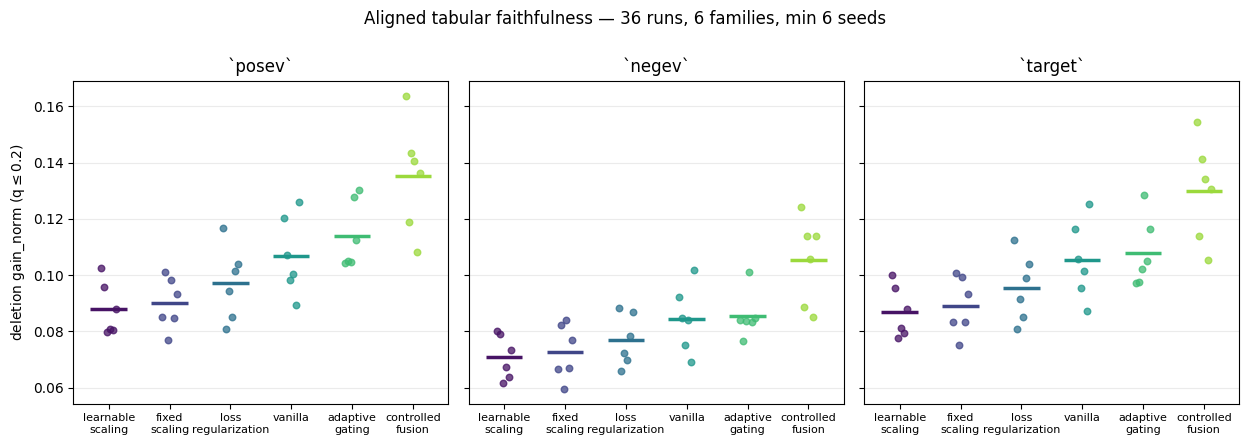

[report] 5 files in /mnt/disk1/home/cgiovannoni/mod-attendance/artifacts/cmmd/processed/runs/_faithfulness
    faithfulness_aligned_signed_n352.csv
    faithfulness_by_family_n352.png
    xai_shape_metrics.csv
    xai_stability.csv
    xai_summary_by_family.csv


In [ ]:
# @@SUBSET@@ 2/3 — aligned signed tabular faithfulness on the distinct-lesion sample (GPU)
from isic24 import xai_driver as xd
import gc, keras, time, os, pandas as pd

STRAT_ONLY_IMPL  = None         # None = every family
STRAT_ONLY_SEEDS = None         # e.g. [47]; None = every seed
STRAT_PER_FAMILY = None         # e.g. 1 for one run per family; None = every run
STRAT_DRY_RUN    = False        # False to run

_m = pd.read_csv(os.path.join(SUMMARIES_PATH, "master_results_rows.csv"))
if STRAT_ONLY_IMPL:  _m = _m[_m.impl_name.isin(STRAT_ONLY_IMPL)]
if STRAT_ONLY_SEEDS: _m = _m[_m.seed.isin(STRAT_ONLY_SEEDS)]
if STRAT_PER_FAMILY: _m = _m.groupby("impl_name", sort=False).head(int(STRAT_PER_FAMILY))
_m = _m.reset_index(drop=True)

# run_id -> run_dir, re-anchored on ART_PATH: the master carries the paths of another machine.
_RD = {r.run_id: xs.run_dir_abs(r.run_dir, ART_PATH)
       for _, r in _m.iterrows()}

# 1.5 s/sample, measured with the four signed modes; changing SIGNED_MODES changes it.
SEC_PER_SAMPLE = 1.5
_todo, _done = xs.resume_report(_RD, "shap_tab", XAI_SUBSET_FP)
_est = len(_todo) * len(xai_subset_idx) * SEC_PER_SAMPLE
print(f"[subset] {len(_m)} runs selected | already done {len(_done)} | to do {len(_todo)}")
print(f"[subset] {len(xf.SIGNED_MODES)} modes x {len(xai_subset_idx)} samples "
      f"-> estimate {_est/60:.0f} min ({_est/3600:.1f} h)  [{_est/60/max(len(_todo),1):.1f} min/run]")
if _done:
    print(f"        (resume active: the {len(_done)} already done with fingerprint {XAI_SUBSET_FP} are skipped)")
if STRAT_DRY_RUN:
    print("\n*** DRY RUN — nothing executed. Set STRAT_DRY_RUN=False to run. ***")
else:
    _t0 = time.time()
    for _i, _r in _m.iterrows():
        _rd = _RD[_r.run_id]
        if xs.is_done(_rd, "shap_tab", XAI_SUBSET_FP):
            continue
        try:
            _model, _ = xd.load_run_model(_rd)
            # Returns (results, phi): unpack it, or mark_done is never reached.
            _o, _ = xf.aligned_signed_faithfulness(
                _model, _rd, int(_r.best_epoch), subset_idx=xai_subset_idx,
                verbose=False, q_maxes=tuple(Q_MAX_REPORT), resume=True)
            xs.mark_done(_rd, "shap_tab", XAI_SUBSET_FP,
                         {"run_id": _r.run_id, "impl_name": _r.impl_name,
                          "setting_tag": _r.setting_tag, "n": len(xai_subset_idx),
                          "gains": {k: v for k, v in _o.items() if isinstance(v, float)}})
            print(f"[{_i+1}/{len(_m)}] {_r.run_id}: ok  ({(time.time()-_t0)/60:.0f} min total)", flush=True)
        except Exception as _e:
            print(f"[FAIL] {_r.run_id}: {type(_e).__name__}: {_e}", flush=True)
        finally:
            keras.backend.clear_session(); gc.collect()
    _todo, _done = xs.resume_report(_RD, "shap_tab", XAI_SUBSET_FP)
    print(f"\n[subset] done {len(_done)}/{len(_m)} in {(time.time()-_t0)/60:.0f} min"
          + (f" — {len(_todo)} left, re-run this cell to resume" if _todo else ""))

    # Cross-family report, no GPU. `central` is not optional: a family mean over all 45
    # fixed_scaling rows, endpoints included, means nothing.
    if not _todo:
        xs.report(pd.read_csv(os.path.join(SUMMARIES_PATH, "master_results_rows.csv")),
                  ART_PATH, kinds=("shap_tab",), central=CENTRAL_SETTINGS,
                  encoded_feature_names=encoded_feature_names, shape_top_k=CFG.shape_top_k)


[subset-lore] sample: 60 lesions, 30 pos / 30 neg  (balanced)
[subset-lore] sample fingerprint: lore-s0-n60-6c9169a731689567
[subset-lore] configuration: {'implementation': 'fixed-image-tabular-sa-v2', 'lore_sa_version': '1.1.3', 'seed_policy': 'base-plus-sample-position', 'rng_seed': 0, 'neigh_type': 'genetic', 'num_instances': 1000, 'mutpb': 0.5, 'init_mutpb': 0.3, 'threshold': 0.5, 'gen_kwargs': {}, 'fingerprint': 'lorecfg-64e024bb549eacaa'}
[subset-lore] 156 runs | seeded done 40 | accepted legacy 0 | to do 116
[subset-lore] families covered: 6/6 | LORE on /CPU:0

[warn] 6 selected runs have the tabular branch zeroed: a valid unimodal control, not a family representative.


,impl_name,setting_tag,run_id
6,fixed_scaling,a0p000,20261016-234343/seed_101__a0p000__e20
15,fixed_scaling,a0p000,20261016-234343/seed_47__a0p000__e20
24,fixed_scaling,a0p000,20261016-234343/seed_53__a0p000__e20
33,fixed_scaling,a0p000,20261016-234343/seed_71__a0p000__e20
42,fixed_scaling,a0p000,20261016-234343/seed_8__a0p000__e20
51,fixed_scaling,a0p000,20261016-234343/seed_90__a0p000__e20


I0000 00:00:1794083085.108896 3914571 service.cc:148] XLA service 0x7130f00163c0 initialized for platform Host (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1794083085.108959 3914571 service.cc:156]   StreamExecutor device (0): Host, Default Version
I0000 00:00:1794083086.809189 3914571 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.



[smoke] LORE reproducible on 20261016-234343/seed_71__a0p875__e20: 2 samples, every required column present, 0.2 min/sample
[smoke] projected 14 min/run -> 26.5 h for the 116 runs left


,impl_name,setting_tag,seed,run_id
0,vanilla,baseline,101,20261015-114125/seed_101__baseline__e20
1,vanilla,baseline,47,20261015-114125/seed_47__baseline__e20
2,vanilla,baseline,53,20261015-114125/seed_53__baseline__e20
3,vanilla,baseline,71,20261015-114125/seed_71__baseline__e20
4,vanilla,baseline,8,20261015-114125/seed_8__baseline__e20
...,...,...,...,...
151,adaptive_gating,base,90,20261020-020650/seed_90__base__e20
152,adaptive_gating,ent0e+00,90,20261020-020650/seed_90__ent0e+00__e20
153,adaptive_gating,ent1e-01,90,20261020-020650/seed_90__ent1e-01__e20
154,adaptive_gating,ent1e-02,90,20261020-020650/seed_90__ent1e-02__e20


[41/156] 20261016-234343/seed_71__a0p875__e20: {'LoreSACallback': 'ok'}  (10 min total)


2026-11-07 21:35:48,342 tensorflow   WARNING  5 out of the last 5 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x7132543b3240> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.


2026-11-07 21:35:52,970 tensorflow   WARNING  6 out of the last 6 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x7132543b3240> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.


[42/156] 20261016-234343/seed_71__a1p000__e20: {'LoreSACallback': 'ok'}  (20 min total)
[43/156] 20261016-234343/seed_8__a0p000__e20: {'LoreSACallback': 'ok'}  (30 min total)
[44/156] 20261016-234343/seed_8__a0p125__e20: {'LoreSACallback': 'ok'}  (41 min total)
[45/156] 20261016-234343/seed_8__a0p250__e20: {'LoreSACallback': 'ok'}  (51 min total)
[46/156] 20261016-234343/seed_8__a0p375__e20: {'LoreSACallback': 'ok'}  (61 min total)
[47/156] 20261016-234343/seed_8__a0p500__e20: {'LoreSACallback': 'ok'}  (71 min total)
[48/156] 20261016-234343/seed_8__a0p625__e20: {'LoreSACallback': 'ok'}  (82 min total)
[49/156] 20261016-234343/seed_8__a0p750__e20: {'LoreSACallback': 'ok'}  (92 min total)
[50/156] 20261016-234343/seed_8__a0p875__e20: {'LoreSACallback': 'ok'}  (103 min total)
[51/156] 20261016-234343/seed_8__a1p000__e20: {'LoreSACallback': 'ok'}  (113 min total)
[52/156] 20261016-234343/seed_90__a0p000__e20: {'LoreSACallback': 'ok'}  (123 min total)
[53/156] 20261016-234343/seed_90__a0p1

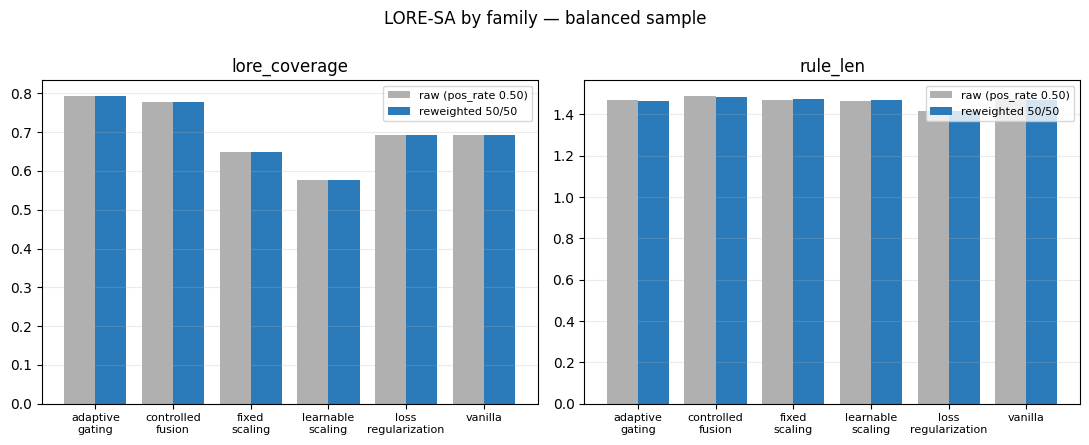

[report] 5 files in /mnt/disk1/home/cgiovannoni/mod-attendance/artifacts/cmmd/processed/runs/_faithfulness
    lore_sa_quality_n60.csv
    lore_sa_quality_n60.png
    xai_shape_metrics.csv
    xai_stability.csv
    xai_summary_by_family.csv


In [ ]:
# @@SUBSET@@ 3/3 — LORE on a balanced adopted sample (CPU)
from isic24 import xai_driver as xd
import gc, glob, keras, os, shutil, tempfile, time

STRAT_LORE_ONLY_IMPL  = None        # None = every family
STRAT_LORE_ONLY_SEEDS = None        # None = every seed
STRAT_LORE_ONLY_TAG   = None        # None = every setting
STRAT_LORE_PER_FAMILY = None        # None = every run
STRAT_LORE_PILOT      = False       # one central run per family (test before the full pass)
STRAT_LORE_DRY_RUN    = False
STRAT_LORE_N          = 60
LORE_SMOKE_N          = 2           # samples explained twice in scratch before the long pass
LORE_ON_CPU           = True        # the hot loop is the dense head and the tree, both CPU

xd.LORE_SA_DEVICE = "/CPU:0" if LORE_ON_CPU else None

_m = pd.read_csv(os.path.join(SUMMARIES_PATH, "master_results_rows.csv"))
if STRAT_LORE_ONLY_IMPL:  _m = _m[_m.impl_name.isin(STRAT_LORE_ONLY_IMPL)]
if STRAT_LORE_ONLY_SEEDS: _m = _m[_m.seed.isin(STRAT_LORE_ONLY_SEEDS)]
if STRAT_LORE_ONLY_TAG:   _m = _m[_m.setting_tag.isin(STRAT_LORE_ONLY_TAG)]
if STRAT_LORE_PILOT:
    _m = _m[[_tag == CENTRAL_SETTINGS.get(_impl)
             for _impl, _tag in zip(_m.impl_name, _m.setting_tag)]]
    _m = _m.groupby("impl_name", sort=False).head(1)
    if _m.impl_name.nunique() != 6:
        raise RuntimeError("The LORE pilot must contain one central run from every family.")
elif STRAT_LORE_PER_FAMILY:
    _m = _m.groupby("impl_name", sort=False).head(int(STRAT_LORE_PER_FAMILY))
_m = _m.reset_index(drop=True)
_RD = {r.run_id: xs.run_dir_abs(r.run_dir, ART_PATH)
       for _, r in _m.iterrows()}

_lore_idx = xs.lore_subset(validation_df.target.values, xai_subset_idx, STRAT_LORE_N)
_lore_y = validation_df.target.values[_lore_idx]
xd.LORE_SA_KWARGS.update(max_explain_samples=len(_lore_idx), subset_idx=_lore_idx)
_lore_sample_fp = xs.subset_fingerprint(
    xs.row_ids(validation_df), _lore_idx, seed=0, n=len(_lore_idx), kind="lore")
_lore_config = xd.lore_sa_config()
_lore_fp = f"{_lore_sample_fp}.{_lore_config['fingerprint']}"


def _lore_resume_state():
    todo, seeded, redo = xs.resume_verified(_RD, "lore_sa", _lore_fp, _lore_idx)
    if redo:
        raise RuntimeError(f"Seeded LORE stamps on another sample: {redo}")
    legacy = [rid for rid in todo if xs.is_done(_RD[rid], "lore_sa", XAI_SUBSET_FP)]
    invalid = [rid for rid in legacy
               if xs.sample_matches(_RD[rid], "lore_sa", _lore_idx) is not True]
    if invalid:
        raise RuntimeError(f"Legacy LORE stamps with unverifiable sample identity: {invalid}")
    return [rid for rid in todo if rid not in legacy], seeded, legacy


_todo, _done_seeded, _done_legacy = _lore_resume_state()
print(f"[subset-lore] sample: {len(_lore_idx)} lesions, "
      f"{int(_lore_y.sum())} pos / {int((1-_lore_y).sum())} neg  (balanced)")
print(f"[subset-lore] sample fingerprint: {_lore_sample_fp}")
print(f"[subset-lore] configuration: {_lore_config}")
print(f"[subset-lore] {len(_m)} runs | seeded done {len(_done_seeded)} | "
      f"accepted legacy {len(_done_legacy)} | to do {len(_todo)}")
print(f"[subset-lore] families covered: {_m.impl_name.nunique()}/6 | "
      f"LORE on {xd.LORE_SA_DEVICE or 'the default device = GPU'}")

_deg = _m[(_m.impl_name == "fixed_scaling") & (_m.setting_tag == "a0p000")]
if len(_deg):
    print(f"\n[warn] {len(_deg)} selected runs have the tabular branch zeroed: "
          "a valid unimodal control, not a family representative.")
    display(_deg[["impl_name", "setting_tag", "run_id"]])

# Exercise the real engine twice; only timing columns may differ.
if _todo and not STRAT_LORE_DRY_RUN:
    _sm_row = _m[_m.run_id == _todo[0]].iloc[0]
    xd.LORE_SA_KWARGS.update(max_explain_samples=int(LORE_SMOKE_N),
                             subset_idx=_lore_idx[:int(LORE_SMOKE_N)])
    _sm_frames, _t = [], time.time()
    for _rep in range(2):
        _sm_dir = tempfile.mkdtemp(prefix=f"lore_smoke_{_rep}_")
        try:
            _o = xd.run_posthoc_xai(
                _RD[_todo[0]], engines=("lore",), best_epoch=int(_sm_row.best_epoch),
                best_val_auc=float(_sm_row.best_val_auc), overwrite=True,
                verbose=False, xai_dir=_sm_dir)
            _bad = {k: v for k, v in (_o or {}).items() if str(v) != "ok"}
            assert _o and not _bad, (
                f"[smoke] LORE failed on {_todo[0]} repetition {_rep}: "
                f"{_bad or 'no engine ran'}")
            _csv = glob.glob(os.path.join(
                _sm_dir, "lore_sa", "*", "lore_sa_persample_*.csv"))
            assert _csv, f"[smoke] LORE reported ok but wrote no CSV under {_sm_dir}"
            _sm_frames.append(pd.read_csv(_csv[0]))
        finally:
            shutil.rmtree(_sm_dir, ignore_errors=True)
    xd.LORE_SA_KWARGS.update(max_explain_samples=len(_lore_idx), subset_idx=_lore_idx)

    _need = {"i", "rng_seed", "true_label", "rule_len", "neigh_n_classes",
             "neigh_pos_rate", "neigh_unique_frac", "fid_cv_bacc"}
    for _sm in _sm_frames:
        assert _need <= set(_sm.columns) and len(_sm) == int(LORE_SMOKE_N), (
            f"[smoke] the per-sample CSV is not what @LORE_SECTION@ aggregates: "
            f"{len(_sm)} rows, missing {sorted(_need - set(_sm.columns))}")
    _timing = ["seconds", "min_per_sample"]
    pd.testing.assert_frame_equal(
        _sm_frames[0].drop(columns=_timing, errors="ignore"),
        _sm_frames[1].drop(columns=_timing, errors="ignore"),
        check_dtype=False, check_exact=True)
    _sec = (time.time() - _t) / (2 * int(LORE_SMOKE_N))
    print(f"\n[smoke] LORE reproducible on {_sm_row.run_id}: {LORE_SMOKE_N} samples, "
          f"every required column present, {_sec/60:.1f} min/sample")
    print(f"[smoke] projected {len(_lore_idx)*_sec/60:.0f} min/run -> "
          f"{len(_todo)*len(_lore_idx)*_sec/3600:.1f} h for the {len(_todo)} runs left")

display(_m[["impl_name", "setting_tag", "seed", "run_id"]])

if STRAT_LORE_DRY_RUN:
    print("\n*** DRY RUN — nothing executed. Set STRAT_LORE_DRY_RUN=False to run. ***")
else:
    xd.LORE_SA_KWARGS.update(max_explain_samples=len(_lore_idx), subset_idx=_lore_idx)
    _t0 = time.time()
    try:
        for _i, _r in _m.iterrows():
            if _r.run_id not in _todo:
                continue
            _rd = _RD[_r.run_id]
            try:
                _o = xd.run_posthoc_xai(
                    _rd, engines=("lore",), best_epoch=int(_r.best_epoch),
                    best_val_auc=float(_r.best_val_auc), overwrite=True, verbose=False)
                _bad = {_k: _v for _k, _v in (_o or {}).items() if str(_v) != "ok"}
                if _bad or not _o:
                    print(f"[FAIL] {_r.run_id}: {_bad or 'no engine ran'}", flush=True)
                    continue
                xs.mark_done(
                    _rd, "lore_sa", _lore_fp,
                    {"run_id": _r.run_id, "impl_name": _r.impl_name,
                     "setting_tag": _r.setting_tag, "n": int(len(_lore_idx)),
                     "n_pos": int(_lore_y.sum()),
                     "sample_fingerprint": _lore_sample_fp,
                     "parent_sample_fingerprint": XAI_SUBSET_FP,
                     "lore_config": _lore_config, "result": str(_o)})
                print(f"[{_i+1}/{len(_m)}] {_r.run_id}: {_o}  "
                      f"({(time.time()-_t0)/60:.0f} min total)", flush=True)
            except Exception as _e:
                print(f"[FAIL] {_r.run_id}: {type(_e).__name__}: {_e}", flush=True)
            finally:
                keras.backend.clear_session(); gc.collect()
    finally:
        xd.LORE_SA_KWARGS.pop("subset_idx", None)

    _todo, _done_seeded, _done_legacy = _lore_resume_state()
    _done = _done_seeded + _done_legacy
    print(f"\n[subset-lore] done {len(_done)}/{len(_m)} in {(time.time()-_t0)/60:.0f} min "
          f"({len(_done_seeded)} seeded, {len(_done_legacy)} accepted legacy)"
          + (f" — {len(_todo)} left, re-run to resume" if _todo else ""))
    if not _todo:
        xs.report(pd.read_csv(os.path.join(SUMMARIES_PATH, "master_results_rows.csv")),
                  ART_PATH, kinds=("lore_sa",), central=CENTRAL_SETTINGS,
                  encoded_feature_names=encoded_feature_names, shape_top_k=CFG.shape_top_k,
                  lore_idx={len(_lore_idx): _lore_idx})

In [ ]:
# @@FAITH_LOOP@@ — deletion/insertion on the adopted sample, both tabular attributors (GPU)
from isic24 import xai_driver as xd
import time

FAITH_OUT_DIR = os.path.join(RUNS_PATH, "_faithfulness")
os.makedirs(FAITH_OUT_DIR, exist_ok=True)

_plan = []
for _impl, _study in CANONICAL.items():
    if FAITH_ONLY_IMPL and _impl not in FAITH_ONLY_IMPL:
        continue
    for _sp in sorted(glob.glob(os.path.join(_study, "*", "*", "single_run_summary.csv"))):
        _row, _rd = pd.read_csv(_sp).iloc[0], os.path.dirname(_sp)
        # Every run is refused HERE if it was trained against another space, before the GPU
        # is taken: the same check `load_run_model` makes one checkpoint at a time.
        xd.assert_run_feature_space(json.load(open(os.path.join(_rd, "config.json"))),
                                    _rd, FEATURE_SPACE_FILE, FEATURE_SPACE_FP)
        _js = {"aligned": os.path.join(_rd, "xai", "faithfulness", "faithfulness.json"),
               "gradient": os.path.join(_rd, "xai", "faith_gradient", "faithfulness.json")}
        _plan.append({"impl_name": _impl, "setting_tag": _row.setting_tag, "seed": int(_row.seed),
                      "run_id": _row.run_id,
                      "best_epoch": int(_row.best_epoch), "best_val_auc": float(_row.best_val_auc),
                      "run_dir": _rd, "js": _js,
                      "todo": [k for k, f in _js.items() if FAITH_OVERWRITE or not os.path.exists(f)
                               or (k == "gradient" and xs.branch_off(_impl, _row.setting_tag) != "tabular"
                                   and json.load(open(f)).get("encoded_feature_names") != encoded_feature_names)]})

faith_plan = pd.DataFrame(_plan).head(FAITH_MAX_RUNS or len(_plan))
print(f"[FAITH] {len(faith_plan)} canonical runs | {int((faith_plan.todo.map(len) > 0).sum())} with work left "
      f"| sample {XAI_SUBSET_FP} (n={len(xai_subset_idx)}), the same rows for every run")
print(f"[FAITH] aligned={sum('aligned' in todo for todo in faith_plan.todo)} | "
      f"gradient={sum('gradient' in todo for todo in faith_plan.todo)} | "
      f"reuse={sum(not todo for todo in faith_plan.todo)} | "
      f"overwrite={FAITH_OVERWRITE} | dry_run={FAITH_DRY_RUN}")
if FAITH_DRY_RUN:
    display(faith_plan.drop(columns=["js"]))
    raise SystemExit("FAITH_DRY_RUN=True: no models loaded.")

# The gradient ranking is READ from disk, never recomputed: without SHAP on the adopted sample
# there is nothing to rank with, and finding out one model at a time costs a night.
_no_shap = [r.run_dir for r in faith_plan.itertuples()
            if "gradient" in r.todo and not glob.glob(
                os.path.join(r.run_dir, "xai", "shap_tab", "epoch_*", "*.npz"))]
assert not _no_shap, (f"{len(_no_shap)} runs carry no SHAP on this sample: run SUBSET 1/3 "
                      f"with the SHAP engine first — e.g. {_no_shap[0]}")


def _grad_cols(d):   # the gradient contrast, prefixed so both attributors sit in one row
    return {f"grad_{k}": v for k, v in d.items() if k.startswith("faithfulness_") or k == "tab_ranking"}


faith_rows = []
for _r in faith_plan.itertuples():
    _t0 = time.time()
    if _r.todo:
        keras.backend.clear_session()
        model, _ = xd.load_run_model(_r.run_dir)
    if "aligned" in _r.todo:
        _raw, _im, _ = xf._build_faith_subset()
        _phi, _ = xf.aligned_tab_attributions(model, _raw, _im, background="baseline")
        res = explanation_faithfulness(model, _r.run_dir, _r.best_epoch,
                                       methods=("tabular", "image", "joint"),
                                       tab_imp_override=np.abs(_phi),
                                       save=True, verbose=False, allow_clobber=FAITH_OVERWRITE)
    else:
        res = {k: v for k, v in json.load(open(_r.js["aligned"])).items()
               if k not in ("curves", "q_grid")}
    if "gradient" in _r.todo:
        res.update(_grad_cols(explanation_faithfulness(
            model, _r.run_dir, _r.best_epoch, methods=("tabular", "joint"),
            out_dir=os.path.dirname(_r.js["gradient"]), save=True, verbose=False,
            allow_clobber=FAITH_OVERWRITE)))
    else:
        res.update(_grad_cols(json.load(open(_r.js["gradient"]))))
    if _r.todo:
        res["faith_seconds"] = round(time.time() - _t0, 2)
        keras.backend.clear_session(); gc.collect()
    faith_rows.append({**{c: getattr(_r, c) for c in
                          ("run_id", "impl_name", "setting_tag", "seed", "best_val_auc", "run_dir")},
                       **{k: v for k, v in res.items() if not isinstance(v, (list, dict))}})
    print(f"  {'+'.join(_r.todo) or 'reuse':>17} {_r.impl_name:>18}/{_r.setting_tag:<14} "
          f"seed {_r.seed:<4} del={res['faithfulness_gain']:+.4f} ({res.get('faith_seconds', '-')}s)")

faith_df = pd.DataFrame(faith_rows)
_out_csv = os.path.join(FAITH_OUT_DIR, "combined_faithfulness.csv")
if os.path.exists(_out_csv):          # a partial pass must not truncate the registry
    _prev = pd.read_csv(_out_csv)
    faith_df = pd.concat([_prev[~_prev.run_dir.isin(faith_df.run_dir)], faith_df], ignore_index=True)
xs.stamp_aggregate(_out_csv, faith_df.run_id, attributors=("aligned", "gradient"))
faith_df.to_csv(_out_csv, index=False)
print(f"[FAITH] {faith_df.shape} -> {_out_csv}")
display(faith_df.head(20))

[FAITH] 156 canonical runs | 156 with work left | sample unique-equal-s0-n352-4d03feeee04387a7 (n=352), the same rows for every run
[FAITH] aligned=156 | gradient=156 | reuse=0 | overwrite=False | dry_run=False


I0000 00:00:1794158446.171297 3914570 service.cc:148] XLA service 0x712627ef94f0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1794158446.171326 3914570 service.cc:156]   StreamExecutor device (0): Quadro RTX 6000, Compute Capability 7.5
I0000 00:00:1794158446.828753 3914570 cuda_dnn.cc:529] Loaded cuDNN version 90300
E0000 00:00:1794158447.620548 3914570 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794158447.815141 3914570 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794158448.197727 3914570 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794158448.392432 39

   aligned+gradient            vanilla/baseline       seed 101  del=+0.0400 (461.56s)
   aligned+gradient            vanilla/baseline       seed 47   del=+0.1041 (448.72s)
   aligned+gradient            vanilla/baseline       seed 53   del=+0.3326 (451.31s)
   aligned+gradient            vanilla/baseline       seed 71   del=-0.0459 (449.87s)
   aligned+gradient            vanilla/baseline       seed 8    del=+0.1560 (448.93s)
   aligned+gradient            vanilla/baseline       seed 90   del=+0.1164 (451.67s)
   aligned+gradient      fixed_scaling/a0p000         seed 101  del=+0.2073 (447.86s)
   aligned+gradient      fixed_scaling/a0p125         seed 101  del=+0.1728 (447.6s)
   aligned+gradient      fixed_scaling/a0p250         seed 101  del=+0.3370 (448.32s)
   aligned+gradient      fixed_scaling/a0p375         seed 101  del=+0.0159 (446.93s)
   aligned+gradient      fixed_scaling/a0p500         seed 101  del=+0.0248 (446.99s)
   aligned+gradient      fixed_scaling/a0p625         s

,run_id,impl_name,setting_tag,seed,best_val_auc,run_dir,n_faith_samples,blur_sigma,tab_ranking,deletion_auc_tabular_exp,...,faith_seconds,grad_tab_ranking,grad_faithfulness_tabular_del_gain,grad_faithfulness_tabular_ins_gain,grad_faithfulness_joint_del_gain,grad_faithfulness_joint_ins_gain,grad_faithfulness_primary_method,grad_faithfulness_gain,grad_faithfulness_gain_ci_lo,grad_faithfulness_gain_ci_hi
0,20261015-114125/seed_101__baseline__e20,vanilla,baseline,101,0.715057,/mnt/disk1/home/cgiovannoni/mod-attendance/art...,352,8.0,override,0.008217,...,461.56,shap_gradient,0.054236,0.050587,0.057339,0.451111,joint,0.057339,-0.030787,0.142294
1,20261015-114125/seed_47__baseline__e20,vanilla,baseline,47,0.706838,/mnt/disk1/home/cgiovannoni/mod-attendance/art...,352,8.0,override,0.023143,...,448.72,shap_gradient,0.035390,0.035664,0.088167,0.264528,joint,0.088167,0.007855,0.169462
2,20261015-114125/seed_53__baseline__e20,vanilla,baseline,53,0.708847,/mnt/disk1/home/cgiovannoni/mod-attendance/art...,352,8.0,override,0.009698,...,451.31,shap_gradient,0.048349,0.043745,0.336495,0.298988,joint,0.336495,0.279155,0.393129
3,20261015-114125/seed_71__baseline__e20,vanilla,baseline,71,0.724303,/mnt/disk1/home/cgiovannoni/mod-attendance/art...,352,8.0,override,0.029336,...,449.87,shap_gradient,0.035768,0.033276,-0.035411,0.208361,joint,-0.035411,-0.100227,0.028066
4,20261015-114125/seed_8__baseline__e20,vanilla,baseline,8,0.703382,/mnt/disk1/home/cgiovannoni/mod-attendance/art...,352,8.0,override,0.014527,...,448.93,shap_gradient,0.041893,0.039083,0.157832,0.250591,joint,0.157832,0.097698,0.216875
5,20261015-114125/seed_90__baseline__e20,vanilla,baseline,90,0.726718,/mnt/disk1/home/cgiovannoni/mod-attendance/art...,352,8.0,override,0.018674,...,451.67,shap_gradient,0.053113,0.051871,0.142706,0.334096,joint,0.142706,0.030332,0.257557
6,20261016-234343/seed_101__a0p000__e20,fixed_scaling,a0p000,101,0.697450,/mnt/disk1/home/cgiovannoni/mod-attendance/art...,352,8.0,override,0.000000,...,447.86,shap_gradient,0.000000,0.000000,0.205037,0.563778,joint,0.205037,0.149989,0.259071
7,20261016-234343/seed_101__a0p125__e20,fixed_scaling,a0p125,101,0.702631,/mnt/disk1/home/cgiovannoni/mod-attendance/art...,352,8.0,override,-0.001611,...,447.60,shap_gradient,0.017773,0.016255,0.166455,0.441502,joint,0.166455,0.111311,0.223419
8,20261016-234343/seed_101__a0p250__e20,fixed_scaling,a0p250,101,0.715348,/mnt/disk1/home/cgiovannoni/mod-attendance/art...,352,8.0,override,0.002509,...,448.32,shap_gradient,0.027901,0.026360,0.364081,0.690889,joint,0.364081,0.297567,0.428658
9,20261016-234343/seed_101__a0p375__e20,fixed_scaling,a0p375,101,0.720096,/mnt/disk1/home/cgiovannoni/mod-attendance/art...,352,8.0,override,0.003431,...,446.93,shap_gradient,0.025307,0.023607,0.018865,0.152237,joint,0.018865,-0.015650,0.054047


In [ ]:
# @@LOGIT_DECOMP@@ — exact logit decomposition: z = bias + image term + tabular term, no residual
# Loads one checkpoint per run and does a single forward pass over the adopted sample; the guard raises if the split does not reconstruct the prediction.

from isic24 import xai_logit as xlog

LOGIT_ALL_RUNS  = False         # False = the six central settings | True = every canonical run
LOGIT_OVERWRITE = False         # True = re-decompose the runs that already hold a per-sample table

_lmaster = pd.read_csv(os.path.join(SUMMARIES_PATH, "master_results_rows.csv"))
_central = None if LOGIT_ALL_RUNS else CENTRAL_SETTINGS
_by_run, _by_family, _per_sample = xlog.decompose_study(
    _lmaster, ART_PATH, subset_idx=xai_subset_idx, central=_central, overwrite=LOGIT_OVERWRITE)

print("\n=== image share of the logit, by family ===")
print(_by_family.to_string(index=False))

# Three ways to ask "how much does the model use the image", side by side.
_m = _lmaster if _central is None else _lmaster[
    [bool(_central.get(i) == s) for i, s in zip(_lmaster.impl_name, _lmaster.setting_tag)]]
_cmp = (_by_run.groupby("impl_name")["mean_image_abs_share_descriptive"].mean().rename("logit_share")
        .to_frame()
        .join(_m.groupby("impl_name")[["img_drop_auc", "tab_drop_auc", "base_auc"]].mean()))
_cmp["ablation_share"] = _cmp.img_drop_auc / (_cmp.img_drop_auc + _cmp.tab_drop_auc)
print("\n=== three measures of reliance ===")
print(_cmp[["logit_share", "ablation_share", "img_drop_auc", "tab_drop_auc"]].round(3).to_string())
print(f"Spearman(logit_share, ablation_share) over {len(_cmp)} families: "
      f"{_cmp.logit_share.corr(_cmp.ablation_share, method='spearman'):+.3f}")

# Aggregating over both classes hides the asymmetry the strata already show.
print("\n=== per class: image share and target-aligned contribution ===")
print(_by_run.groupby("impl_name")[xlog.CLASS_COLS].mean().round(3).to_string())

# Consistency with the June vanilla decomposition (128 samples, same baselines).
_june = os.path.join(ART_PATH, "diagnostics", "vanilla_logit_contributions",
                     "20260604-210304", "vanilla_logit_contributions_by_seed.csv")
if os.path.exists(_june):
    _j = pd.read_csv(_june)["mean_image_abs_share_descriptive"].mean()
    _v = _by_run.loc[_by_run.impl_name == "vanilla", "mean_image_abs_share_descriptive"].mean()
    print(f"\n[check] vanilla image share — June n=128: {_j:.3f} | this sample n={len(xai_subset_idx)}: {_v:.3f}")

  [ablations] logit decomposition: 12 unimodal endpoint runs excluded from the aggregate


E0000 00:00:1794234866.117748 3914571 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794234866.309826 3914571 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794234866.504388 3914571 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794234866.840399 3914571 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794234867.032492 3914571 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:0

[1/36]              vanilla   baseline share 0.681  delta 1.2e-07
[2/36]              vanilla   baseline share 0.691  delta 1.2e-07
[3/36]              vanilla   baseline share 0.703  delta 1.2e-07
[4/36]              vanilla   baseline share 0.659  delta 1.5e-07
[5/36]              vanilla   baseline share 0.702  delta 1.2e-07
[6/36]              vanilla   baseline share 0.698  delta 1.2e-07
[7/36]        fixed_scaling     a0p500 share 0.688  delta 1.2e-07
[8/36]        fixed_scaling     a0p500 share 0.712  delta 1.2e-07
[9/36]        fixed_scaling     a0p500 share 0.616  delta 1.2e-07
[10/36]        fixed_scaling     a0p500 share 0.751  delta 1.2e-07
[11/36]        fixed_scaling     a0p500 share 0.703  delta 1.2e-07
[12/36]        fixed_scaling     a0p500 share 0.736  delta 1.2e-07
[13/36]    learnable_scaling init_a0p500 share 0.714  delta 1.2e-07
[14/36]    learnable_scaling init_a0p500 share 0.701  delta 1.2e-07
[15/36]    learnable_scaling init_a0p500 share 0.594  delta 1.2e-07
[

In [ ]:
# @@GAMMA_ATTENDANCE@@ — attendance against the fusion bias, re-derived from the saved decomposition
_g_by_run, _g_by_family = xlog.gamma_curve(_per_sample, ART_PATH, master=_lmaster)

_neutral = _g_by_run[_g_by_run.delta == 0.0].set_index("run_id")["mean_image_abs_share_descriptive"]
_diff = (_by_run.set_index("run_id")["mean_image_abs_share_descriptive"] - _neutral).abs().max()
print(f"[check] delta=0 reproduces the measured decomposition: max |diff| = {_diff:.2e}")

print("\n=== image share of the logit against the fusion bias ===")
print(_g_by_family.pivot(index="impl_name", columns="gamma_tab",
                         values="mean_image_abs_share_descriptive__mean").round(3).to_string())

print("\n=== sample AUC against the fusion bias (adopted XAI sample, NOT the validation set) ===")
print(_g_by_family.pivot(index="impl_name", columns="gamma_tab",
                         values="sample_auc__mean").round(4).to_string())

_peak = _g_by_run.loc[_g_by_run.groupby(["impl_name", "seed"])["sample_auc"].idxmax()]
print("\n=== where each run's sample AUC peaks, by family ===")
print(_peak.groupby("impl_name")["delta"].agg(["mean", "std", "count"]).round(3).to_string())


[check] delta=0 reproduces the measured decomposition: max |diff| = 7.12e-08

=== image share of the logit against the fusion bias ===
gamma_tab            0.500  0.625  0.750  0.875  1.000  1.125  1.250  1.375  1.500
impl_name                                                                         
adaptive_gating      0.815  0.781  0.748  0.714  0.679  0.643  0.604  0.560  0.511
controlled_fusion    0.810  0.772  0.733  0.694  0.654  0.611  0.566  0.516  0.460
fixed_scaling        0.841  0.808  0.774  0.738  0.701  0.661  0.618  0.569  0.513
learnable_scaling    0.836  0.802  0.768  0.733  0.696  0.656  0.612  0.564  0.509
loss_regularization  0.832  0.797  0.761  0.724  0.686  0.645  0.600  0.551  0.495
vanilla              0.833  0.798  0.763  0.727  0.689  0.649  0.605  0.556  0.500

=== sample AUC against the fusion bias (adopted XAI sample, NOT the validation set) ===
gamma_tab             0.500   0.625   0.750   0.875   1.000   1.125   1.250   1.375   1.500
impl_name           

### Family diagnostics — gate weights, ablation, calibration, gamma sweep

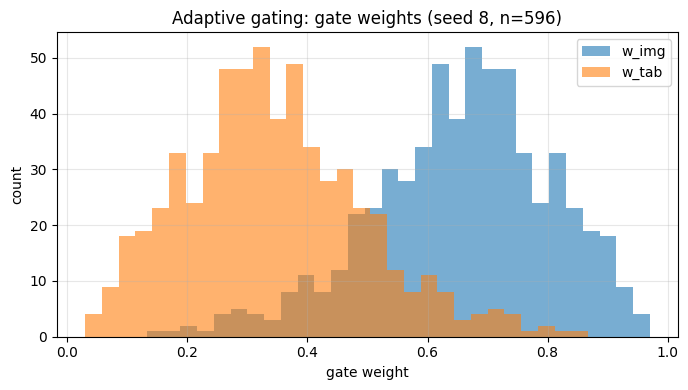

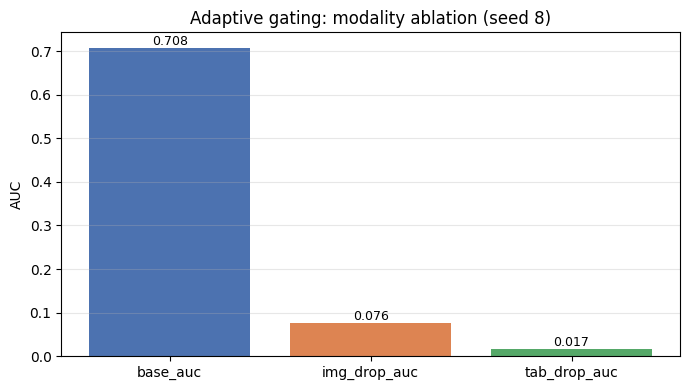

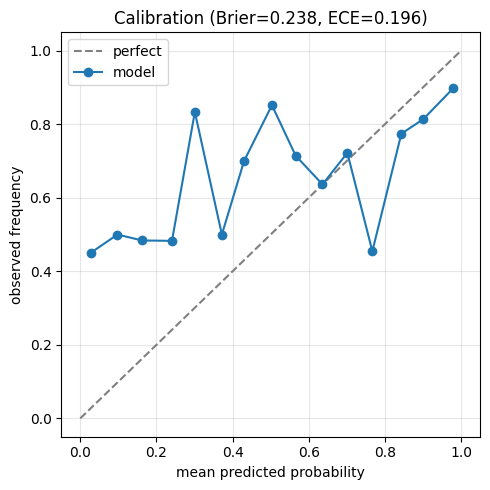

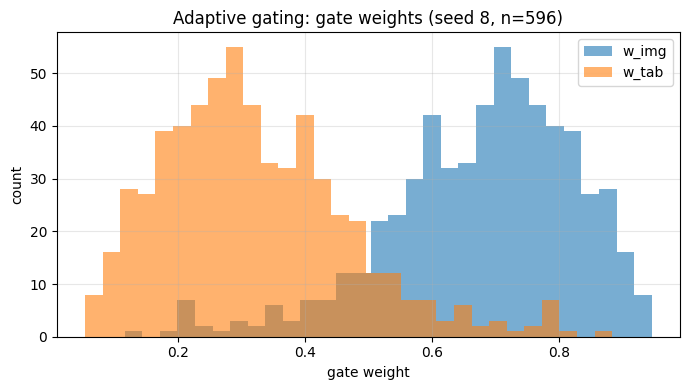

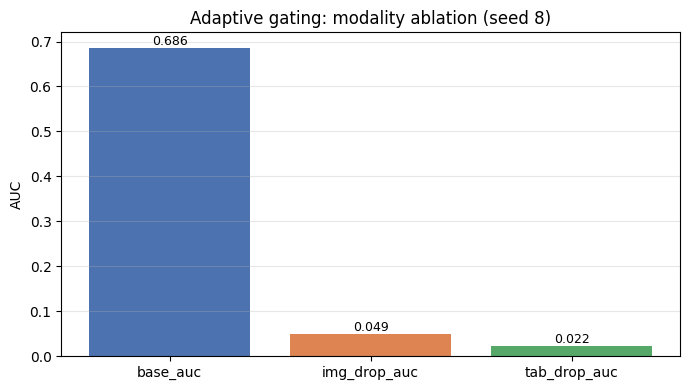

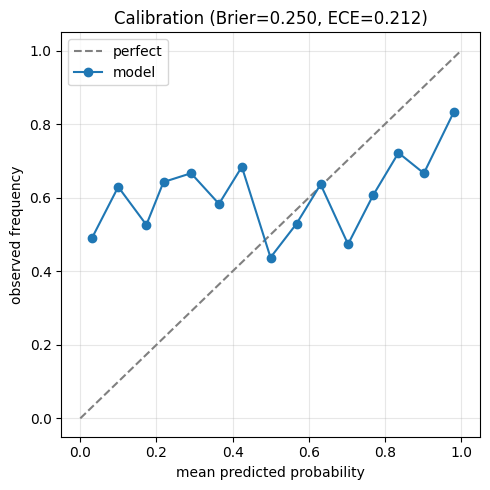

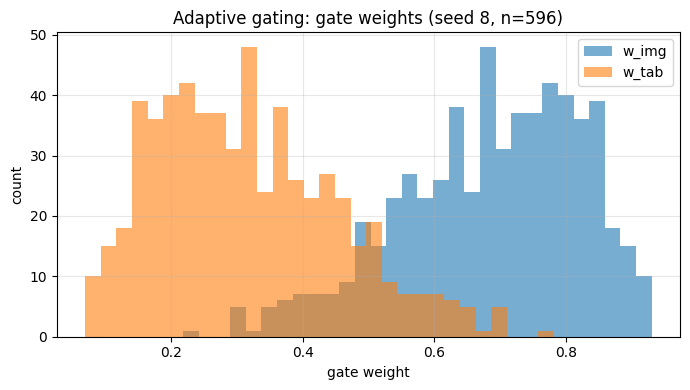

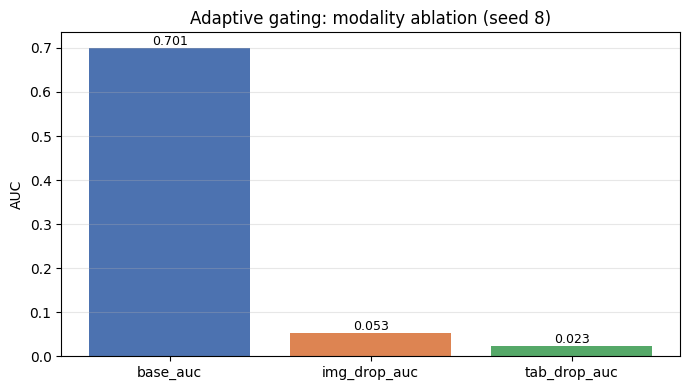

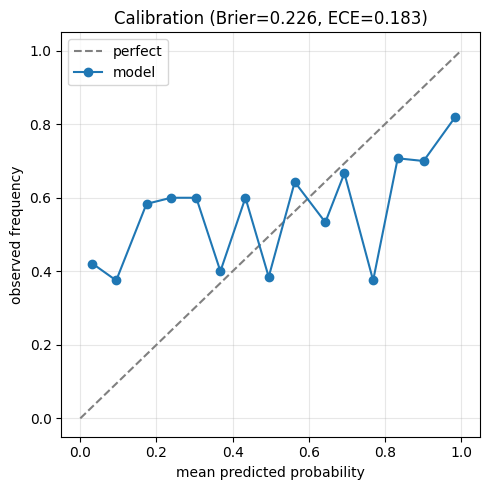

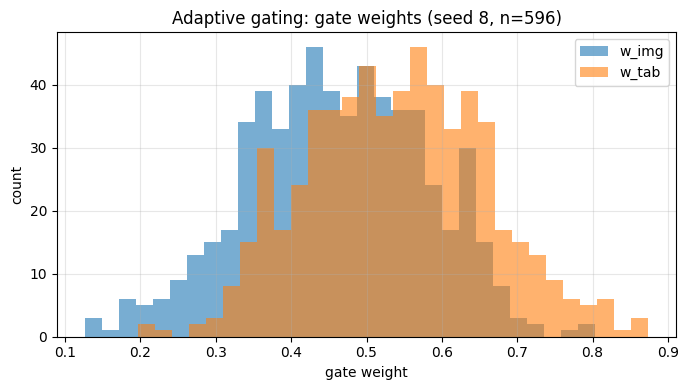

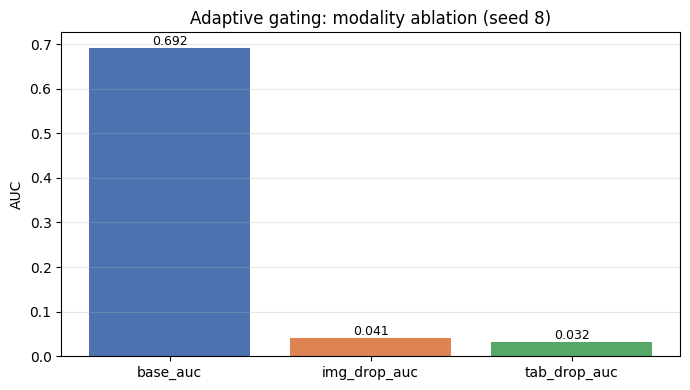

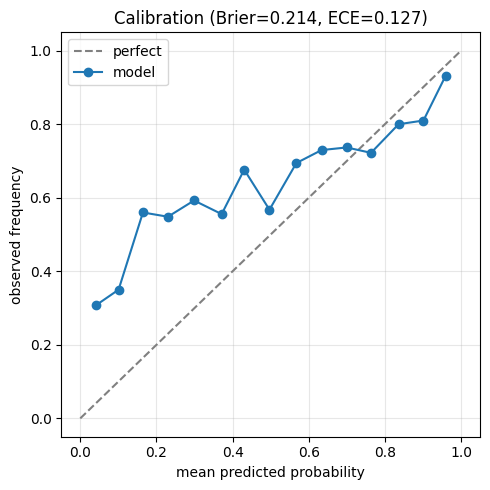

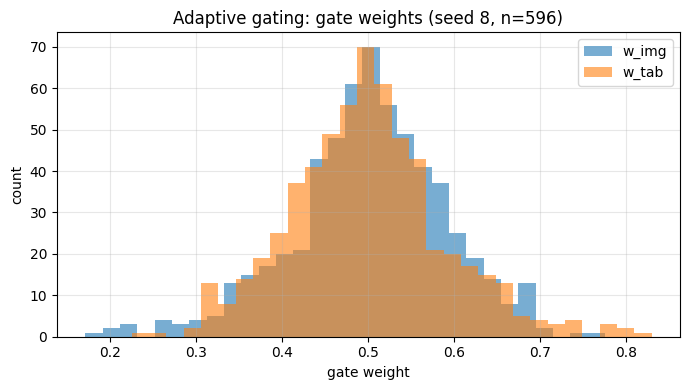

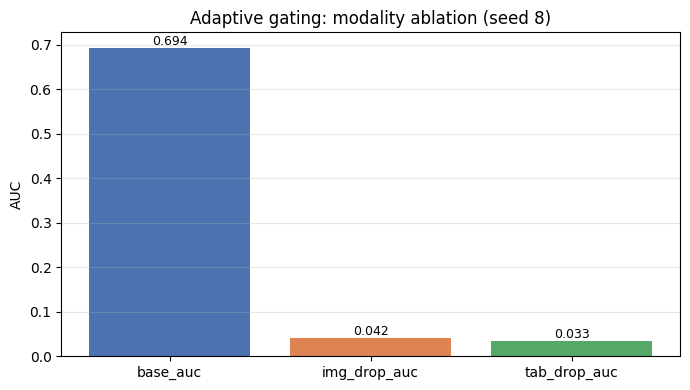

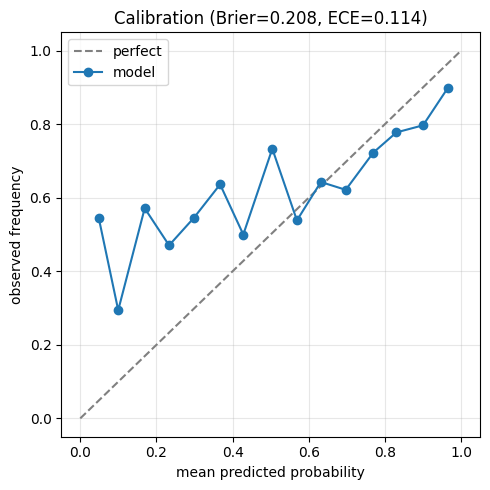

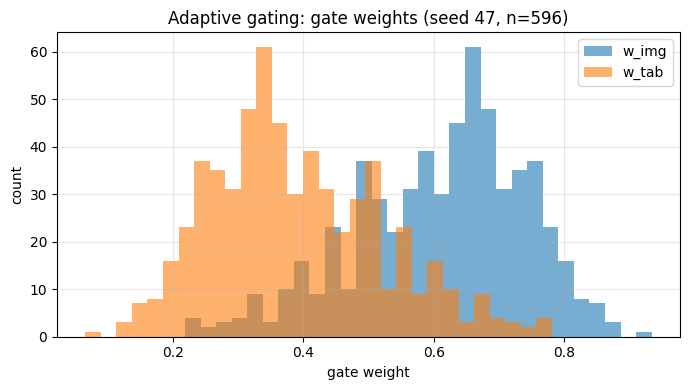

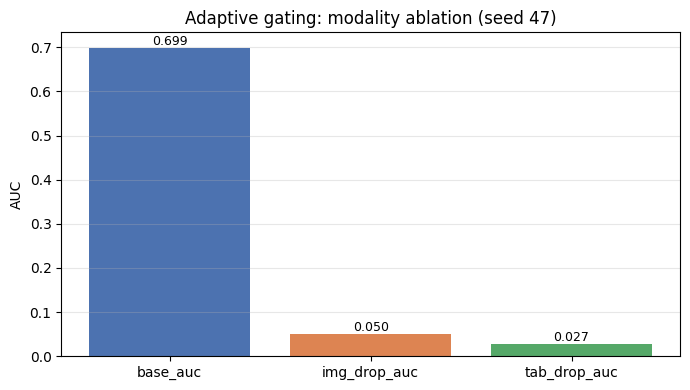

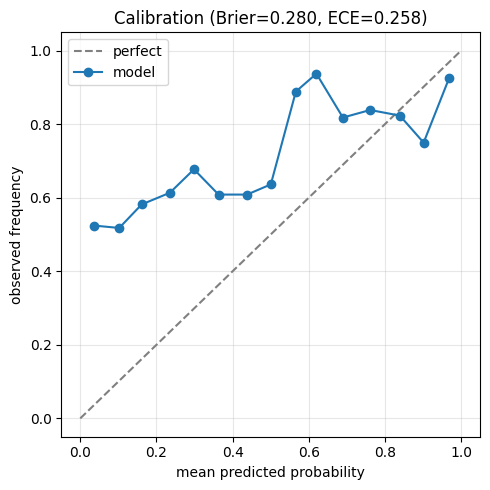

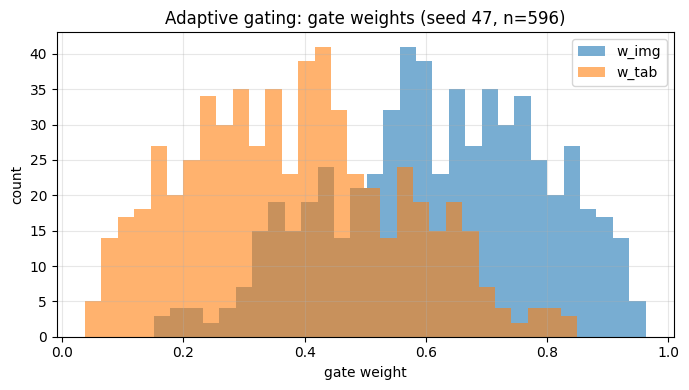

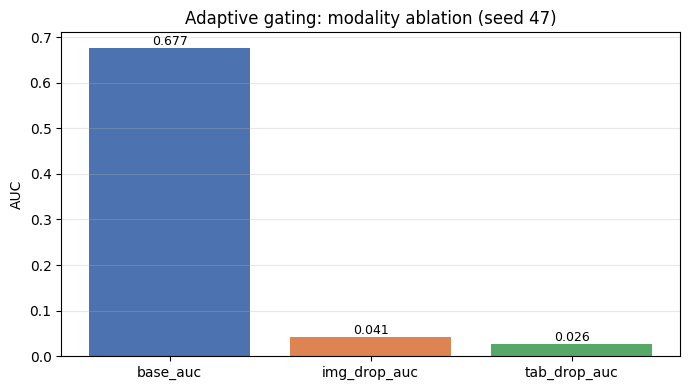

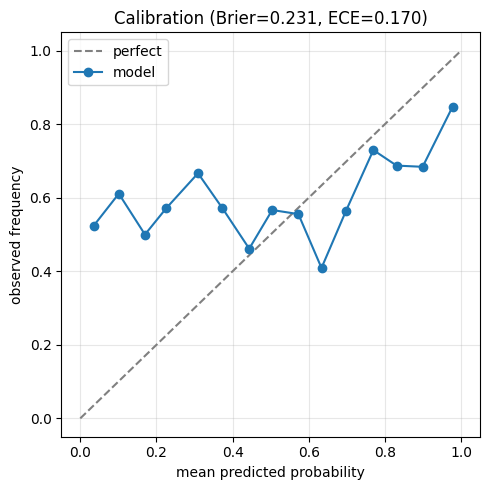

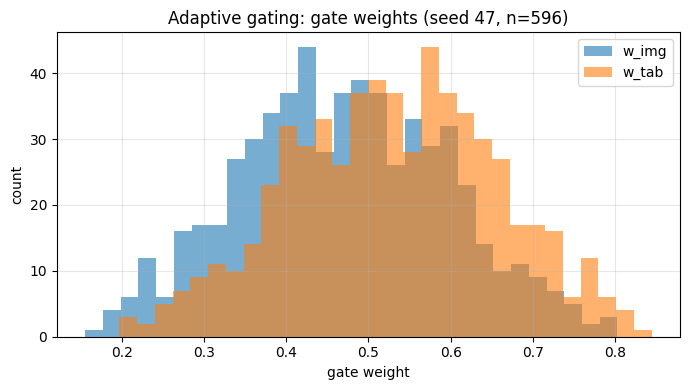

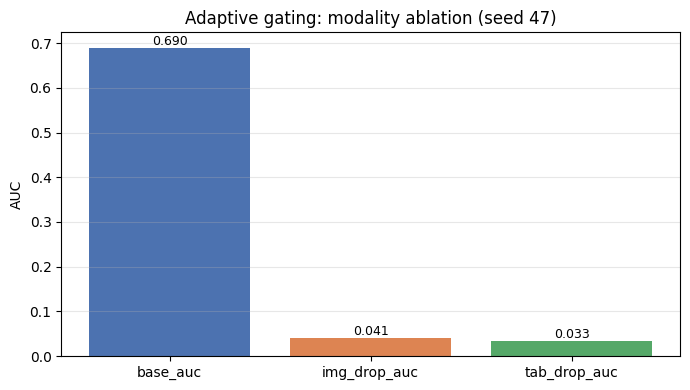

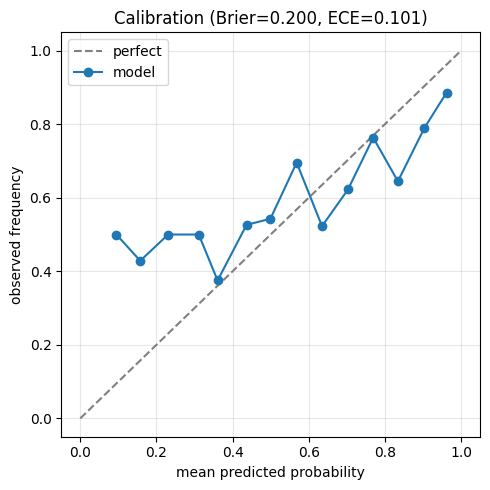

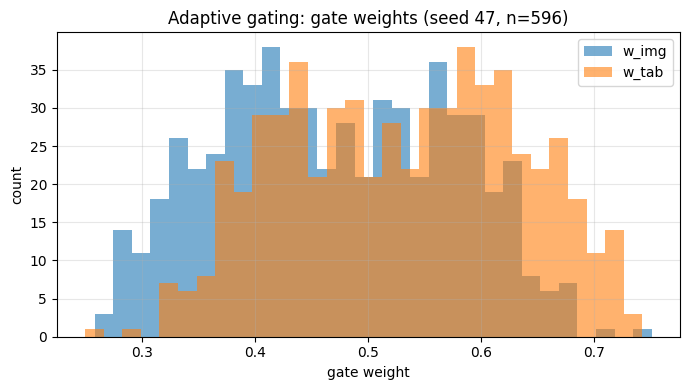

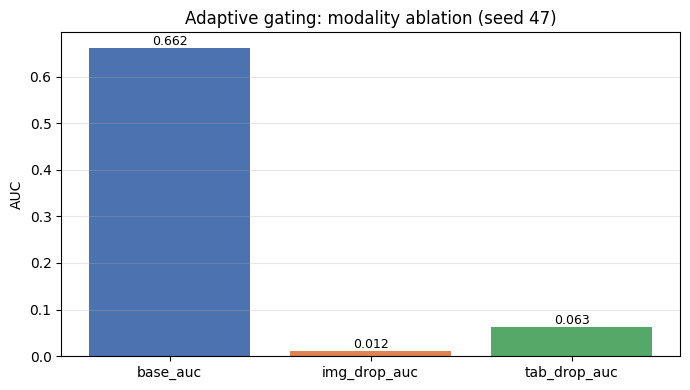

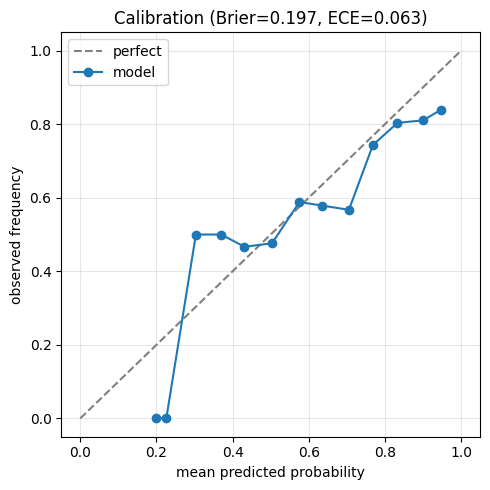

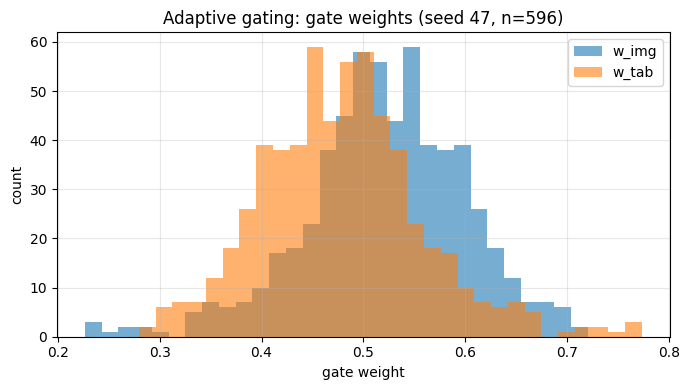

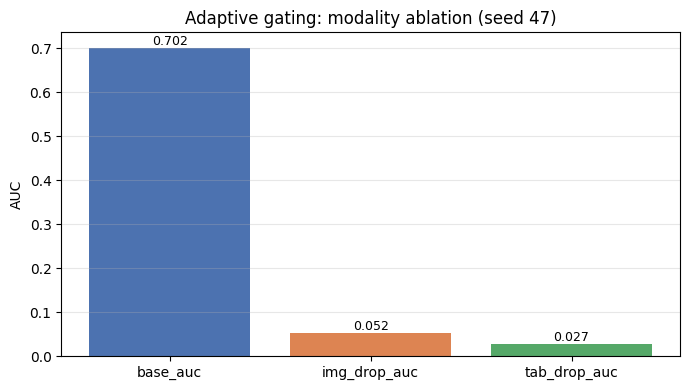

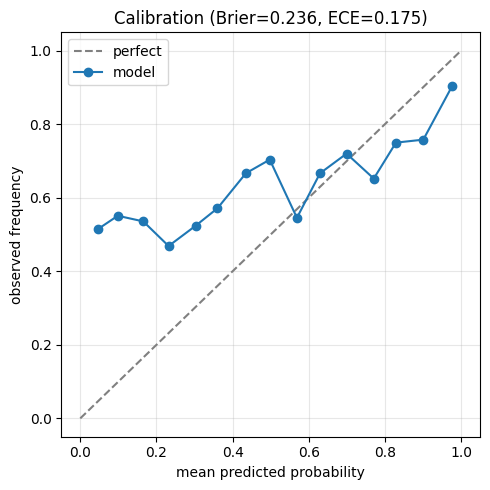

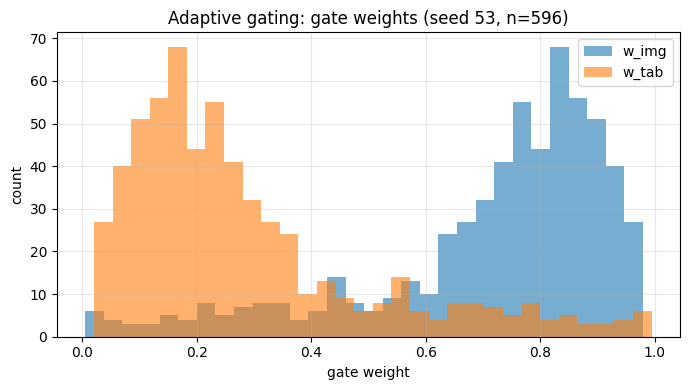

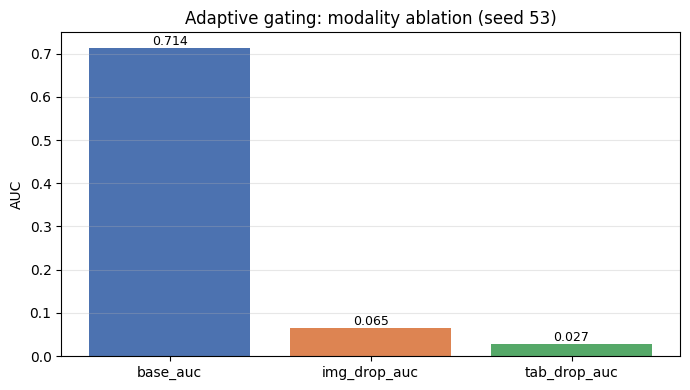

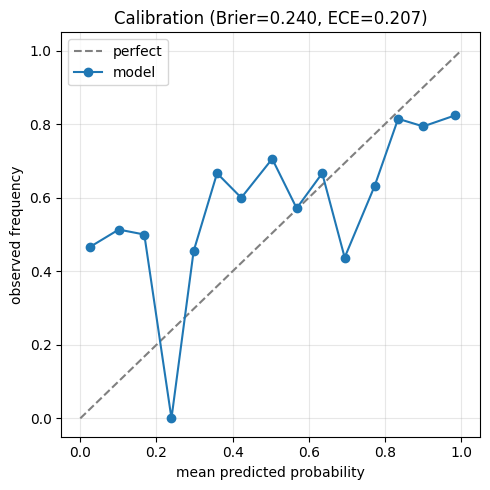

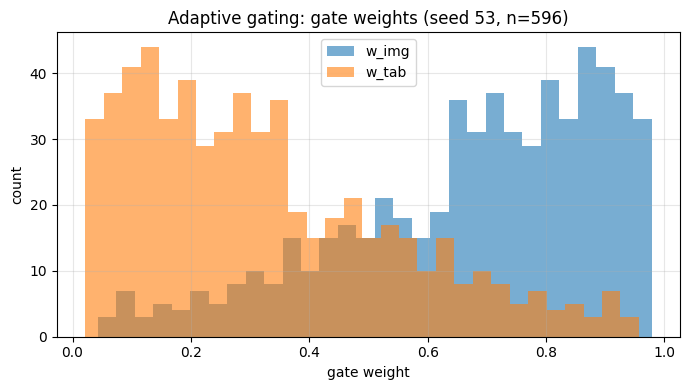

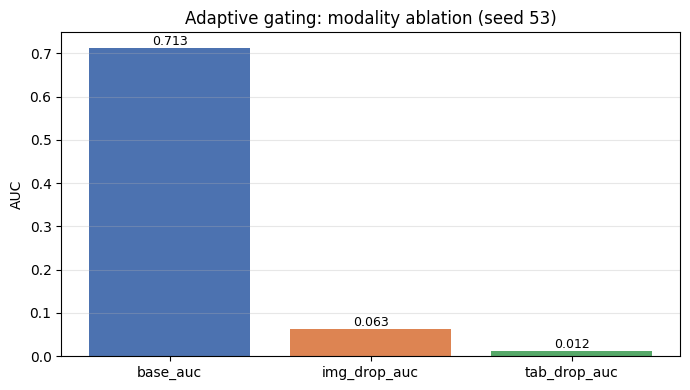

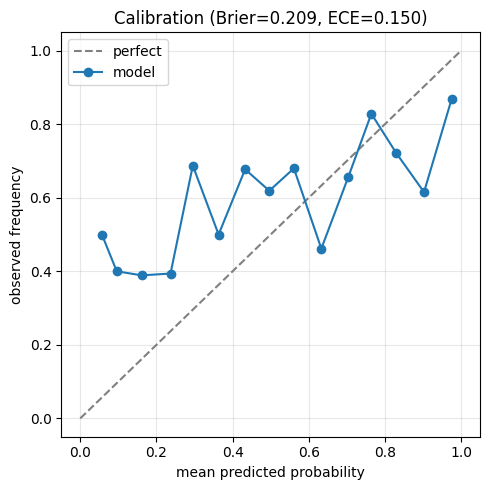

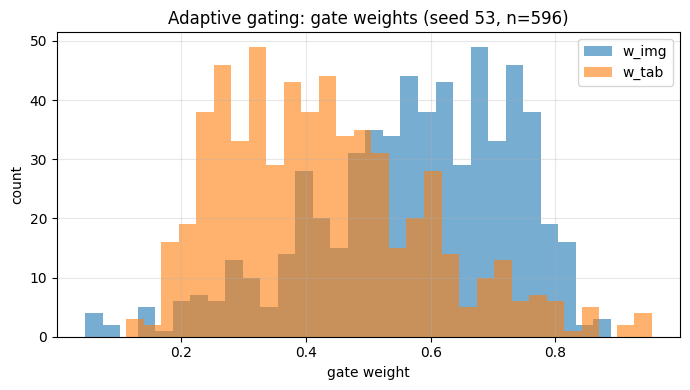

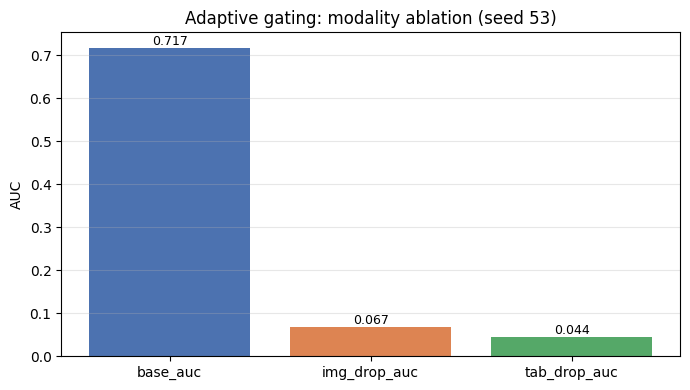

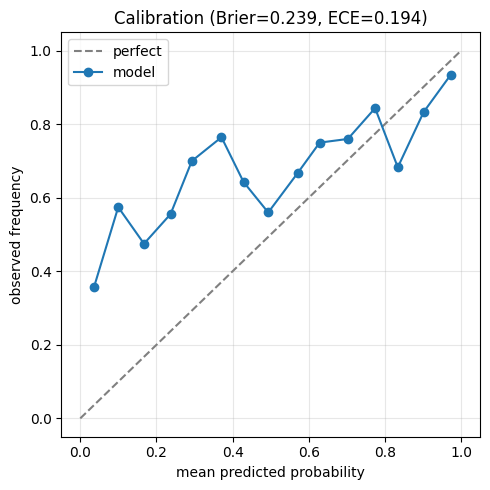

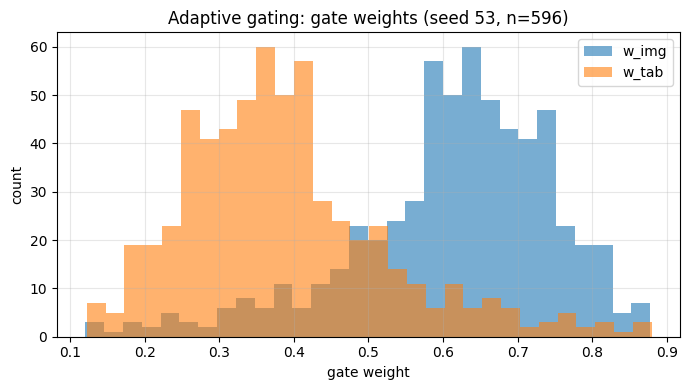

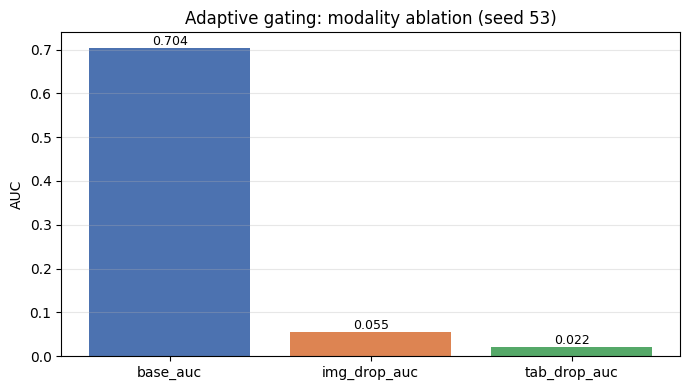

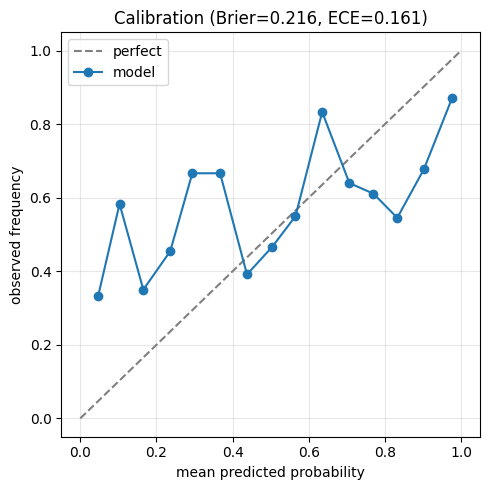

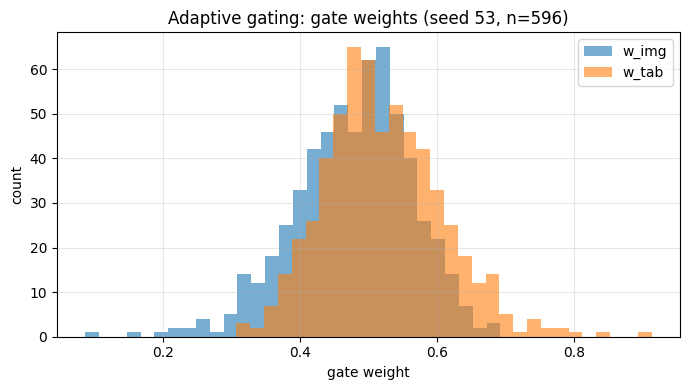

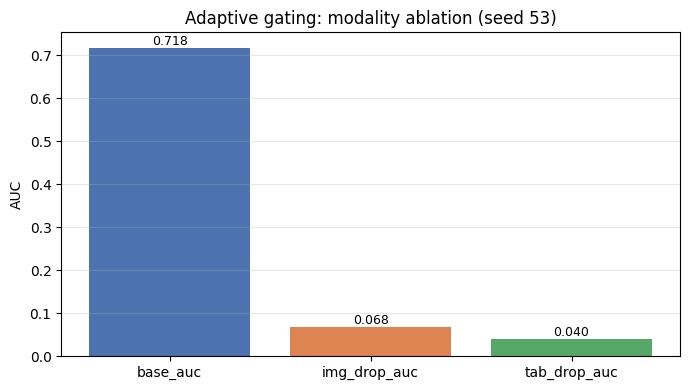

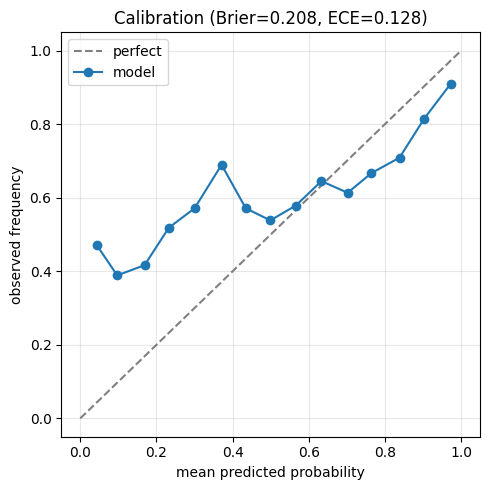

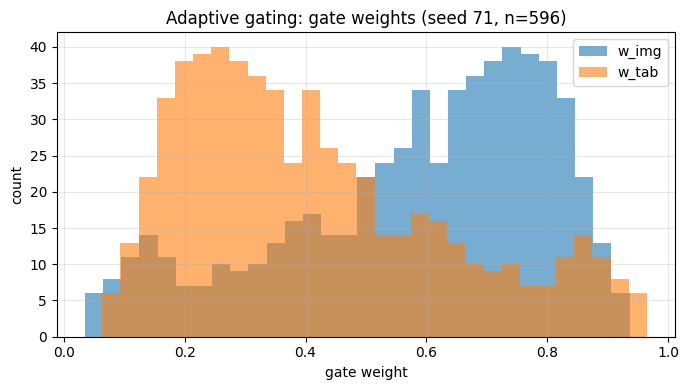

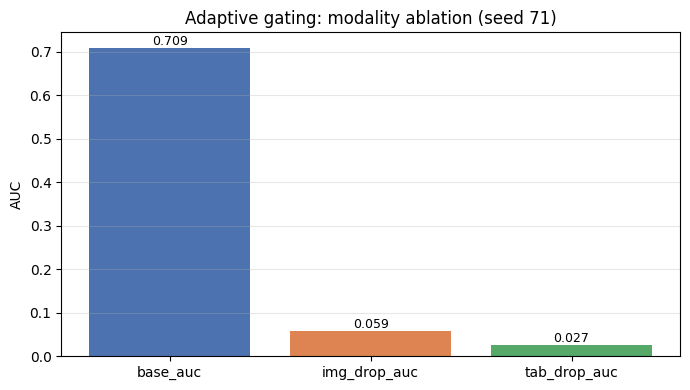

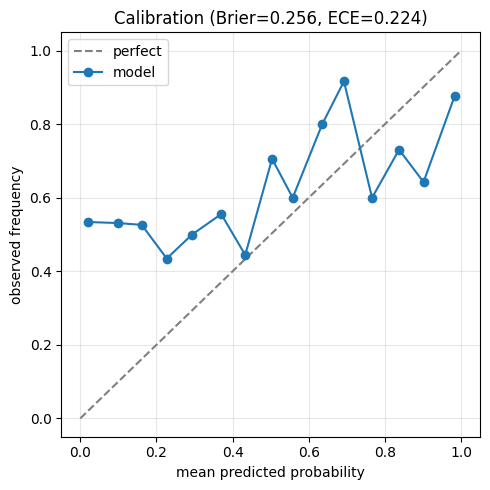

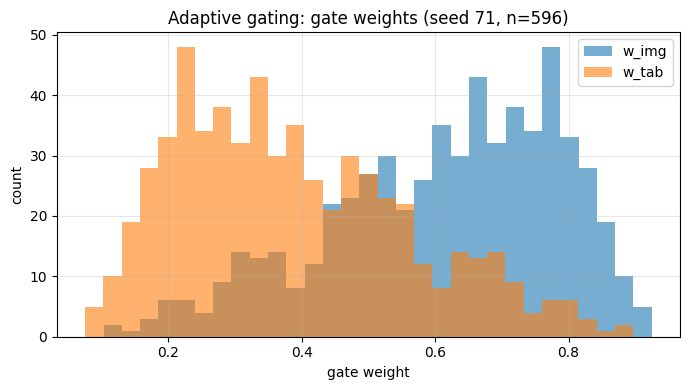

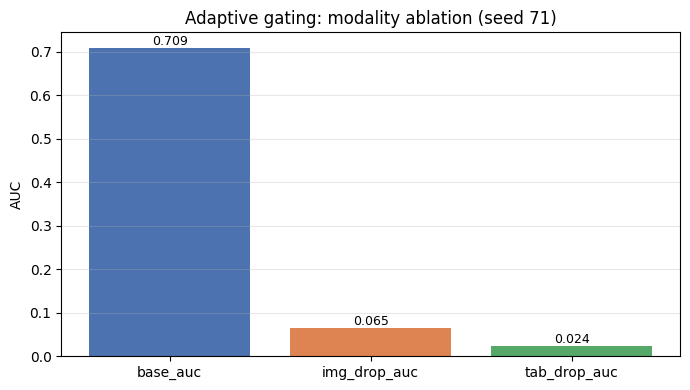

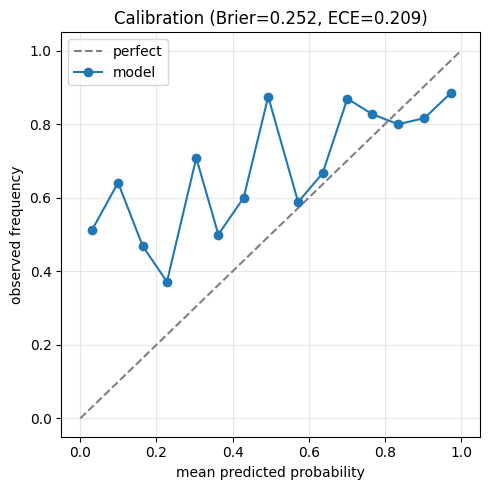

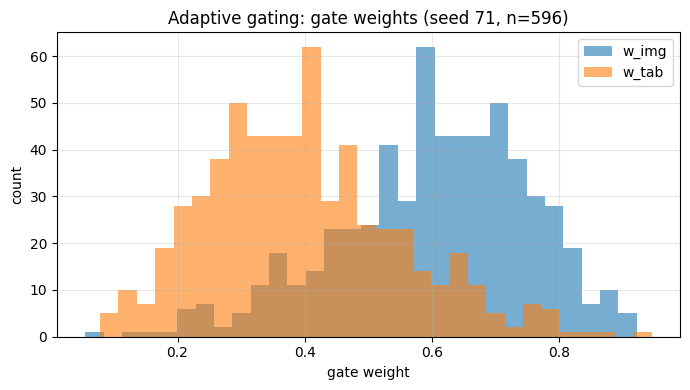

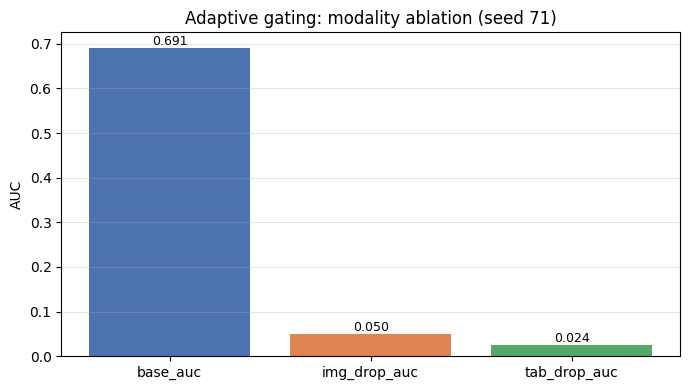

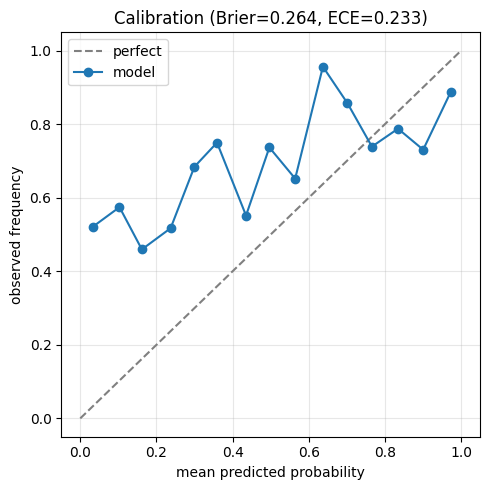

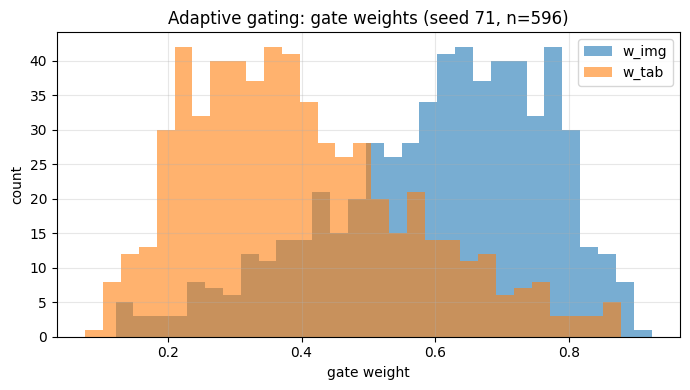

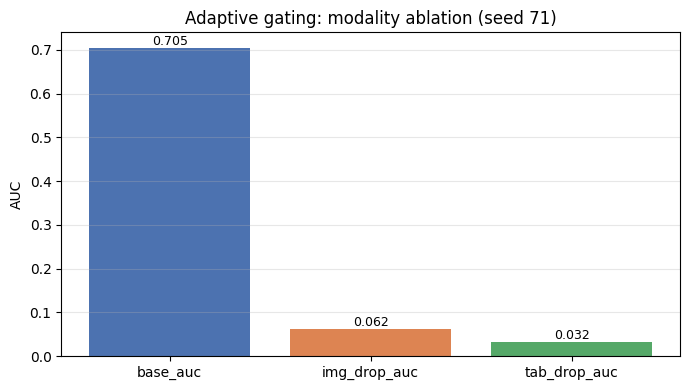

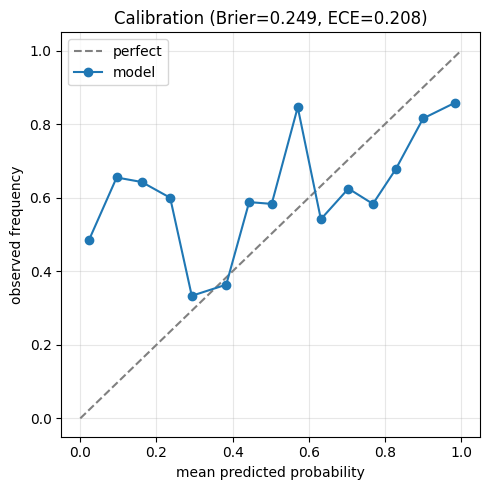

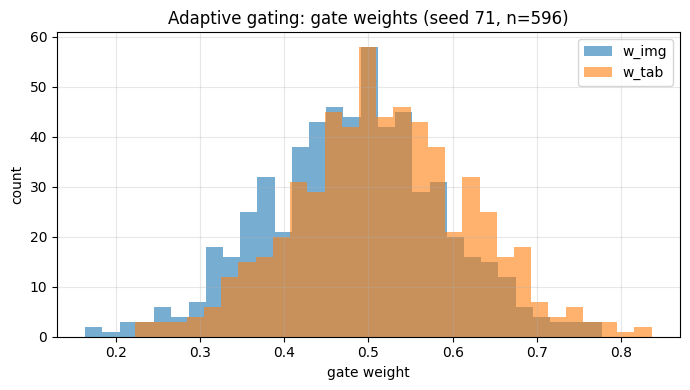

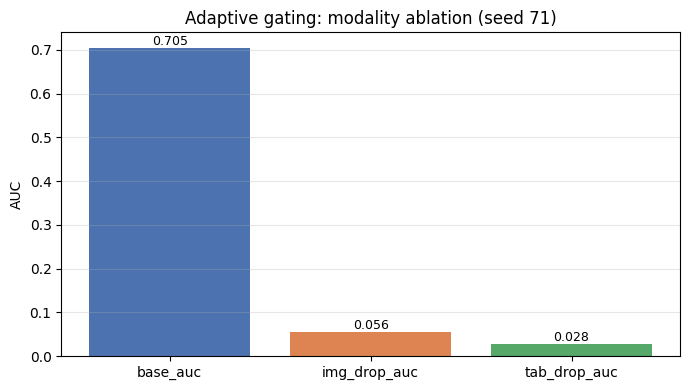

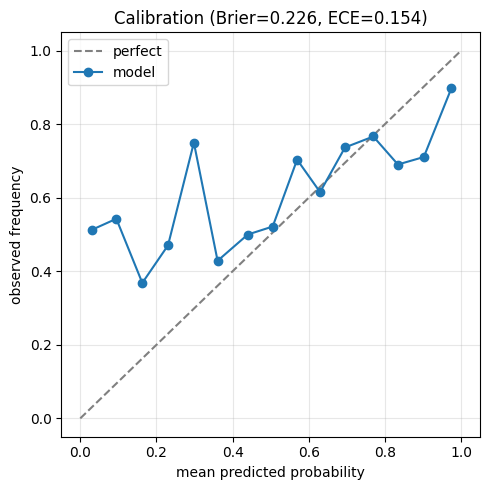

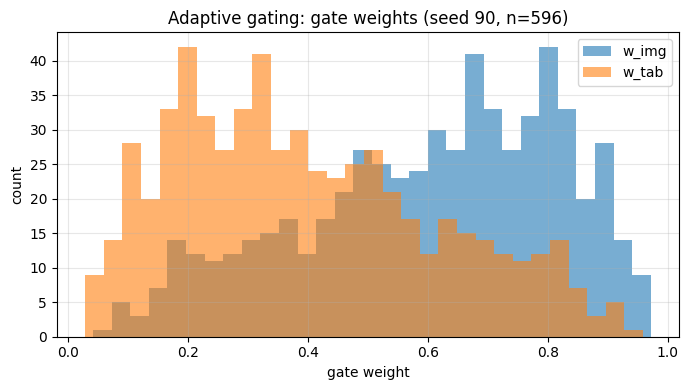

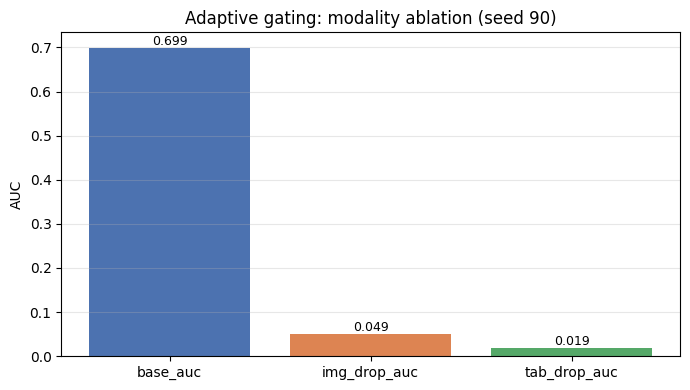

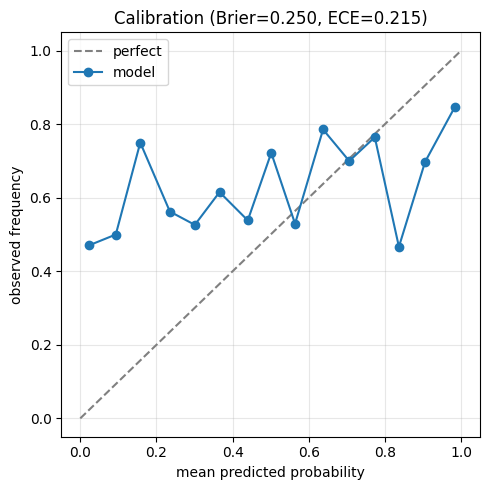

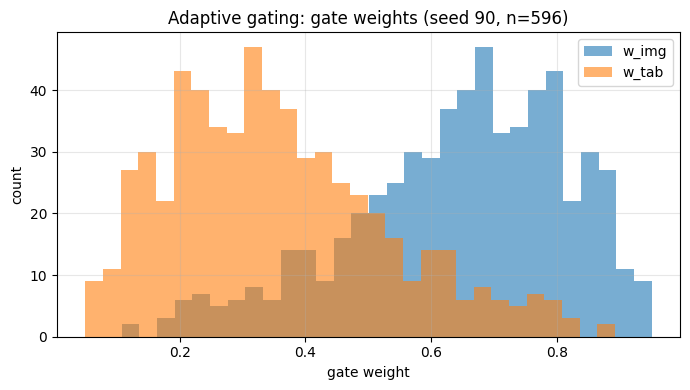

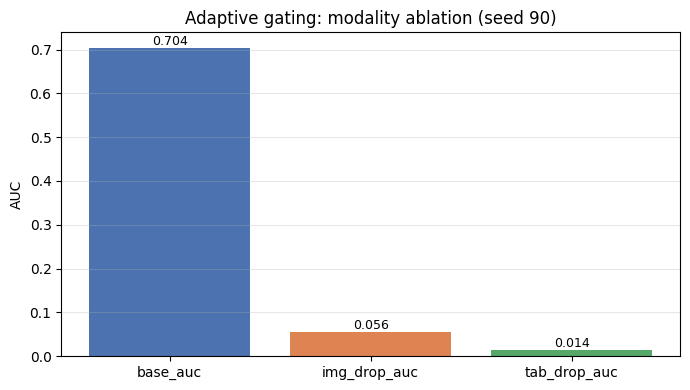

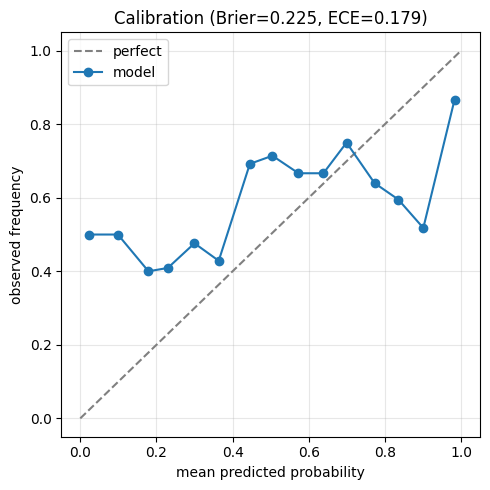

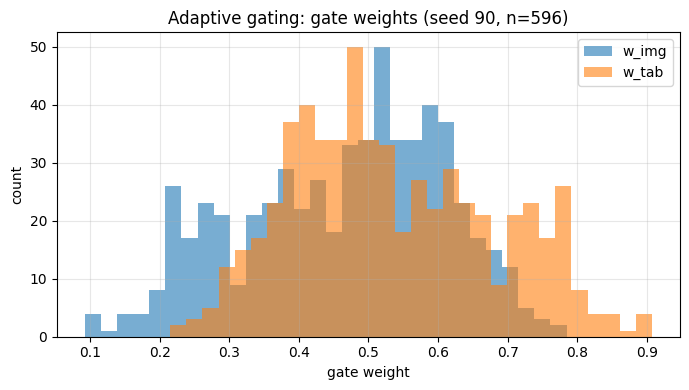

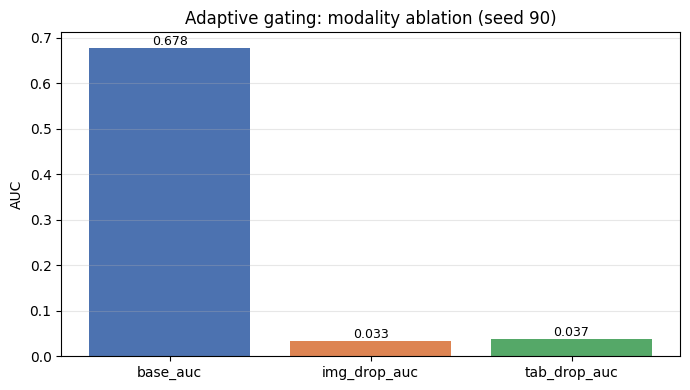

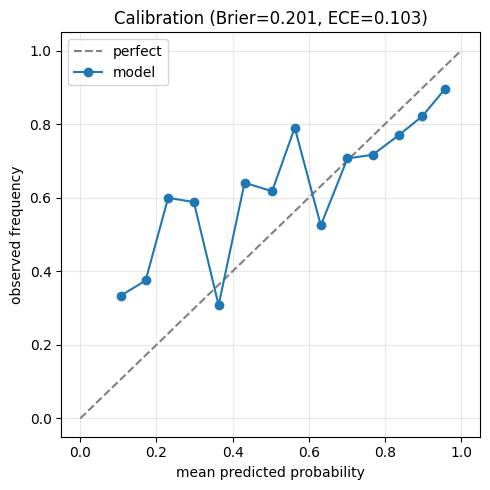

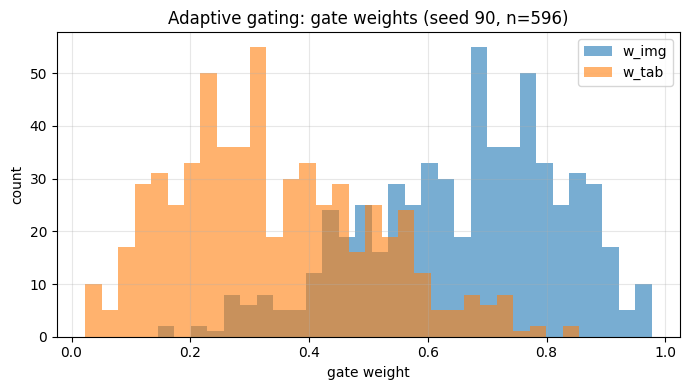

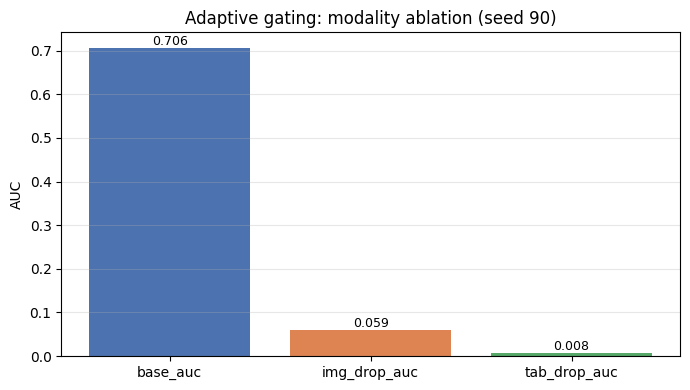

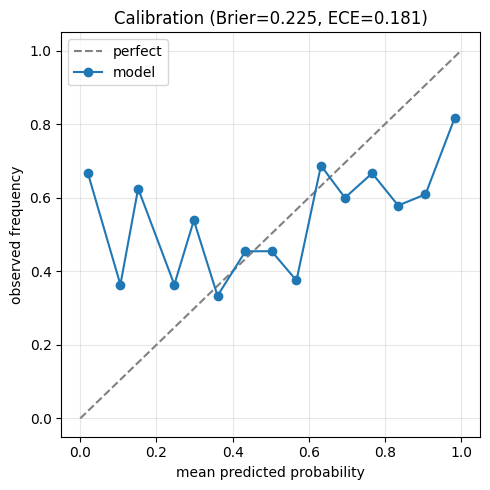

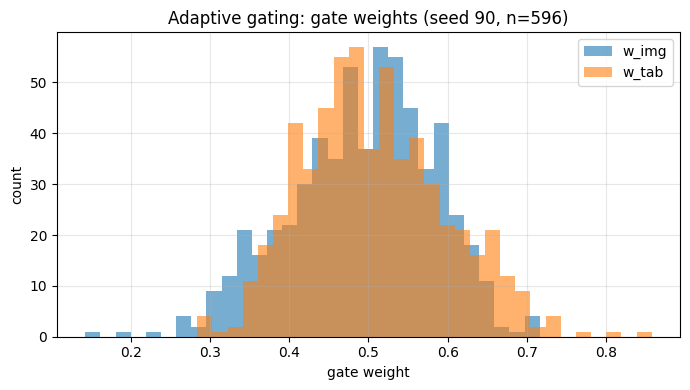

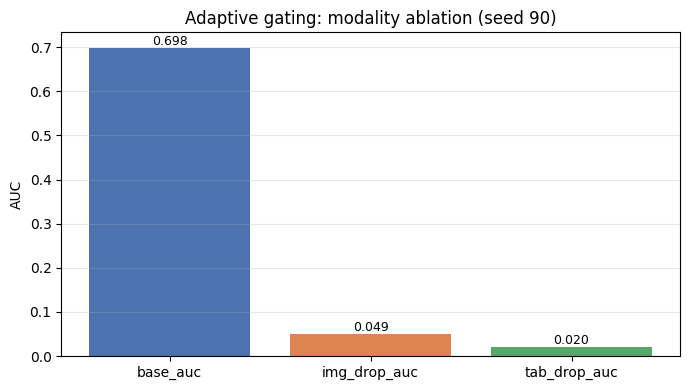

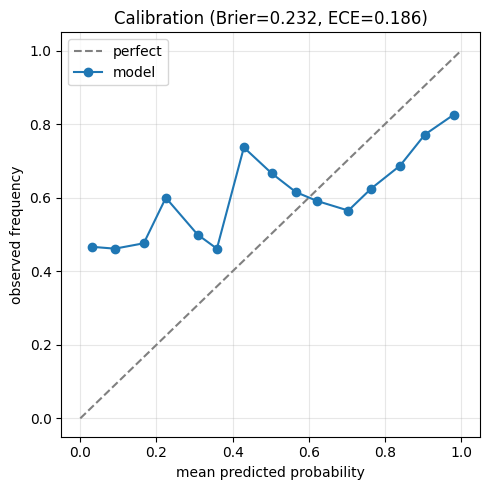

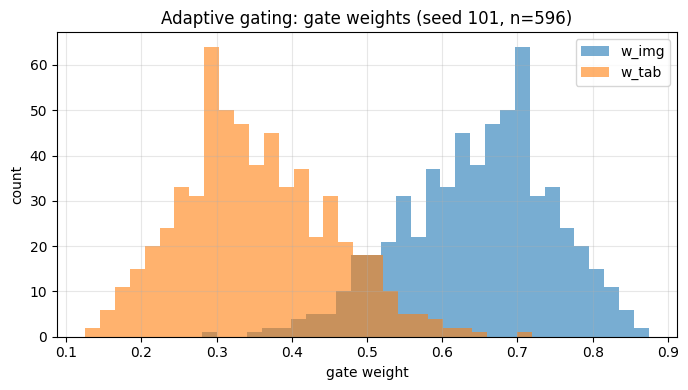

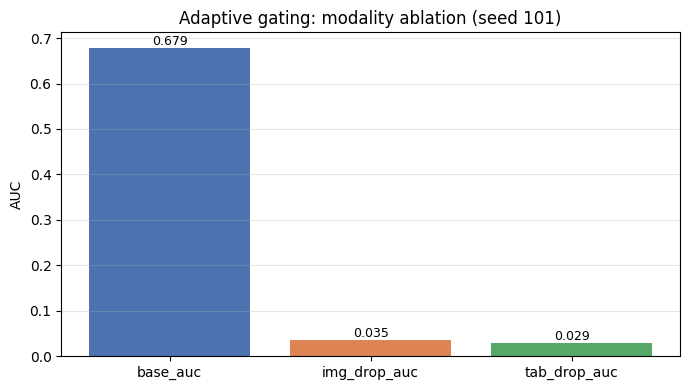

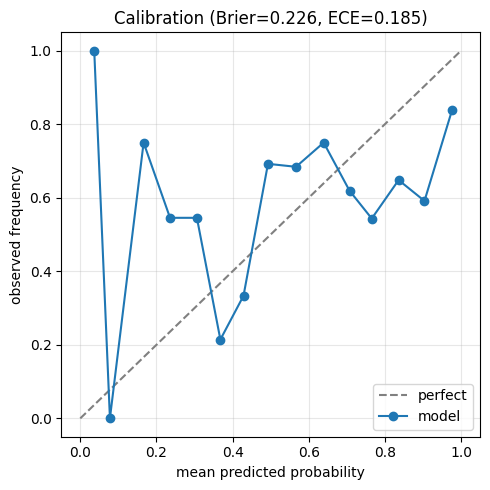

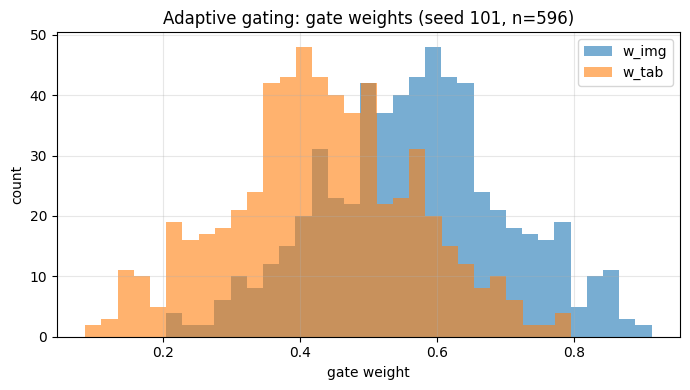

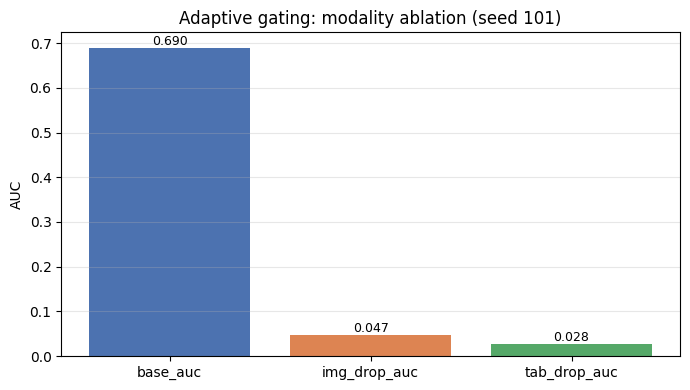

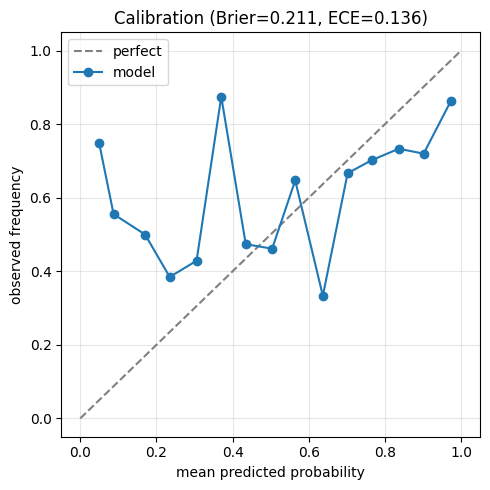

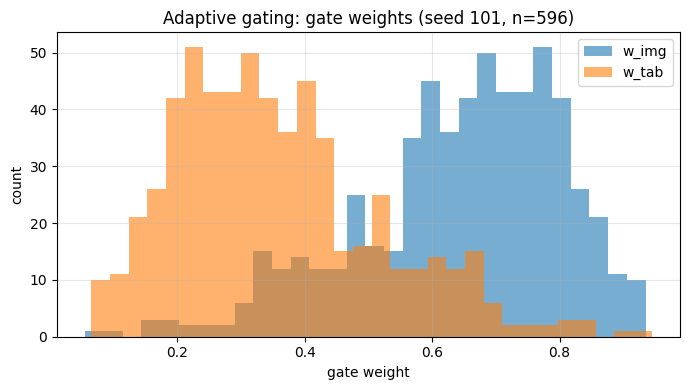

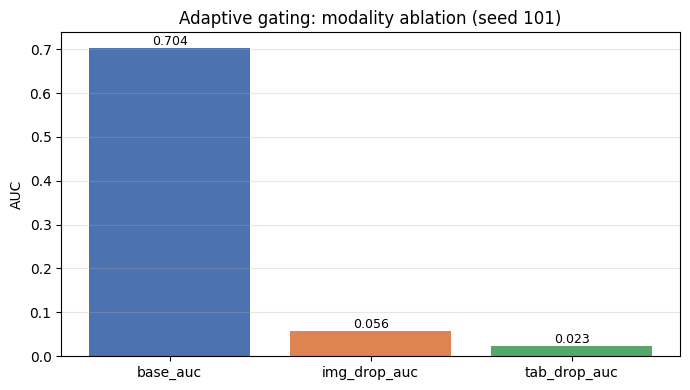

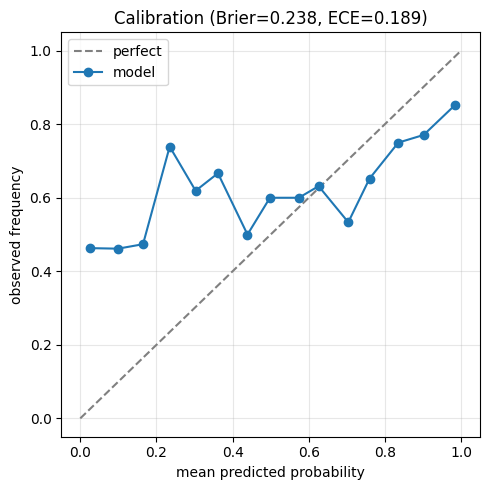

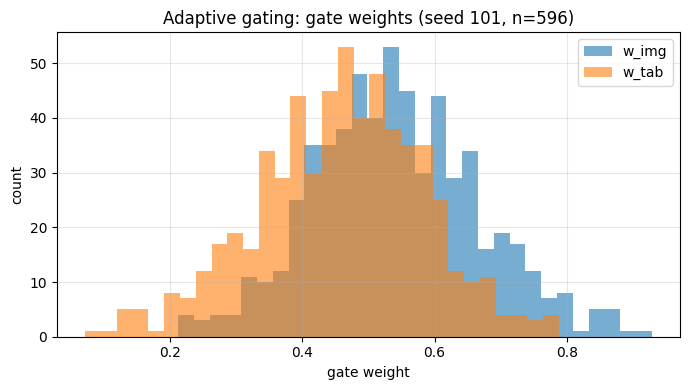

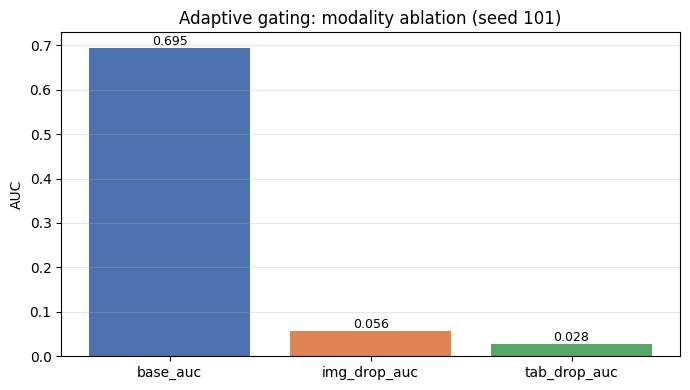

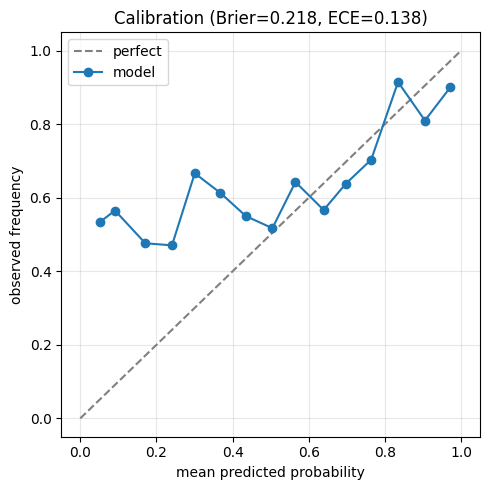

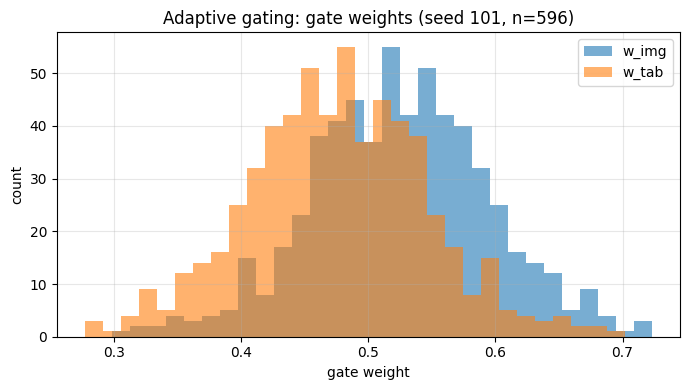

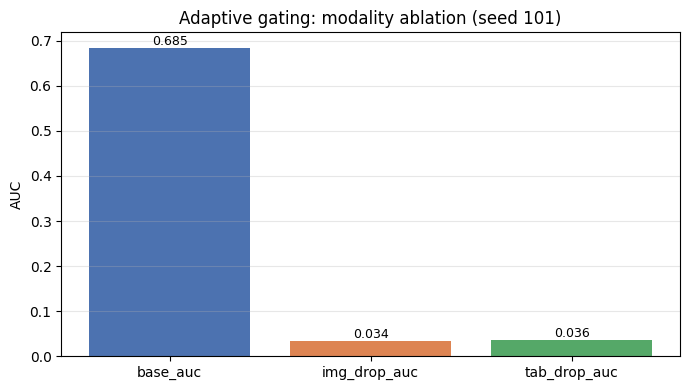

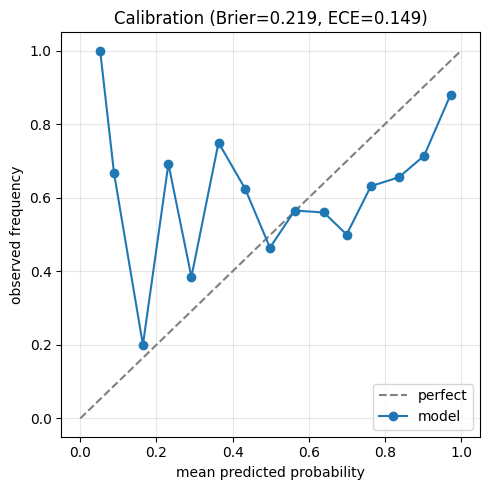

,run_id,setting_tag,seed,entropy_weight,run_dir,base_auc,img_drop_auc,tab_drop_auc,brier,ece,n,gate_weight_mean_img,gate_weight_mean_tab,gate_weight_std_img,gate_entropy_mean,gate_entropy_std,gate_selective_fraction,spearman_w_img_delta_img,spearman_w_tab_delta_tab
0,20261020-020650/seed_8__ent0e+00__e20,ent0e+00,8,0.0000,/mnt/disk1/home/cgiovannoni/mod-attendance/art...,0.707995,0.076089,0.016863,0.237616,0.196393,596,0.656763,0.343237,0.149667,0.591453,0.108487,0.033557,-0.011132,0.218306
1,20261020-020650/seed_8__base__e20,base,8,0.0001,/mnt/disk1/home/cgiovannoni/mod-attendance/art...,0.686113,0.049364,0.022294,0.249993,0.212473,596,0.679062,0.320937,0.147338,0.576883,0.107211,0.031879,0.191853,0.502998
2,20261020-020650/seed_8__ent1e-03__e20,ent1e-03,8,0.0010,/mnt/disk1/home/cgiovannoni/mod-attendance/art...,0.700507,0.053152,0.023410,0.225546,0.183145,596,0.684735,0.315265,0.137940,0.578466,0.104548,0.021812,0.210840,0.582377
3,20261020-020650/seed_8__ent1e-02__e20,ent1e-02,8,0.0100,/mnt/disk1/home/cgiovannoni/mod-attendance/art...,0.692018,0.040983,0.031656,0.214320,0.126608,596,0.460692,0.539308,0.119149,0.660596,0.045493,0.000000,0.100263,0.066543
4,20261020-020650/seed_8__ent1e-01__e20,ent1e-01,8,0.1000,/mnt/disk1/home/cgiovannoni/mod-attendance/art...,0.693621,0.041822,0.032982,0.208211,0.113768,596,0.501214,0.498786,0.089916,0.676625,0.027555,0.000000,0.233973,0.148992
5,20261020-020650/seed_47__ent0e+00__e20,ent0e+00,47,0.0000,/mnt/disk1/home/cgiovannoni/mod-attendance/art...,0.699107,0.050108,0.026752,0.279599,0.257679,596,0.611002,0.388998,0.130967,0.631477,0.064357,0.001678,0.033810,0.467454
6,20261020-020650/seed_47__base__e20,base,47,0.0001,/mnt/disk1/home/cgiovannoni/mod-attendance/art...,0.676813,0.041322,0.025697,0.230845,0.170331,596,0.618903,0.381097,0.175227,0.595747,0.111868,0.035235,0.227926,0.666128
7,20261020-020650/seed_47__ent1e-03__e20,ent1e-03,47,0.0010,/mnt/disk1/home/cgiovannoni/mod-attendance/art...,0.689658,0.041065,0.032961,0.199665,0.100977,596,0.469813,0.530187,0.126372,0.658318,0.043891,0.000000,0.458690,0.618585
8,20261020-020650/seed_47__ent1e-02__e20,ent1e-02,47,0.0100,/mnt/disk1/home/cgiovannoni/mod-attendance/art...,0.662162,0.011790,0.063278,0.196995,0.063131,596,0.469834,0.530166,0.103144,0.669653,0.025015,0.000000,0.106216,0.067832
9,20261020-020650/seed_47__ent1e-01__e20,ent1e-01,47,0.1000,/mnt/disk1/home/cgiovannoni/mod-attendance/art...,0.701508,0.051847,0.026887,0.236083,0.175482,596,0.521466,0.478534,0.079409,0.679398,0.021216,0.000000,0.119733,0.455100


In [ ]:
# @@GATE_DIAGNOSTICS@@ — gate weights, ablation and calibration per adaptive-gating run (GPU)
import keras
from isic24 import xai_driver as xd, xai_logit as xl

_TRAINED = ["base_auc", "img_drop_auc", "tab_drop_auc", "brier", "ece"]
_NEEDED = {"run_id", "run_dir", "setting_tag", "seed", "entropy_weight", *_TRAINED}
assert _NEEDED <= set(ag_combined.columns), f"Missing gate columns: {_NEEDED - set(ag_combined.columns)}"
assert ag_combined.run_id.is_unique, "Duplicate gate runs"
assert len(ag_combined) == len(TRAINING_SEEDS) * EXPECTED_SETTINGS["adaptive_gating"], (
    "Incomplete adaptive-gating study aggregate; rerun the updated training sweep"
)
assert not ag_combined.duplicated(["setting_tag", "seed"]).any(), "Duplicate setting/seed"
assert ag_combined.groupby("setting_tag").seed.apply(
    lambda values: set(values) == set(TRAINING_SEEDS)
).all(), "Gate seed grid mismatch"
assert set(ag_combined.entropy_weight) == {0.0, 1e-4, 1e-3, 1e-2, 1e-1}, "Gate entropy grid mismatch"

all_diag = []
for _, row in ag_combined.iterrows():
    ag_run_dir = xs.run_dir_abs(row["run_dir"], ART_PATH)
    ag_model, _ = xd.load_run_model(ag_run_dir)
    gate = xl.gate_per_sample(ag_model, validation_ds)

    _auc = keras.metrics.AUC()
    _auc.update_state(gate.target.to_numpy(), gate.prediction.to_numpy())
    _seen = {"base_auc": float(_auc.result().numpy()),
             "brier": float(np.mean((gate.prediction - gate.target) ** 2))}
    _off = {k: (v, float(row[k])) for k, v in _seen.items() if abs(v - float(row[k])) > 5e-3}
    assert not _off, (f"{row['run_id']}: the checkpoint disagrees with what training recorded, "
                      f"{_off} as (post-hoc, training) — same weights on the same frame")

    diag = dict(run_id=row["run_id"], setting_tag=row["setting_tag"], seed=int(row["seed"]),
                entropy_weight=float(row["entropy_weight"]), run_dir=ag_run_dir,
                **{c: float(row[c]) for c in _TRAINED}, **xl.gate_summary(gate))
    os.makedirs(os.path.join(ag_run_dir, "diagnostics"), exist_ok=True)
    with open(os.path.join(ag_run_dir, "diagnostics", "adaptive_gating_diagnostics.json"), "w") as f:
        json.dump(diag, f, indent=2)
    all_diag.append(diag)

    plots_dir = os.path.join(ag_run_dir, "plots")
    os.makedirs(plots_dir, exist_ok=True)

    plt.figure(figsize=(7, 4))
    plt.hist(gate.w_img, bins=30, alpha=0.6, label="w_img")
    plt.hist(gate.w_tab, bins=30, alpha=0.6, label="w_tab")
    plt.xlabel("gate weight"); plt.ylabel("count")
    plt.title(f"Adaptive gating: gate weights (seed {int(row['seed'])}, n={diag['n']})")
    plt.legend(); plt.grid(alpha=0.3)
    _finalize_plot(plots_dir, "gate_weight_distribution.png")

    plt.figure(figsize=(7, 4))
    _bars = ["base_auc", "img_drop_auc", "tab_drop_auc"]
    _vals = [diag[c] for c in _bars]
    plt.bar(_bars, _vals, color=["#4c72b0", "#dd8452", "#55a868"])
    for j, v in enumerate(_vals):
        plt.text(j, v, f"{v:.3f}", ha="center", va="bottom", fontsize=9)
    plt.ylabel("AUC"); plt.grid(alpha=0.3, axis="y")
    plt.title(f"Adaptive gating: modality ablation (seed {int(row['seed'])})")
    _finalize_plot(plots_dir, "modality_ablation_auc_drop.png")

    _edges = np.linspace(0.0, 1.0, 16)
    _conf, _obs = [], []
    for _lo, _hi in zip(_edges[:-1], _edges[1:]):
        _m = (gate.prediction >= _lo) & ((gate.prediction <= _hi) if _hi >= 1.0
                                         else (gate.prediction < _hi))
        if _m.any():
            _conf.append(float(gate.prediction[_m].mean()))
            _obs.append(float(gate.target[_m].mean()))
    plt.figure(figsize=(5, 5))
    plt.plot([0, 1], [0, 1], "--", color="gray", label="perfect")
    plt.plot(_conf, _obs, marker="o", label="model")
    plt.xlabel("mean predicted probability"); plt.ylabel("observed frequency")
    plt.title(f"Calibration (Brier={diag['brier']:.3f}, ECE={diag['ece']:.3f})")
    plt.legend(); plt.grid(alpha=0.3)
    _finalize_plot(plots_dir, "calibration_reliability.png")

    keras.backend.clear_session()
    gc.collect()

ag_diag_df = pd.DataFrame(all_diag)
_diag_csv = os.path.join(ag_study_dir, "adaptive_gating_diagnostics.csv")
xs.stamp_aggregate(_diag_csv, ag_diag_df.run_id)
ag_diag_df.to_csv(_diag_csv, index=False)
display(ag_diag_df)

In [ ]:
# @@CF_GAMMA_SWEEP@@ — complete frozen gamma metrics and plot the saved evaluations
from isic24.fusion_calibration import complete_gamma_calibration

posthoc_agg = complete_gamma_calibration(cf_study_dir, include_attendance=True)
posthoc_all_df = pd.read_csv(os.path.join(cf_study_dir, "controlled_fusion_posthoc_gamma_summary.csv"))
for _, row in cf_combined.iterrows():
    cf_run_dir = xs.run_dir_abs(row["run_dir"], ART_PATH)
    posthoc_df = posthoc_all_df[posthoc_all_df.run_id == row.run_id].sort_values("gamma_tab")
    plots_dir = os.path.join(cf_run_dir, "plots")
    os.makedirs(plots_dir, exist_ok=True)

    plt.figure(figsize=(7, 4))
    plt.plot(posthoc_df["gamma_tab"], posthoc_df["val_auc"], marker="o")
    plt.axvline(1.0, linestyle="--", linewidth=1)
    plt.xlabel("gamma_tab")
    plt.ylabel("val_auc")
    plt.title(f"Controlled fusion post-hoc: val_auc vs gamma_tab (seed {int(row['seed'])})")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(plots_dir, "posthoc_val_auc_vs_gamma_tab.png"), dpi=300)
    plt.close()

    plt.figure(figsize=(7, 4))
    plt.scatter(posthoc_df["gamma_img"], posthoc_df["gamma_tab"], c=posthoc_df["val_auc"])
    for _, r in posthoc_df.iterrows():
        plt.text(r["gamma_img"], r["gamma_tab"], f"{r['val_auc']:.3f}", fontsize=8)
    plt.xlabel("gamma_img")
    plt.ylabel("gamma_tab")
    plt.title(f"Controlled fusion post-hoc sweep (seed {int(row['seed'])})")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(plots_dir, "posthoc_gamma_sweep_scatter.png"), dpi=300)
    plt.close()

display(posthoc_agg)


,delta,gamma_img,gamma_tab,mean,std,count,brier_mean,brier_std,ece_mean,ece_std,img_drop_auc_mean,img_drop_auc_std,tab_drop_auc_mean,tab_drop_auc_std,modality_balance_mean,modality_balance_std
0,-0.500,1.500,0.500,0.684056,0.007248,6,0.276186,0.045784,0.245485,0.062916,0.038635,0.005906,0.012774,0.005592,0.246203,0.095915
1,-0.375,1.375,0.625,0.689326,0.007046,6,0.270008,0.044373,0.234831,0.061980,0.044060,0.005849,0.017705,0.005694,0.284558,0.073705
2,-0.250,1.250,0.750,0.693154,0.005842,6,0.263414,0.042570,0.227380,0.057591,0.047767,0.004715,0.021122,0.006998,0.301836,0.075606
3,-0.125,1.125,0.875,0.697918,0.005605,6,0.256390,0.040263,0.213404,0.060924,0.052401,0.005346,0.025074,0.007473,0.319853,0.065357
4,0.000,1.000,1.000,0.700957,0.005238,6,0.249035,0.037428,0.205560,0.057010,0.055747,0.005381,0.028578,0.008038,0.335018,0.063905
5,0.125,0.875,1.125,0.704072,0.005275,6,0.241593,0.034148,0.193850,0.056409,0.058711,0.005042,0.031639,0.008037,0.346708,0.058648
6,0.250,0.750,1.250,0.705190,0.005010,6,0.234488,0.030696,0.185847,0.051264,0.060189,0.004260,0.032754,0.007739,0.349361,0.056162
7,0.375,0.625,1.375,0.703898,0.005184,6,0.228392,0.027574,0.169245,0.051840,0.058514,0.002753,0.031345,0.007852,0.344910,0.060712
8,0.500,0.500,1.500,0.699802,0.005965,6,0.224115,0.025251,0.158034,0.049766,0.054503,0.002371,0.027380,0.008630,0.327805,0.075253


## Analysis — reads the artifacts above, loads no checkpoint

`faithfulness_gain = deletion_auc(explanation) − deletion_auc(random)`, over `tabular` (SHAP or
the aligned ranking), `image` (Grad-CAM) and `joint`. Every cell below reads what the block
above wrote, none of them loads a model, and the order among them is free.

In [ ]:
# @@STRATA_SECTION@@ 1/3 — build the full faithfulness table from the saved curves
from isic24 import xai_faithfulness as xf

FAITH_STRATA_SIGNED = True    # include the signed variants

_files = xf.discover_curve_files(ART_PATH, include_signed=FAITH_STRATA_SIGNED)
print("[curve] coverage by source:")
display(_files.groupby("source").agg(run=("run_id", "nunique"), file=("npz_path", "size")))

# Guard: the mean of the per-sample gains must reproduce the aggregate saved in the JSONs.
_probs = xf.verify_reintegration(_files[_files.source == "canonical"].npz_path.iloc[0])
print("[guard] verify_reintegration:", "OK (<1e-9)" if not _probs else f"** FAILED ** {_probs}")

strata = xf.stratified_table(ART_PATH, files=_files, q_maxes=tuple(Q_MAX_REPORT), verbose=False)
pooled = xf.pool_by_family(strata)

_p1 = os.path.join(RUNS_PATH, "_faithfulness", "faithfulness_strata.csv")
_p2 = os.path.join(RUNS_PATH, "_faithfulness", "faithfulness_strata_pooled.csv")
xs.stamp_aggregate(_p1, strata.run_id, q_maxes=list(Q_MAX_REPORT), signed=FAITH_STRATA_SIGNED)
strata.to_csv(_p1, index=False)
pooled.to_csv(_p2, index=False)
print(f"\n[wrote] {_p1}   ({len(strata)} rows: one per run x source x cell)")
print(f"[wrote] {_p2}   ({len(pooled)} rows, pooled by family)")
print("\nBoth are derived: this cell regenerates them at any time, they are not canonical.")

[curve] coverage by source:


,run,file
source,,
aligned_signed,156,624
canonical,156,156
gradient,156,156


[guard] verify_reintegration: OK (<1e-9)
  [ablations] faithfulness strata: 6480 unimodal endpoint runs excluded from the aggregate

[wrote] /mnt/disk1/home/cgiovannoni/mod-attendance/artifacts/cmmd/processed/runs/_faithfulness/faithfulness_strata.csv   (84240 rows: one per run x source x cell)
[wrote] /mnt/disk1/home/cgiovannoni/mod-attendance/artifacts/cmmd/processed/runs/_faithfulness/faithfulness_strata_pooled.csv   (3240 rows, pooled by family)

Both are derived: this cell regenerates them at any time, they are not canonical.


In [ ]:
# @@STRATA_SECTION@@ 2/3 — summary table: one row per family, every attributor side by side
# Deletion, stratum "all", column gain_norm (per unit of budget); positive = faithful.
_h = pooled[(pooled.stratum == "all") & (pooled.direction == "del")].copy()
_h["attributor"] = np.where(
    _h.source == "canonical", "perm:" + _h.method,
    np.where(_h.source == "gradient", "SHAPgrad:" + _h.method, "signed:" + _h["mode"]))

_piv = _h.pivot_table(index="impl_name", columns=["attributor", "q_max"], values="gain_norm")
print("gain_norm — deletion, all samples (positive = faithful)")
display(_piv.round(3))

# How many runs sit behind each number.
print("\nruns per cell (n_runs):")
display(_h.pivot_table(index="impl_name", columns="attributor", values="n_runs", aggfunc="max"))

print("attributors: perm:* = logit-aligned Permutation on the named branch | "
      "SHAPgrad:* = SHAP GradientExplainer on the named branch | "
      "signed:* = the Permutation again, evidence for/against. The two rankings are read "
      "side by side and never averaged together.")

gain_norm — deletion, all samples (positive = faithful)


attributor          SHAPgrad:joint        SHAPgrad:tabular        perm:image  \
q_max                          0.2    0.6              0.2    0.6        0.2   
impl_name                                                                      
adaptive_gating              0.376  0.294            0.036  0.096      0.331   
controlled_fusion            0.492  0.366            0.030  0.075      0.458   
fixed_scaling                0.178  0.170            0.018  0.046      0.158   
learnable_scaling            0.304  0.320            0.018  0.045      0.285   
loss_regularization          0.260  0.222            0.025  0.065      0.233   
vanilla                      0.266  0.208            0.028  0.075      0.238   

attributor                 perm:joint        perm:tabular        signed:abs  \
q_max                  0.6        0.2    0.6          0.2    0.6        0.2   
impl_name                                                                     
adaptive_gating      0.189      0.358  0.270        0.029  0.072      0.029   
controlled_fusion    0.306      0.462  0.335        0.025  0.058      0.025   
fixed_scaling        0.126      0.167  0.154        0.015  0.035      0.015   
learnable_scaling    0.281      0.290  0.299        0.015  0.034      0.015   
loss_regularization  0.168      0.242  0.203        0.022  0.052      0.022   
vanilla              0.147      0.252  0.195        0.025  0.061      0.025   

attributor                 signed:negev        signed:posev         \
q_max                  0.6          0.2    0.6          0.2    0.6   
impl_name                                                            
adaptive_gating      0.072        0.091  0.285        0.119  0.346   
controlled_fusion    0.058        0.105  0.327        0.135  0.393   
fixed_scaling        0.035        0.068  0.208        0.083  0.246   
learnable_scaling    0.034        0.068  0.209        0.083  0.246   
loss_regularization  0.052        0.080  0.249        0.101  0.297   
vanilla              0.061        0.084  0.261        0.107  0.313   

attributor          signed:target         
q_max                         0.2    0.6  
impl_name                                 
adaptive_gating             0.114  0.337  
controlled_fusion           0.130  0.381  
fixed_scaling               0.083  0.243  
learnable_scaling           0.083  0.243  
loss_regularization         0.100  0.292  
vanilla                     0.105  0.308


runs per cell (n_runs):


attributor,SHAPgrad:joint,SHAPgrad:tabular,perm:image,perm:joint,perm:tabular,signed:abs,signed:negev,signed:posev,signed:target
impl_name,,,,,,,,,
adaptive_gating,30,30,30,30,30,30,30,30,30
controlled_fusion,6,6,6,6,6,6,6,6,6
fixed_scaling,42,42,42,42,42,42,42,42,42
learnable_scaling,30,30,30,30,30,30,30,30,30
loss_regularization,30,30,30,30,30,30,30,30,30
vanilla,6,6,6,6,6,6,6,6,6


attributors: perm:* = logit-aligned Permutation on the named branch | SHAPgrad:* = SHAP GradientExplainer on the named branch | signed:* = the Permutation again, evidence for/against. The two rankings are read side by side and never averaged together.


In [ ]:
# @@STRATA_SECTION@@ 3/3 — strata: by class, and by confidence x correctness
# Shown at the low cutoff, the clean regime; at full budget the metric is OOD-dominated.
STRATA_SHOW = ["all", "class_pos", "class_neg",
               "sure_correct", "sure_wrong", "unsure_correct", "unsure_wrong"]
_QLOW = min(Q_MAX_REPORT)

_s = pooled[(pooled.direction == "del") & (pooled.q_max == _QLOW)
            & (pooled.stratum.isin(STRATA_SHOW))]

for _src, _mode, _meth, _title in [
        ("canonical", "abs", "tabular", "aligned Permutation — tabular"),
        ("gradient", "abs", "tabular", "SHAP GradientExplainer — tabular"),
        ("canonical", "abs", "joint", "aligned Permutation — joint"),
        ("gradient", "abs", "joint", "SHAP GradientExplainer — joint"),
        ("aligned_signed", "target", "tabular", "signed Permutation — true class (`target`)")]:
    _t = _s[(_s.source == _src) & (_s["mode"] == _mode) & (_s.method == _meth)]
    if not len(_t):
        print(f"\n[{_title}] no rows — source not on disk.")
        continue
    print(f"\n{_title}   (deletion, q<={_QLOW}, gain_norm)")
    display(_t.pivot_table(index="impl_name", columns="stratum", values="gain_norm")
              .reindex(columns=[c for c in STRATA_SHOW if c in set(_t.stratum)]).round(3))

print("\nEmpty cells are withheld on purpose below MIN_CELL_N; column `n` in `strata` "
      "gives the real sample count.")


aligned Permutation — tabular   (deletion, q<=0.2, gain_norm)


stratum,all,class_pos,class_neg,sure_correct,sure_wrong,unsure_correct,unsure_wrong
impl_name,,,,,,,
adaptive_gating,0.029,0.059,-0.002,0.067,0.074,-0.020,-0.002
controlled_fusion,0.025,0.064,-0.013,0.060,0.032,-0.004,0.003
fixed_scaling,0.015,0.044,-0.014,0.041,0.022,-0.008,-0.002
learnable_scaling,0.015,0.043,-0.014,0.045,0.029,-0.013,-0.008
loss_regularization,0.022,0.056,-0.013,0.057,0.036,-0.011,-0.003
vanilla,0.025,0.062,-0.012,0.056,0.041,-0.006,0.003



SHAP GradientExplainer — tabular   (deletion, q<=0.2, gain_norm)


stratum,all,class_pos,class_neg,sure_correct,sure_wrong,unsure_correct,unsure_wrong
impl_name,,,,,,,
adaptive_gating,0.036,0.069,0.004,0.077,0.081,-0.013,0.003
controlled_fusion,0.030,0.069,-0.009,0.068,0.038,-0.001,0.004
fixed_scaling,0.018,0.046,-0.010,0.044,0.026,-0.006,0.000
learnable_scaling,0.018,0.046,-0.010,0.048,0.033,-0.012,-0.005
loss_regularization,0.025,0.059,-0.009,0.061,0.041,-0.009,0.000
vanilla,0.028,0.064,-0.009,0.059,0.044,-0.003,0.005



aligned Permutation — joint   (deletion, q<=0.2, gain_norm)


stratum,all,class_pos,class_neg,sure_correct,sure_wrong,unsure_correct,unsure_wrong
impl_name,,,,,,,
adaptive_gating,0.358,0.573,0.142,0.647,0.486,0.101,0.139
controlled_fusion,0.462,0.673,0.252,0.716,0.353,0.261,0.388
fixed_scaling,0.167,0.382,-0.047,0.457,0.259,-0.097,-0.029
learnable_scaling,0.290,0.501,0.079,0.602,0.422,-0.025,0.091
loss_regularization,0.242,0.497,-0.014,0.539,0.274,-0.003,0.050
vanilla,0.252,0.543,-0.039,0.509,0.310,0.042,0.060



SHAP GradientExplainer — joint   (deletion, q<=0.2, gain_norm)


stratum,all,class_pos,class_neg,sure_correct,sure_wrong,unsure_correct,unsure_wrong
impl_name,,,,,,,
adaptive_gating,0.376,0.599,0.154,0.690,0.501,0.101,0.146
controlled_fusion,0.492,0.721,0.263,0.768,0.419,0.276,0.376
fixed_scaling,0.178,0.410,-0.055,0.490,0.270,-0.099,-0.038
learnable_scaling,0.304,0.536,0.072,0.630,0.426,-0.027,0.107
loss_regularization,0.260,0.531,-0.012,0.569,0.293,0.003,0.061
vanilla,0.266,0.572,-0.039,0.537,0.323,0.026,0.091



signed Permutation — true class (`target`)   (deletion, q<=0.2, gain_norm)


stratum,all,class_pos,class_neg,sure_correct,sure_wrong,unsure_correct,unsure_wrong
impl_name,,,,,,,
adaptive_gating,0.114,0.126,0.102,0.145,0.096,0.105,0.090
controlled_fusion,0.130,0.148,0.112,0.162,0.097,0.121,0.113
fixed_scaling,0.083,0.090,0.075,0.108,0.060,0.074,0.069
learnable_scaling,0.083,0.090,0.076,0.107,0.061,0.076,0.068
loss_regularization,0.100,0.110,0.089,0.129,0.072,0.090,0.084
vanilla,0.105,0.117,0.094,0.137,0.075,0.093,0.088



Empty cells are withheld on purpose below MIN_CELL_N; column `n` in `strata` gives the real sample count.



canonical ranking — tabular
  [ablations] report figures: 12 unimodal endpoint runs excluded from the aggregate


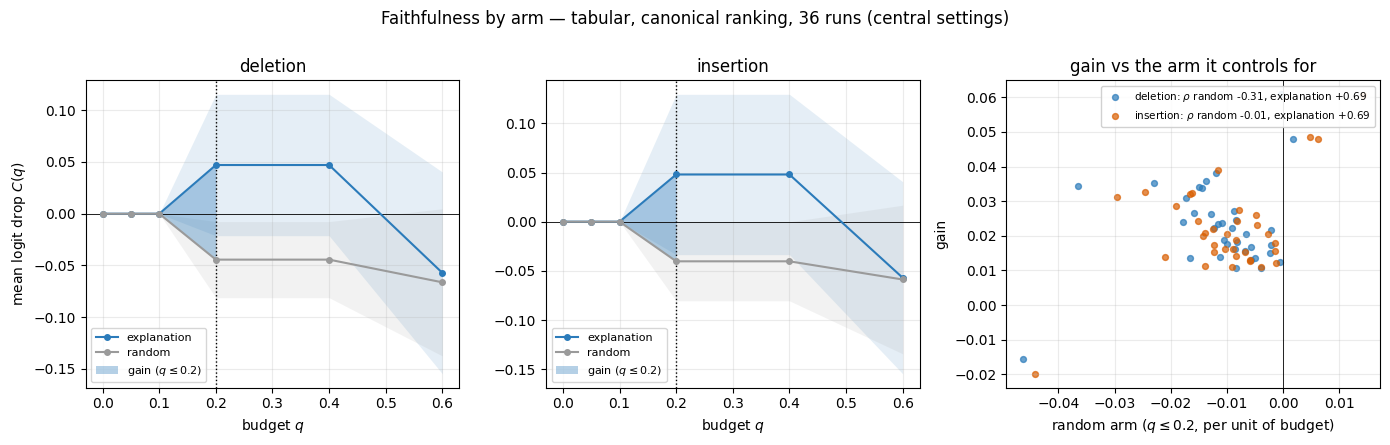

,del_exp,del_rand,del_gain,ins_exp,ins_rand,ins_gain
impl_name,,,,,,
adaptive_gating,0.023,-0.010,0.033,0.032,-0.002,0.034
controlled_fusion,0.001,-0.025,0.025,0.002,-0.022,0.024
fixed_scaling,0.010,-0.007,0.017,0.008,-0.008,0.016
learnable_scaling,0.008,-0.008,0.016,0.006,-0.009,0.015
loss_regularization,0.014,-0.008,0.022,0.012,-0.009,0.020
vanilla,0.015,-0.010,0.025,0.013,-0.010,0.024



canonical ranking — image
  [ablations] report figures: 12 unimodal endpoint runs excluded from the aggregate


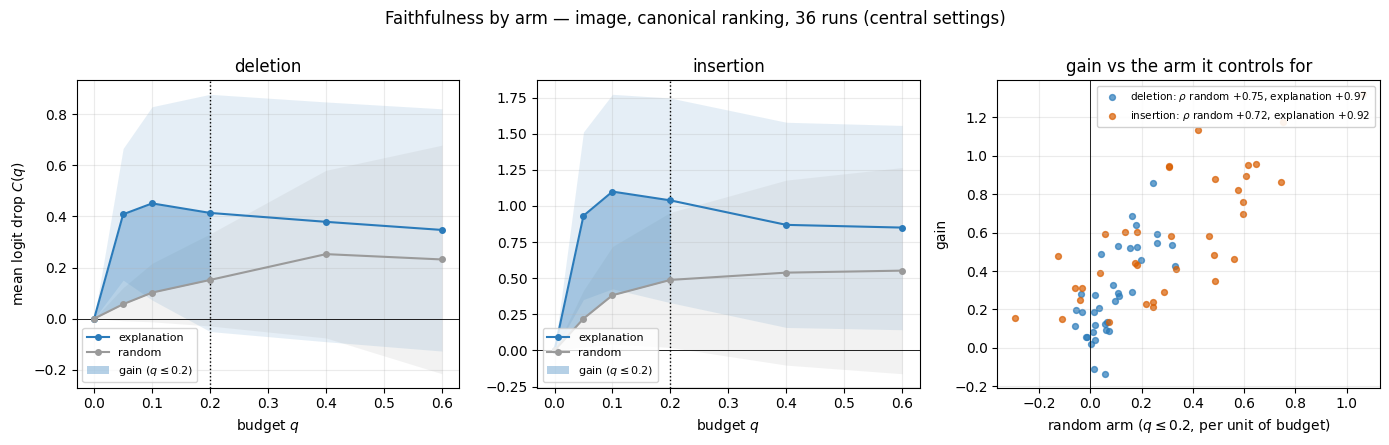

,del_exp,del_rand,del_gain,ins_exp,ins_rand,ins_gain
impl_name,,,,,,
adaptive_gating,0.737,0.208,0.528,0.470,0.108,0.362
controlled_fusion,0.562,0.104,0.458,0.505,0.116,0.390
fixed_scaling,0.058,0.044,0.014,1.205,0.492,0.713
learnable_scaling,0.225,0.035,0.190,1.257,0.512,0.746
loss_regularization,0.329,0.051,0.278,1.030,0.361,0.669
vanilla,0.337,0.098,0.238,0.961,0.333,0.628



canonical ranking — joint
  [ablations] report figures: 12 unimodal endpoint runs excluded from the aggregate


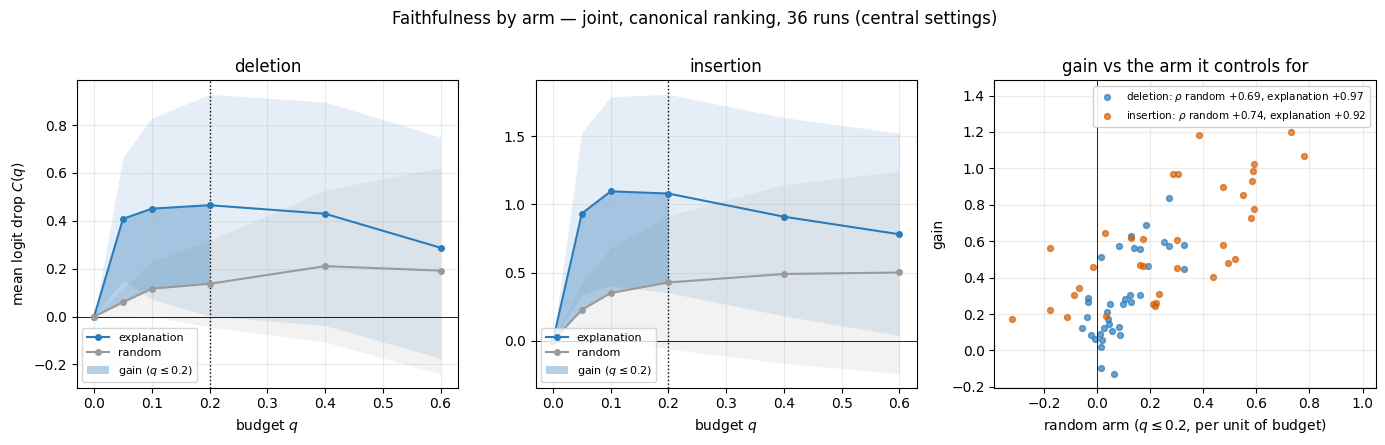

,del_exp,del_rand,del_gain,ins_exp,ins_rand,ins_gain
impl_name,,,,,,
adaptive_gating,0.767,0.214,0.553,0.486,0.073,0.413
controlled_fusion,0.563,0.100,0.462,0.507,0.074,0.433
fixed_scaling,0.068,0.047,0.021,1.213,0.476,0.736
learnable_scaling,0.233,0.047,0.186,1.263,0.490,0.773
loss_regularization,0.343,0.049,0.294,1.042,0.340,0.702
vanilla,0.352,0.100,0.252,0.975,0.312,0.663



gradient ranking — tabular
  [ablations] report figures: 12 unimodal endpoint runs excluded from the aggregate


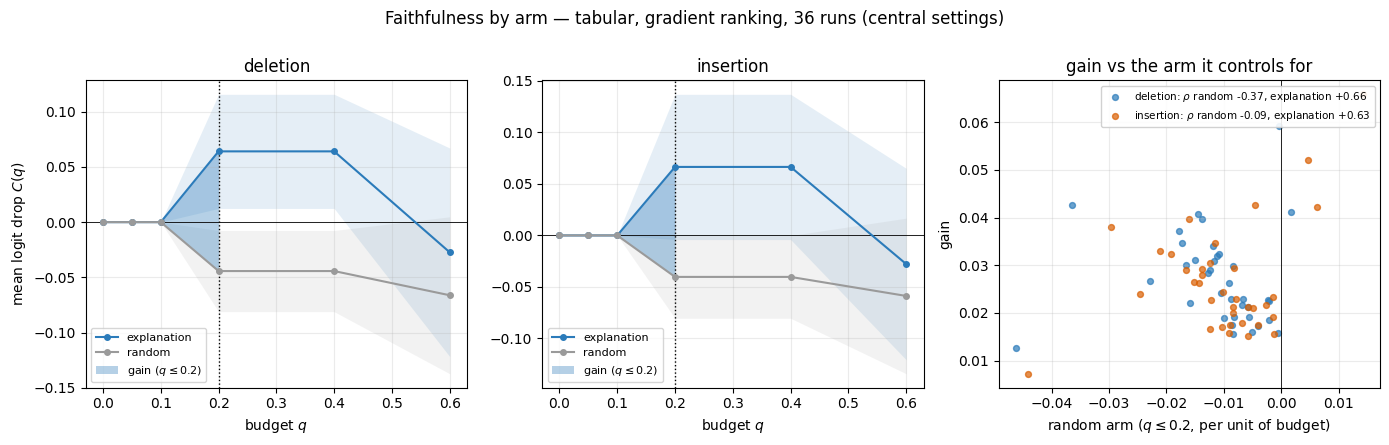

,del_exp,del_rand,del_gain,ins_exp,ins_rand,ins_gain
impl_name,,,,,,
adaptive_gating,0.030,-0.010,0.040,0.042,-0.002,0.044
controlled_fusion,0.005,-0.025,0.030,0.006,-0.022,0.027
fixed_scaling,0.013,-0.007,0.020,0.011,-0.008,0.019
learnable_scaling,0.012,-0.008,0.020,0.009,-0.009,0.019
loss_regularization,0.017,-0.008,0.025,0.015,-0.009,0.024
vanilla,0.018,-0.010,0.028,0.016,-0.010,0.026



gradient ranking — joint
  [ablations] report figures: 12 unimodal endpoint runs excluded from the aggregate


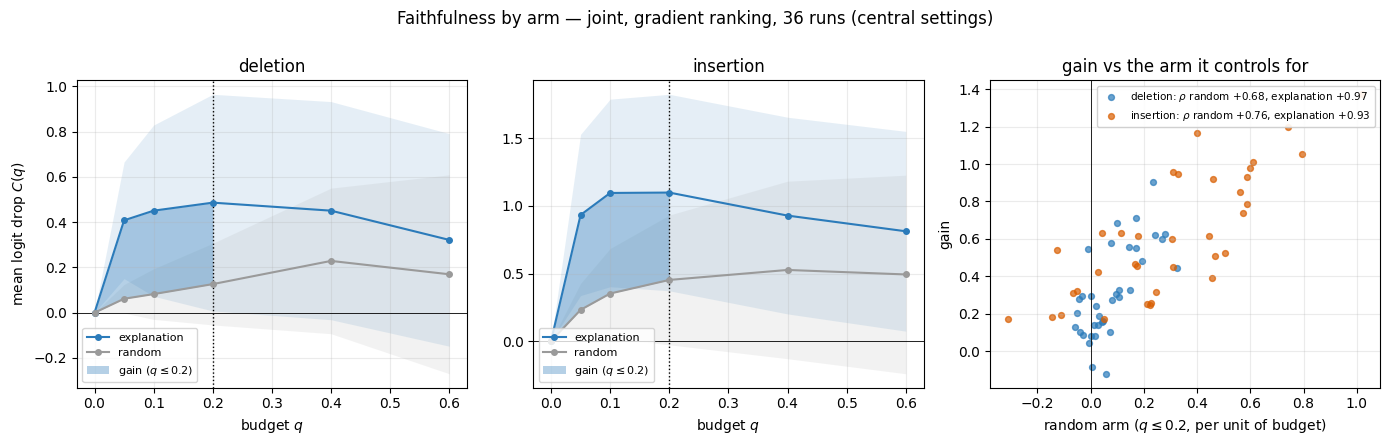

,del_exp,del_rand,del_gain,ins_exp,ins_rand,ins_gain
impl_name,,,,,,
adaptive_gating,0.780,0.196,0.584,0.497,0.090,0.407
controlled_fusion,0.567,0.075,0.492,0.511,0.089,0.422
fixed_scaling,0.071,0.033,0.038,1.216,0.477,0.740
learnable_scaling,0.237,0.035,0.201,1.267,0.492,0.775
loss_regularization,0.347,0.039,0.308,1.046,0.348,0.698
vanilla,0.355,0.089,0.266,0.978,0.322,0.656


In [ ]:
# @@REPORT_FIGURES@@ — the arm figures, the ones a table cannot carry (CPU, no checkpoint)
# Self-contained: paths and central settings come from the modules, so a fresh kernel is enough.
from isic24 import xai_faithfulness as xf, xai_figures as xfig

_ARM_COLS = ["del_exp", "del_rand", "del_gain", "ins_exp", "ins_rand", "ins_gain"]
for _src, _meths in xf.DEFAULT_METHODS.items():
    if _src == "aligned_signed":       # a sign convention, not a second attributor
        continue
    for _meth in _meths:
        print(f"\n{_src} ranking — {_meth}")
        display(xfig.arms(source=_src, method=_meth)
                .groupby("impl_name")[_ARM_COLS].mean().round(3))

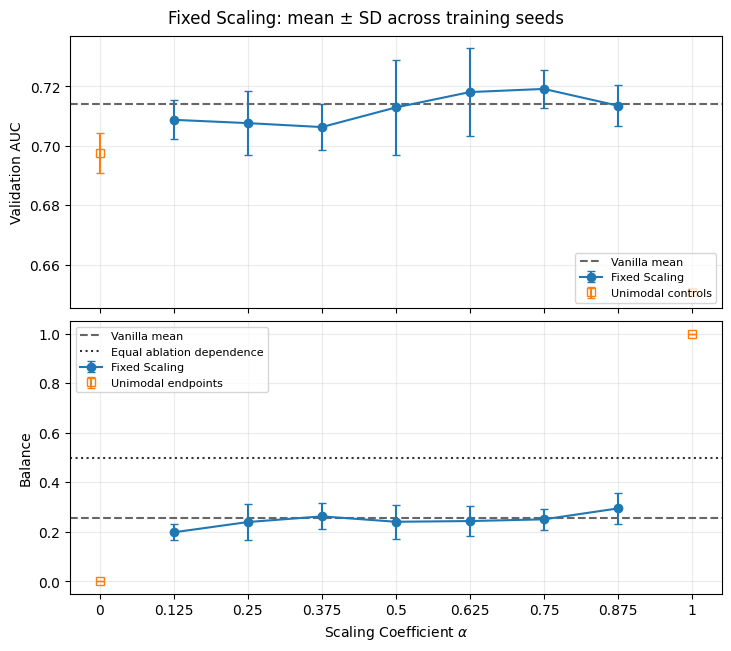

Saved: /mnt/disk1/home/cgiovannoni/mod-attendance/artifacts/cmmd/processed/figures/report/fig_fixed_scaling_auc_balance.png


: 

In [ ]:
# @@ATTENDANCE_FIGURE@@ — Plot validation AUC and ablation balance with separate unimodal controls.
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

_attendance_rows = pd.read_csv(Path(SUMMARIES_PATH) / "master_results_rows.csv")
_attendance_metrics = ["best_val_auc", "modality_balance"]
_attendance_fixed = _attendance_rows.loc[_attendance_rows.impl_name == "fixed_scaling"]
assert not _attendance_fixed.duplicated(["alpha", "seed"]).any(), "Duplicate fixed-scaling seed/alpha rows"
_attendance_summary = _attendance_fixed.groupby("alpha")[_attendance_metrics].agg(["mean", "std"])
_attendance_bimodal = _attendance_summary.loc[
    (_attendance_summary.index > 0) & (_attendance_summary.index < 1)
]
_attendance_controls = _attendance_summary.loc[[0.0, 1.0]]
_attendance_vanilla = _attendance_rows.loc[
    _attendance_rows.impl_name == "vanilla", _attendance_metrics
].mean()

_attendance_fig, _attendance_axes = plt.subplots(2, 1, sharex=True, figsize=(7.2, 6.4), layout="constrained")
for _ax, _metric, _ylabel, _control_label in zip(
    _attendance_axes, _attendance_metrics,
    ("Validation AUC", "Balance"),
    ("Unimodal controls", "Unimodal endpoints"),
):
    _ax.errorbar(
        _attendance_bimodal.index, _attendance_bimodal[(_metric, "mean")],
        yerr=_attendance_bimodal[(_metric, "std")], fmt="o-", capsize=3,
        color="C0", label="Fixed Scaling",
    )
    _ax.errorbar(
        _attendance_controls.index, _attendance_controls[(_metric, "mean")],
        yerr=_attendance_controls[(_metric, "std")], fmt="s", capsize=3,
        color="C1", markerfacecolor="none", label=_control_label,
    )
    _ax.axhline(_attendance_vanilla[_metric], color="0.4", linestyle="--", label="Vanilla mean")
    _ax.set_ylabel(_ylabel)
    _ax.grid(alpha=0.25)
_attendance_axes[1].axhline(0.5, color="0.2", linestyle=":", label="Equal ablation dependence")
_attendance_axes[1].set_ylim(-0.05, 1.05)
_attendance_axes[1].set_xticks(_attendance_summary.index, [f"{a:g}" for a in _attendance_summary.index])
_attendance_axes[1].set_xlabel(r"Scaling Coefficient $\alpha$")
_attendance_axes[0].legend(fontsize=8, loc="lower right")
_attendance_axes[1].legend(fontsize=8, loc="upper left")
_attendance_fig.suptitle("Fixed Scaling: mean ± SD across training seeds")
_attendance_output = Path(ART_PATH) / "figures" / "report" / "fig_fixed_scaling_auc_balance.png"
_attendance_output.parent.mkdir(parents=True, exist_ok=True)
_attendance_fig.savefig(_attendance_output, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved: {_attendance_output}")


In [ ]:
# @@LORE_SECTION@@ — aggregate the per-sample LORE CSVs SUBSET 3/3 wrote (CPU)
from isic24.run_ids import run_id_from_artifact

_lore_files = sorted(glob.glob(os.path.join(RUNS_PATH, "**", "xai", "lore_sa", "epoch*",
                                            "lore_sa_persample_*.csv"), recursive=True))
if not _lore_files:
    print("No `lore_sa` artifact yet: run `SUBSET 3/3`, which writes xai/lore_sa/.")
else:
    print(f"[LORE] {len(_lore_files)} runs from xai/lore_sa/")
    _master = pd.read_csv(os.path.join(SUMMARIES_PATH, "master_results_rows.csv"))
    _meta = {str(r.run_id): (r.impl_name, r.setting_tag, int(r.seed)) for _, r in _master.iterrows()}

    _rows, _unmatched = [], []
    for f in _lore_files:
        _rid = run_id_from_artifact(f)
        if _rid not in _meta:
            _unmatched.append(f"{_rid}   ({f})")
            continue
        d = pd.read_csv(f)
        d["run_id"] = _rid
        d["impl_name"], d["setting_tag"], d["seed"] = _meta[_rid]
        d["rng_protocol"] = "seeded-v2" if "rng_seed" in d.columns else "unseeded-v1"
        _rows.append(d)
    if _unmatched:
        raise RuntimeError("LORE artifacts absent from the canonical registry:\n  "
                           + "\n  ".join(_unmatched))

    L = pd.concat(_rows, ignore_index=True)
    L["covered"] = L["neigh_n_classes"] >= 2
    L["rule_len_covered"] = L["rule_len"].where(L["covered"])
    L["fid_cv_bacc_covered"] = L["fid_cv_bacc"].where(L["covered"])
    L["legacy_unseeded"] = L["rng_protocol"] == "unseeded-v1"

    fam = L.groupby(["impl_name", "setting_tag"]).agg(
        n_run=("run_id", "nunique"),
        n_samples=("i", "size"),
        lore_coverage=("covered", "mean"),
        neigh_pos_rate=("neigh_pos_rate", "mean"),
        neigh_unique_frac=("neigh_unique_frac", "mean"),
        rule_len_covered=("rule_len_covered", "mean"),
        fid_cv_bacc_covered=("fid_cv_bacc_covered", "mean"),
    )
    fam["n_covered"] = L.groupby(["impl_name", "setting_tag"])["covered"].sum()
    fam["n_legacy_runs"] = (L[L.legacy_unseeded]
        .groupby(["impl_name", "setting_tag"])["run_id"].nunique()
        .reindex(fam.index, fill_value=0).astype(int))
    print("\nLORE explanation quality by family "
          "(`lore_coverage` = how far the tabular branch drives the decision)")
    _controls = np.array([xs.is_ablation(i, t) for i, t in fam.index])
    display(fam.loc[~_controls].round(3))
    print("Unimodal controls (excluded from inference)")
    display(fam.loc[_controls].round(3))

    cw = (L.groupby(["impl_name", "setting_tag", "true_label"])
            .agg(n=("i", "size"), lore_coverage=("covered", "mean"),
                 neigh_pos_rate=("neigh_pos_rate", "mean"),
                 rule_len_covered=("rule_len_covered", "mean"),
                 fid_cv_bacc_covered=("fid_cv_bacc_covered", "mean"))
            .unstack("true_label"))
    _class_names = ("Benign", "Malignant")
    print(f"\nBy true class: 0 = {_class_names[0]}, 1 = {_class_names[1]}")
    display(cw.loc[fam.index[~_controls]].round(3))
    print("Unimodal controls (excluded from inference)")
    display(cw.loc[fam.index[_controls]].round(3))
    cw.reset_index().to_csv(
        os.path.join(RUNS_PATH, "_faithfulness", "lore_sa_quality_by_family_class.csv"),
        index=False)

    print("\nWithin-setting class contrasts: paired seeds; unadjusted exploratory p-values")
    _run_coverage = (L.groupby(["impl_name", "setting_tag", "seed", "true_label"])
                     ["covered"].mean().unstack("true_label").reindex(columns=[0, 1]))
    _contrasts = []
    for (_impl, _tag), _g in _run_coverage.groupby(level=["impl_name", "setting_tag"]):
        if xs.is_ablation(_impl, _tag):
            continue
        _paired = _g.dropna()
        _res = xs.across_runs(_paired[0], _paired[1], *_class_names)
        _res["n_seeds"] = _res.pop("n_run")
        _contrasts.append(dict(impl_name=_impl, setting_tag=_tag,
                               coverage_negative=_paired[0].mean(),
                               coverage_positive=_paired[1].mean(), **_res))
    _lore_contrasts = pd.DataFrame(_contrasts)
    display(_lore_contrasts.set_index(["impl_name", "setting_tag"])[[
        "n_seeds", "n_informative", "n_ties", "coverage_negative", "coverage_positive",
        "diff_mean", "diff_median", "n_positive", "sign_p", "wilcoxon_p", "p_floor",
    ]].round(4))

    _out = os.path.join(RUNS_PATH, "_faithfulness", "lore_sa_quality_by_family.csv")
    fam.reset_index().to_csv(_out, index=False)
    print("wrote", _out)
    print("`n_legacy_runs` exposes the accepted unseeded-v1 artifacts; all rule and CV "
          "summaries exclude mono-class neighbourhoods.")
    print("Both tables aggregate the run away, so they carry no provenance sidecar: the "
          "stamped version of the same numbers is what `xs.report` writes in @@SUBSET@@ 3/3.")

[LORE] 156 runs from xai/lore_sa/

LORE explanation quality by family (`lore_coverage` = how far the tabular branch drives the decision)


n_run  n_samples  lore_coverage  \
impl_name           setting_tag                                    
adaptive_gating     base             6        360          0.778   
                    ent0e+00         6        360          0.731   
                    ent1e-01         6        360          0.853   
                    ent1e-02         6        360          0.833   
                    ent1e-03         6        360          0.775   
controlled_fusion   base             6        360          0.778   
fixed_scaling       a0p125           6        360          0.417   
                    a0p250           6        360          0.544   
                    a0p375           6        360          0.600   
                    a0p500           6        360          0.742   
                    a0p625           6        360          0.700   
                    a0p750           6        360          0.814   
                    a0p875           6        360          0.725   
learnable_scaling   init_a0p100      6        360          0.292   
                    init_a0p300      6        360          0.650   
                    init_a0p500      6        360          0.658   
                    init_a0p700      6        360          0.561   
                    init_a0p900      6        360          0.719   
loss_regularization lam0e+00         6        360          0.750   
                    lam1e-02         6        360          0.678   
                    lam1e-03         6        360          0.650   
                    lam1e-04         6        360          0.683   
                    lam1e-05         6        360          0.697   
vanilla             baseline         6        360          0.692   

                                 neigh_pos_rate  neigh_unique_frac  \
impl_name           setting_tag                                      
adaptive_gating     base                  0.626              0.339   
                    ent0e+00              0.599              0.338   
                    ent1e-01              0.624              0.339   
                    ent1e-02              0.626              0.339   
                    ent1e-03              0.605              0.338   
controlled_fusion   base                  0.582              0.338   
fixed_scaling       a0p125                0.686              0.333   
                    a0p250                0.682              0.335   
                    a0p375                0.643              0.336   
                    a0p500                0.578              0.338   
                    a0p625                0.593              0.337   
                    a0p750                0.593              0.339   
                    a0p875                0.646              0.337   
learnable_scaling   init_a0p100           0.728              0.331   
                    init_a0p300           0.668              0.336   
                    init_a0p500           0.641              0.336   
                    init_a0p700           0.643              0.335   
                    init_a0p900           0.637              0.337   
loss_regularization lam0e+00              0.615              0.338   
                    lam1e-02              0.602              0.337   
                    lam1e-03              0.683              0.337   
                    lam1e-04              0.627              0.337   
                    lam1e-05              0.599              0.337   
vanilla             baseline              0.608              0.336   

                                 rule_len_covered  fid_cv_bacc_covered  \
impl_name           setting_tag                                          
adaptive_gating     base                    1.486                0.998   
                    ent0e+00                1.456                0.998   
                    ent1e-01                1.414                0.998   
                    ent1e-02                1.507                0.998   

Unimodal controls (excluded from inference)


n_run  n_samples  lore_coverage  neigh_pos_rate  \
impl_name     setting_tag                                                    
fixed_scaling a0p000           6        360            0.0           0.678   
              a1p000           6        360            1.0           0.617   

                           neigh_unique_frac  rule_len_covered  \
impl_name     setting_tag                                        
fixed_scaling a0p000                   0.327               NaN   
              a1p000                   0.343             1.442   

                           fid_cv_bacc_covered  n_covered  n_legacy_runs  
impl_name     setting_tag                                                 
fixed_scaling a0p000                       NaN          0              0  
              a1p000                     0.998        360              0


By true class: 0 = Benign, 1 = Malignant


n      lore_coverage        neigh_pos_rate  \
true_label                         0    1             0      1              0   
impl_name           setting_tag                                                 
adaptive_gating     base         180  180         0.833  0.722          0.573   
                    ent0e+00     180  180         0.783  0.678          0.536   
                    ent1e-01     180  180         0.900  0.806          0.584   
                    ent1e-02     180  180         0.900  0.767          0.586   
                    ent1e-03     180  180         0.789  0.761          0.563   
controlled_fusion   base         180  180         0.844  0.711          0.523   
fixed_scaling       a0p125       180  180         0.489  0.344          0.598   
                    a0p250       180  180         0.606  0.483          0.632   
                    a0p375       180  180         0.683  0.517          0.577   
                    a0p500       180  180         0.844  0.639          0.519   
                    a0p625       180  180         0.761  0.639          0.529   
                    a0p750       180  180         0.911  0.717          0.530   
                    a0p875       180  180         0.811  0.639          0.589   
learnable_scaling   init_a0p100  180  180         0.389  0.194          0.639   
                    init_a0p300  180  180         0.750  0.550          0.605   
                    init_a0p500  180  180         0.728  0.589          0.577   
                    init_a0p700  180  180         0.661  0.461          0.576   
                    init_a0p900  180  180         0.817  0.622          0.568   
loss_regularization lam0e+00     180  180         0.856  0.644          0.550   
                    lam1e-02     180  180         0.739  0.617          0.526   
                    lam1e-03     180  180         0.767  0.533          0.616   
                    lam1e-04     180  180         0.783  0.583          0.561   
                    lam1e-05     180  180         0.761  0.633          0.532   
vanilla             baseline     180  180         0.761  0.622          0.545   

                                       rule_len_covered         \
true_label                           1                0      1   
impl_name           setting_tag                                  
adaptive_gating     base         0.679            1.467  1.508   
                    ent0e+00     0.661            1.518  1.385   
                    ent1e-01     0.664            1.401  1.428   
                    ent1e-02     0.666            1.549  1.457   
                    ent1e-03     0.648            1.465  1.453   
controlled_fusion   base         0.642            1.487  1.492   
fixed_scaling       a0p125       0.774            1.420  1.387   
                    a0p250       0.733            1.385  1.563   
                    a0p375       0.709            1.537  1.581   
                    a0p500       0.638            1.441  1.548   
                    a0p625       0.657            1.460  1.487   
                    a0p750       0.655            1.457  1.434   
                    a0p875       0.702            1.438  1.522   
learnable_scaling   init_a0p100  0.817            1.386  1.514   
                    init_a0p300  0.731            1.444  1.354   
                    init_a0p500  0.705            1.573  1.453   
                    init_a0p700  0.711            1.555  1.542   
                    init_a0p900  0.706            1.347  1.554   
loss_regularization lam0e+00     0.680            1.455  1.397   
                    lam1e-02     0.677            1.451  1.405   
                    lam1e-03     0.750            1.399  1.406   
                    lam1e-04     0.693            1.433  1.429   
                    lam1e-05     0.666            1.409  1.377   
vanilla             baseline     0.672            1.489  1.455   

                                fid_cv_bacc_covered         
tru

Unimodal controls (excluded from inference)


n      lore_coverage      neigh_pos_rate         \
true_label                   0    1             0    1              0      1   
impl_name     setting_tag                                                      
fixed_scaling a0p000       180  180           0.0  0.0          0.611  0.744   
              a1p000       180  180           1.0  1.0          0.610  0.623   

                          rule_len_covered        fid_cv_bacc_covered         
true_label                               0      1                   0      1  
impl_name     setting_tag                                                     
fixed_scaling a0p000                   NaN    NaN                 NaN    NaN  
              a1p000                 1.494  1.389               0.998  0.999


Within-setting class contrasts: paired seeds; unadjusted exploratory p-values


n_seeds  n_informative  n_ties  \
impl_name           setting_tag                                   
adaptive_gating     base               6              5       1   
                    ent0e+00           6              5       1   
                    ent1e-01           6              6       0   
                    ent1e-02           6              5       1   
                    ent1e-03           6              5       1   
controlled_fusion   base               6              6       0   
fixed_scaling       a0p125             6              5       1   
                    a0p250             6              6       0   
                    a0p375             6              6       0   
                    a0p500             6              6       0   
                    a0p625             6              6       0   
                    a0p750             6              6       0   
                    a0p875             6              6       0   
learnable_scaling   init_a0p100        6              6       0   
                    init_a0p300        6              6       0   
                    init_a0p500        6              6       0   
                    init_a0p700        6              6       0   
                    init_a0p900        6              6       0   
loss_regularization lam0e+00           6              6       0   
                    lam1e-02           6              5       1   
                    lam1e-03           6              6       0   
                    lam1e-04           6              6       0   
                    lam1e-05           6              6       0   
vanilla             baseline           6              6       0   

                                 coverage_negative  coverage_positive  \
impl_name           setting_tag                                         
adaptive_gating     base                    0.8333             0.7222   
                    ent0e+00                0.7833             0.6778   
                    ent1e-01                0.9000             0.8056   
                    ent1e-02                0.9000             0.7667   
                    ent1e-03                0.7889             0.7611   
controlled_fusion   base                    0.8444             0.7111   
fixed_scaling       a0p125                  0.4889             0.3444   
                    a0p250                  0.6056             0.4833   
                    a0p375                  0.6833             0.5167   
                    a0p500                  0.8444             0.6389   
                    a0p625                  0.7611             0.6389   
                    a0p750                  0.9111             0.7167   
                    a0p875                  0.8111             0.6389   
learnable_scaling   init_a0p100             0.3889             0.1944   
                    init_a0p300             0.7500             0.5500   
                    init_a0p500             0.7278             0.5889   
                    init_a0p700             0.6611             0.4611   
                    init_a0p900             0.8167             0.6222   
loss_regularization lam0e+00                0.8556             0.6444   
                    lam1e-02                0.7389             0.6167   
                    lam1e-03                0.7667             0.5333   
                    lam1e-04                0.7833             0.5833   
                    lam1e-05                0.7611             0.6333   
vanilla             baseline                0.7611             0.6222   

                                 diff_mean  diff_median  n_positive  sign_p  \
impl_name           setting_tag                                               
adaptive_gating     base           -0.1111      -0.1167           1  0.3750   
                    ent0e+00       -0.1056      -0.0833           1  0.3750   
                    ent1e-01       -0.0944      -0.0667           0  0.0312

wrote /mnt/disk1/home/cgiovannoni/mod-attendance/artifacts/cmmd/processed/runs/_faithfulness/lore_sa_quality_by_family.csv
`n_legacy_runs` exposes the accepted unseeded-v1 artifacts; all rule and CV summaries exclude mono-class neighbourhoods.
Both tables aggregate the run away, so they carry no provenance sidecar: the stamped version of the same numbers is what `xs.report` writes in @@SUBSET@@ 3/3.


In [ ]:
# @@CAM_OVERLAP@@ — do two families look in the same places more than two seeds do?
import importlib
from isic24 import xai_metrics as xmet

importlib.reload(xmet)

_ov = xmet.cam_overlap_table(pd.read_csv(os.path.join(SUMMARIES_PATH, "master_results_rows.csv")),
                             ART_PATH, central=xs.CENTRAL_SETTINGS,
                             out_dir=os.path.join(RUNS_PATH, "_faithfulness"), archive_legacy=True)
display(_ov.groupby("pair_kind")[["iou_half", "iou_top"]].agg(["median", "mean", "count"]).round(3))
print("the counts above are PAIRS: this table describes, it does not test")

_contrast = pd.concat([xmet.seed_level_contrast(_ov, c, "cross_family", "seed_null").assign(iou=c)
                       for c in ("iou_half", "iou_top")], ignore_index=True)
print("\nCross-family against the seed null, with the SEED as the unit")
display(_contrast.set_index("iou").round(4))
print(f"{int(_contrast.n_seeds.max())} seeds put the floor at p = {_contrast.p_floor.max():.3f};")
print("positive diff = two FAMILIES overlap more than two seeds of one family do.")

iou_half              iou_top             
               median   mean count  median   mean count
pair_kind                                              
cross_family      0.5  0.514    90    0.75  0.663    90
seed_null         0.5  0.510    90    0.75  0.701    90

the counts above are PAIRS: this table describes, it does not test

Cross-family against the seed null, with the SEED as the unit


,n_seeds,effect_mean,effect_sd,null_mean,null_sd,diff_mean,n_positive,sign_p,wilcoxon_p,p_floor
iou,,,,,,,,,,
iou_half,6,0.5138,0.0236,0.5100,0.0067,0.0039,2,0.6875,0.9375,0.0312
iou_top,6,0.6629,0.0318,0.7014,0.0136,-0.0385,0,0.0312,0.0312,0.0312


6 seeds put the floor at p = 0.031;
positive diff = two FAMILIES overlap more than two seeds of one family do.


In [ ]:
# @@SHAPE@@ — explanation-shape metrics and stability, from the artifacts on disk
import pandas as pd, os
from isic24 import xai_metrics as xmet

_m = pd.read_csv(os.path.join(SUMMARIES_PATH, "master_results_rows.csv"))

_out = xs.report(_m, ART_PATH, kinds=(), central=CENTRAL_SETTINGS,
                 encoded_feature_names=encoded_feature_names, shape_top_k=CFG.shape_top_k)
_shape, _stab, _fam = _out["shape"], _out["stability"], _out["by_family"]
print(f"\n[shape] {len(_shape)} runs | {len(_stab)} pairs | "
      f"{int(_shape.branch_off.sum())} runs with the tabular branch off (metrics = NaN)")

print("\nStability@k by pair kind — the pair is the unit here, and this table describes")
display(_stab.pivot_table(index="impl_name", columns="pair_kind", values="stability_at_k",
                          aggfunc=["mean", "count"]).round(3))

_contrast = xmet.seed_level_contrast(_stab, "stability_at_k", "adjacent_param",
                                     "same_param_seed", by="impl_name")
print("\nThe same contrast with the SEED as the unit — this one tests")
display(_contrast.set_index("impl_name").round(4))
print("positive diff = one step of the knob moves the top-k features LESS than the seed does;")
print("Tests use paired seed differences; zero differences are excluded and p_floor uses the informative count.")
print("Families with a single setting have no adjacent-parameter arm and no contrast.")

print("\nall metrics side by side")
display(_fam.round(3))

[report] 3 files in /mnt/disk1/home/cgiovannoni/mod-attendance/artifacts/cmmd/processed/runs/_faithfulness
    xai_shape_metrics.csv
    xai_stability.csv
    xai_summary_by_family.csv

[shape] 156 runs | 468 pairs | 6 runs with the tabular branch off (metrics = NaN)

Stability@k by pair kind — the pair is the unit here, and this table describes


mean                          count  \
pair_kind           adjacent_param same_param_seed adjacent_param   
impl_name                                                           
adaptive_gating              0.755           0.692           24.0   
controlled_fusion              NaN           0.611            NaN   
fixed_scaling                0.873           0.760           36.0   
learnable_scaling            0.843           0.777           24.0   
loss_regularization          0.821           0.667           24.0   
vanilla                        NaN           0.661            NaN   

                                     
pair_kind           same_param_seed  
impl_name                            
adaptive_gating                75.0  
controlled_fusion              15.0  
fixed_scaling                 105.0  
learnable_scaling              75.0  
loss_regularization            75.0  
vanilla                        15.0

  [seed unit] no 'adjacent_param' arm, so no contrast: controlled_fusion, vanilla

The same contrast with the SEED as the unit — this one tests


,n_seeds,effect_mean,effect_sd,null_mean,null_sd,diff_mean,n_positive,sign_p,wilcoxon_p,p_floor
impl_name,,,,,,,,,,
adaptive_gating,6,0.7548,0.0326,0.6922,0.0363,0.0626,5,0.2188,0.0625,0.0312
fixed_scaling,6,0.8725,0.0542,0.7597,0.0350,0.1128,6,0.0312,0.0312,0.0312
learnable_scaling,6,0.8431,0.0614,0.7766,0.0343,0.0666,5,0.2188,0.0938,0.0312
loss_regularization,6,0.8207,0.0845,0.6670,0.0384,0.1537,6,0.0312,0.0312,0.0312


positive diff = one step of the knob moves the top-k features LESS than the seed does;
Tests use paired seed differences; zero differences are excluded and p_floor uses the informative count.
Families with a single setting have no adjacent-parameter arm and no contrast.

all metrics side by side


,n_runs,faith_target_q20,faith_posev_q20,lore_coverage,lore_rule_len,shape__shap_compactness,shape__shap_k90_sparsity,shape__shap_mass,shape__lore_rule_compactness,shape__agreement_shap_lore,shape__agreement_n_overlap,shape__lore_n,shape__lore_samples,shape__stability_adjacent,shape__stability_seed_null,shape__stability_effect
impl_name,,,,,,,,,,,,,,,,
adaptive_gating,6,0.108,0.114,0.778,1.492,0.481,0.638,35.528,0.759,0.405,60.0,60,1,0.755,0.692,-0.063
controlled_fusion,6,0.130,0.135,0.778,1.487,0.445,0.624,57.535,0.757,0.416,60.0,60,1,NaN,0.611,NaN
fixed_scaling,6,0.089,0.090,0.742,1.495,0.533,0.682,38.820,0.758,0.381,60.0,60,1,0.873,0.760,-0.113
learnable_scaling,6,0.087,0.088,0.658,1.509,0.519,0.665,40.977,0.742,0.352,60.0,60,1,0.843,0.777,-0.067
loss_regularization,6,0.095,0.097,0.650,1.408,0.501,0.650,43.069,0.799,0.342,60.0,60,1,0.821,0.667,-0.154
vanilla,6,0.105,0.107,0.692,1.469,0.513,0.667,44.610,0.763,0.362,60.0,60,1,NaN,0.661,NaN


: 